# Phase 2 — Pre-processing, Baseline Model and Features Selection

---

## Phase Objectives

This Phase rapresents the bridge between the pipeline construction dataset (phase 1) and
predicting model training (phases 3-6). The operation carried out are:

1. **Strict Pre-processing** of data with anti-leakage method
2. **Baseline comparison** between models of different complexity (linear vs not-linear)
3. **Selection of Reduced Feature Set** aimed at training the final model

## Methodological notes and research path

The feature selection adopted in this final version is the result of an interactive process that deserves to be documented for scientific transparency.

Initially I tested a classic method ispired by Lopez de Prado ("Advances in
Financial Machine Learning", 2018), based on Permutation Importance of Random Forest
combined with Spearman collinearity filter
. This method, empirically validated  on
 linear models and on Random Forest standalone, has product a Reduced Feature Set of 12
variables. However, the next experiments (summarized in the Section 4) showed that this set resulted sub-ottimale for the final model XGBoost.

The theoretical explanation of this result is documented in literature (Gu, Kelly, Xiu,
"Empirical Asset Pricing via Machine Learning", Review of Financial Studies, 2020):  **Gradient Boosting** 's models have an intrinsic capacity to enhance the feature
with weak signal through sequential error connection mechanism, while selection method based on  **Bagging** (as Random Forest) tend to discard these features
 as noise. The feature selection is so **model-dependent**.

In this final version I adopted a selection pipeline  XGBoost-native,
based on internal importance metrics  (Gain) and validated through SHAP
values calculated out-of-sample.

## Notebook Structure

| Section | Content |
|---|---|
| 0 | Work environment setup |
| 1 | Dataset loading and target variables analysis  |
| 2 | Pre-processing: feature set, imputation, scaling, CV |
| 3 | Baseline Models: Logistic Regression e Random Forest |
| 4 |  Reduced Feature Set selection (XGBoost-native method) |
| 5 | Saving artifacts |

> **Input**: `dataset_train.csv`, `dataset_test.csv` (from Phase 1: Data-Pipeline)


---
## Section 0 — Work environment set up

**Methodological Note - Execution Architecture and Artifact Management**:

During the initial development phase and intensive training, this project was structured using an iterative checkpointing system. Trained models and intermediate results were dynamically saved to Google Drive to optimize computational time and avoid full code re-execution during each session.

However, for the purpose of academic evaluation, the notebook's architecture has been deliberately modified to operate in a completely isolated sandbox environment.

To ensure a seamless execution experience and, most importantly, to avoid occupying or altering the evaluator's personal Google Drive storage in any way, the code execution path has been redirected. All artifacts generated during the run (e.g., .pkl models, charts, and comparative .csv files) are now saved exclusively to Google Colab's local volatile memory (/content/).

The "Checkpoint cells" were updated following the same logic.

**Execution Instructions**:

 1) Open the "Files" panel.

2) Upload the required input files (dataset_train.csv and dataset_test.csv).

3) Run the notebook.

4) Upon ending the session or closing the page, all generated files and models will be automatically destroyed, leaving your cloud environment perfectly intact.


In [ ]:
# =============================================================================
# Setup — Project path configuration
# =============================================================================
# This notebook expects two input files in the working directory:
#   - dataset_train.csv  (training set 2013-2023)
#   - dataset_test.csv   (test set 2024-2025)
# =============================================================================

import os

# from google.colab import drive
# drive.mount('/content/drive')
# PROGETTO_PATH = '/content/drive/MyDrive/Progetto_ML/'

PROGETTO_PATH = '/content/'  # default: current Colab session

print(f"Working directory: {PROGETTO_PATH}")
print(f"\nRequired input files:")
print(f"  - dataset_train.csv")
print(f"  - dataset_test.csv")
print(f"\nFiles found in directory:")
for f in sorted(os.listdir(PROGETTO_PATH)):
    if f.endswith('.csv') or f.endswith('.pkl') or f.endswith('.json'):
        print(f"  - {f}")

Working directory: /content/

Required input files:
  - dataset_train.csv
  - dataset_test.csv

Files found in directory:


In [ ]:
# =============================================================================
# Libraries Installation
# =============================================================================
!pip install -q xgboost shap joblib scikit-learn --upgrade

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.6/57.6 MB 9.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 28.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.0/216.0 MB 6.1 MB/s eta 0:00:00


In [ ]:
# =============================================================================
# Import libraries
# =============================================================================

# Data manipulation
import pandas as pd
import numpy as np
import json, time, warnings
warnings.filterwarnings('ignore')

# Visualizzation
import matplotlib.pyplot as plt
import matplotlib.dates  as mdates
import matplotlib.patches as mpatches
from matplotlib.gridspec import GridSpec
from scipy import stats as scipy_stats

# Pre-processing e CV
from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
import shap

# Metrics
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    precision_score, recall_score, f1_score,
    accuracy_score, roc_auc_score, roc_curve,
)

# Serialization
import joblib

# Display configuration
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', '{:,.4f}'.format)
plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['axes.grid']      = True
plt.rcParams['grid.alpha']     = 0.3

print("Librerie importate correttamente.")
print(f"  scikit-learn : {__import__('sklearn').__version__}")
print(f"  xgboost      : {xgb.__version__}")
print(f"  shap         : {shap.__version__}")

Librerie importate correttamente.
  scikit-learn : 1.8.0
  xgboost      : 3.2.0
  shap         : 0.51.0


---
## Section 1— Dataset loading and target analysis

We upload the checkpoint files procuced by the pipeline in phase 1. The dataset is temporally divided into a training set (2013-2023) and test set (2024-2025) in order to avoid any form of look-ahead bias.

In [ ]:
# =============================================================================
# Dataset loading
# =============================================================================

df_train = pd.read_csv(PROGETTO_PATH + 'dataset_train.csv', parse_dates=['date'])
df_test  = pd.read_csv(PROGETTO_PATH + 'dataset_test.csv',  parse_dates=['date'])

df_train['date'] = pd.to_datetime(df_train['date'])
df_test['date']  = pd.to_datetime(df_test['date'])

print("=" * 60)
print(" DATASET OVERVIEW")
print("=" * 60)
for nome, df in [("TRAINING (2013-2023)", df_train),
                  ("TEST     (2024-2025)", df_test)]:
    print(f"\n  {nome}")
    print(f"   Rows:    {len(df):,}")
    print(f"   Columns:  {df.shape[1]}")
    print(f"   Ticker:   {df['ticker'].nunique()}")
    print(f"   Period:  {df['date'].min().date()} → {df['date'].max().date()}")

# Check target availability
print(f"\n  Target variables available in the training set:")
for t in ['target_binary', 'target_multiclass']:
    if t in df_train.columns:
        n = df_train[t].notna().sum()
        print(f"   - {t:<22} {n:,} valori non-NaN")

 DATASET OVERVIEW

  TRAINING (2013-2023)
   Rows:    100,750
   Columns:  68
   Ticker:   43
   Period:  2013-01-03 → 2023-12-29

  TEST     (2024-2025)
   Rows:    21,543
   Columns:  68
   Ticker:   43
   Period:  2024-01-02 → 2025-12-30

  Target variables available in the training set:
   - target_binary          100,750 valori non-NaN
   - target_multiclass      100,406 valori non-NaN


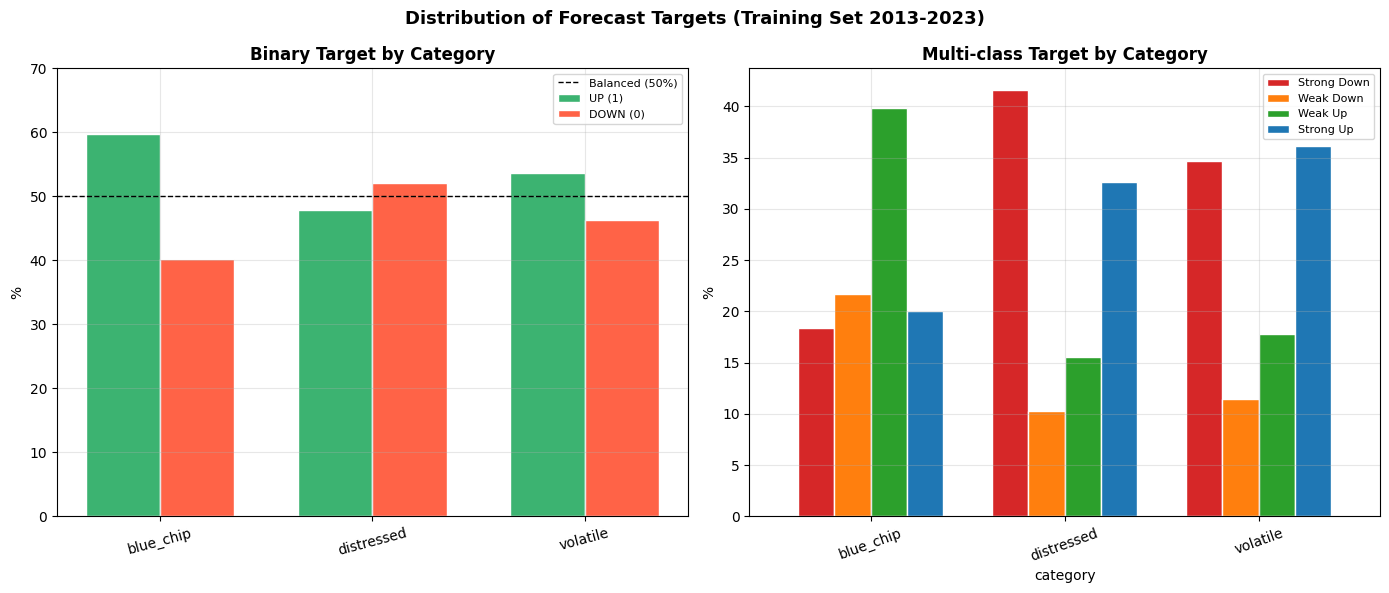

 STATISTICAL CHARACTERISTICS OF THE TARGETS

  Binary Target:
   % UP: 56.79%   % DOWN: 43.21%
   Distribution naturally slightly skewed towards UP (market drift).

  Multi-class Target (defined on the quartiles of the training set):
   0 - Strong Down    25.0%
   1 - Weak Down      18.0%
   2 - Weak Up        32.0%
   3 - Strong Up      25.0%


In [ ]:
# =============================================================================
# Analysis of the target variables
# =============================================================================
# The project includes two forecast targets, each used in a specific phase:
#   - target_binary     - classification UP/DOWN (phase 3)
#   - target_multiclass - classification at 4 intensity levels (phase 4)
# =============================================================================

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --- 1. Binary Target Distribution ---
cat_bal = df_train.groupby('category')['target_binary'].agg(
    pct_up=lambda x: x.mean()*100,
    pct_down=lambda x: (1-x.mean())*100
).reset_index()

x = np.arange(len(cat_bal))
w = 0.35
axes[0].bar(x-w/2, cat_bal['pct_up'],   w, color='mediumseagreen', label='UP (1)',  edgecolor='white')
axes[0].bar(x+w/2, cat_bal['pct_down'], w, color='tomato',         label='DOWN (0)', edgecolor='white')
axes[0].set_xticks(x); axes[0].set_xticklabels(cat_bal['category'], rotation=15)
axes[0].axhline(50, color='black', ls='--', lw=1, label='Balanced (50%)')
axes[0].set_title('Binary Target by Category', fontweight='bold')
axes[0].set_ylabel('%')
axes[0].legend(fontsize=8)
axes[0].set_ylim(0, 70)

# --- 2. Multi-class Target Distribution ---
mc_dist = df_train.groupby(['category','target_multiclass']).size().unstack(fill_value=0)
mc_pct  = mc_dist.div(mc_dist.sum(axis=1), axis=0) * 100
colors_mc = ['#d62728','#ff7f0e','#2ca02c','#1f77b4']

mc_pct.plot(kind='bar', ax=axes[1], color=colors_mc, edgecolor='white', width=0.75)
axes[1].set_title('Multi-class Target by Category', fontweight='bold')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=20)
axes[1].set_ylabel('%')
axes[1].legend(['Strong Down','Weak Down','Weak Up','Strong Up'],
                fontsize=8, bbox_to_anchor=(1,1))

plt.suptitle('Distribution of Forecast Targets (Training Set 2013-2023)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# --- 3. Print Statistical Characteristics ---
print("=" * 60)
print(" STATISTICAL CHARACTERISTICS OF THE TARGETS")
print("=" * 60)

bal = df_train['target_binary'].mean()
print(f"\n  Binary Target:")
print(f"   % UP: {bal*100:.2f}%   % DOWN: {(1-bal)*100:.2f}%")
print(f"   Distribution naturally slightly skewed towards UP (market drift).")

labels = {0:'Strong Down', 1:'Weak Down', 2:'Weak Up', 3:'Strong Up'}
dist   = df_train['target_multiclass'].value_counts(normalize=True).sort_index()
print(f"\n  Multi-class Target (defined on the quartiles of the training set):")
for cls, pct in dist.items():
    print(f"   {int(cls)} - {labels[int(cls)]:<14} {pct*100:.1f}%")

---
## Section 2 — Pre-processing

The pre-processing strictly follows the anti-leakage principle: all statistics (medians, scaling parameters) are computed **exclusively on the training set** and  then applied unchanged to the test observations. This would expose the model to information unavailable in production, leading to biased validation metrics.

In [ ]:
# =============================================================================
# Definition of the initial feature set
# =============================================================================
# We exclude four groups of columns from the feature set:
#
#   KEYS         non predictive identifiers (ticker, date, category)
#   NON_STAZ.    absolute prices and raw fundamentals (non stationary, contain
#                information about title "dimension" which doesn't generalise)
#   TARGET       dipendent variables (impossible to use as predictor)
#   FLAG         technical columns for row filtering (es. warm-up period)
# =============================================================================

COLS_KEYS = ['ticker', 'date', 'category']

COLS_NON_STAZIONARIE = [
    'open','high','low','close','volume',
    'revenue','net_income','ebit','total_assets','equity',
    'total_liabilities','working_capital','retained_earnings',
    'shares','current_assets','current_liabilities','sp500_level',
]

COLS_TARGET = ['target_binary','target_multiclass','fwd_ret_21d','fwd_ret_5d']

COLS_FLAG = [
    'has_fundamentals','is_warm_up','is_distress_zone',
    'date_rank','publish_date','report_date','up_day',
]

# x3_altman excluded due to missing EBIT data.
# Column removed because we found all values were missing.
# In download phase weren't download structural data about EBIT
# We don't know the reason, we believe it may depend on a different configuration of financial statements.
# Or weren't present on YahooFinance.
COLS_EMPTY = [
    'x3_altman'
]

COLS_ESCLUSE = set(COLS_KEYS + COLS_NON_STAZIONARIE + COLS_TARGET + COLS_FLAG + COLS_EMPTY)

FEATURE_COLS = [c for c in df_train.columns if c not in COLS_ESCLUSE]

def assegna_gruppo(feat):
    """Assegna una feature a uno dei gruppi tematici per l'analisi."""
    if any(k in feat for k in ['ret','mom','excess']):
        return 'Rendimenti e Momentum'
    if any(k in feat for k in ['rsi','macd','bb_','atr','golden','cross','sma','price_to']):
        return 'Indicatori Tecnici'
    if any(k in feat for k in ['volatility','vol_','rel_vol','intraday','beta']):
        return 'Volatilita e Volume'
    if any(k in feat for k in ['margin','leverage','roa','roe','current_ratio',
                                'altman','x1_','x2_','x3_','x4_','x5_']):
        return 'Fondamentali e Altman-Z'
    if any(k in feat for k in ['vix','tbill','treasury','cpi','term_spread',
                                'unemployment','oil','sp500']):
        return 'Macro'
    return 'Altro'

print("=" * 60)
print(" INITIAL FEATURE SET ")
print("=" * 60)
print(f"\n  Total features considered: {len(FEATURE_COLS)}")
print(f"  Feature excluded:             {len(COLS_ESCLUSE)}\n")

gruppi = {}
for f in FEATURE_COLS:
    g = assegna_gruppo(f)
    gruppi.setdefault(g, []).append(f)
for grp, feats in gruppi.items():
    print(f"  [{grp}] ({len(feats)} feature)")
print(f"   {', '.join(feats)}")

 INITIAL FEATURE SET 

  Total features considered: 44
  Feature excluded:             32

  [Rendimenti e Momentum] (9 feature)
  [Indicatori Tecnici] (11 feature)
  [Volatilita e Volume] (7 feature)
  [Fondamentali e Altman-Z] (10 feature)
  [Macro] (7 feature)
   vix, tbill_3m, treasury_10y, cpi_yoy, term_spread, unemployment, oil_wti


In [ ]:
# =============================================================================
# Matrix construction X/y, imputation, scaling
# =============================================================================
# Warm-up period removal from training: the first 63 observations for each ticker
# have rolling indicators calculated on incomplete windows, making them statistically
# unreliable for training.
# =============================================================================

if 'is_warm_up' in df_train.columns:
    df_train_model = df_train[df_train['is_warm_up'] == 0].copy()
    n_rimossi = len(df_train) - len(df_train_model)
    print(f"Removed warm-up period: {n_rimossi:,} rows ({n_rimossi/len(df_train)*100:.1f}%)")
else:
    df_train_model = df_train.copy()
df_train_model = df_train_model.dropna(subset=['target_binary'])

# TRAINING matrix (2 targets ready for the next phases)
X_train_raw   = df_train_model[FEATURE_COLS].copy()
y_bin_train   = df_train_model['target_binary'].values
y_multi_train = df_train_model['target_multiclass'].values

# TEST matrix
df_test_model = df_test.dropna(subset=['target_binary']).copy()
X_test_raw    = df_test_model[FEATURE_COLS].copy()
y_bin_test    = df_test_model['target_binary'].values
y_multi_test  = df_test_model['target_multiclass'].values

# Imputation with the training median (anti-leakage)
mediane_train = X_train_raw.median()
X_train_imp = X_train_raw.fillna(mediane_train)
X_test_imp  = X_test_raw.fillna(mediane_train)

# RobustScaler: exclusive fit on training set
# Uses median and IQR (Q3-Q1) instead of the mean and standard deviation,
# resulting in robustness to the outliers typically observed in financial returns (fat tails).
scaler = RobustScaler()
scaler.fit(X_train_imp)
X_train_sc = pd.DataFrame(scaler.transform(X_train_imp),
                           columns=FEATURE_COLS, index=X_train_imp.index)
X_test_sc  = pd.DataFrame(scaler.transform(X_test_imp),
                           columns=FEATURE_COLS, index=X_test_imp.index)

print(f"\nPre-processing completed.")
print(f"  X_train_sc: {X_train_sc.shape}   "
      f"({int(y_bin_train.sum()):,} UP, {int((1-y_bin_train).sum()):,} DOWN)")
print(f"  X_test_sc:  {X_test_sc.shape}    "
      f"({int(y_bin_test.sum()):,} UP, {int((1-y_bin_test).sum()):,} DOWN)")
print(f"\n  Targets ready for the next phases:")
print(f"   y_bin_train   shape={y_bin_train.shape}   -> Phase 3 (Binary Classification)")
print(f"   y_multi_train shape={y_multi_train.shape}   -> Phase 4 (Multi-class Classification)")

Removed warm-up period: 2,666 rows (2.6%)

Pre-processing completed.
  X_train_sc: (98084, 44)   (55,743 UP, 42,341 DOWN)
  X_test_sc:  (21543, 44)    (11,676 UP, 9,867 DOWN)

  Targets ready for the next phases:
   y_bin_train   shape=(98084,)   -> Phase 3 (Binary Classification)
   y_multi_train shape=(98084,)   -> Phase 4 (Multi-class Classification)


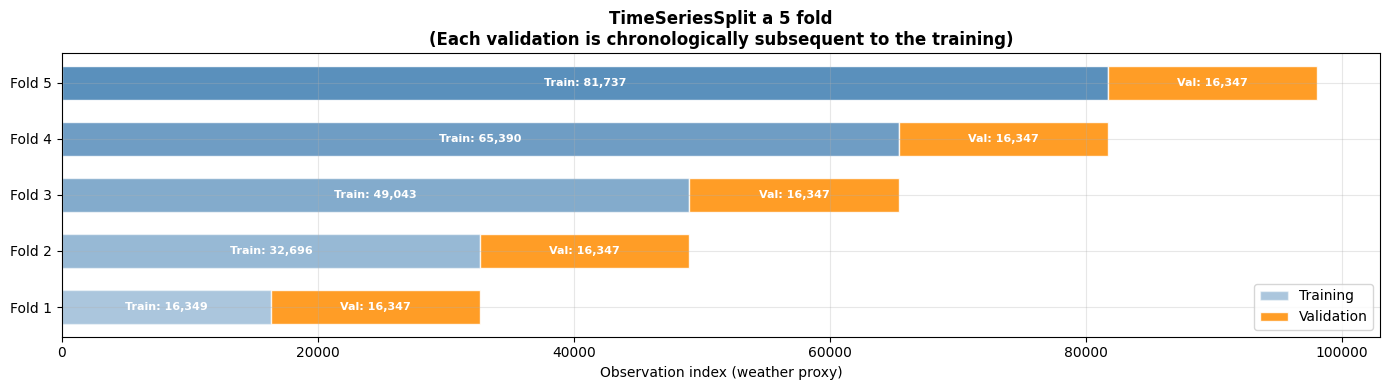

TimeSeriesSplit configurated with n_splits=5.


In [ ]:
# =============================================================================
# TimeSeriesSplit configuration for the cross-validation
# =============================================================================
# The classic K-Fold is inappropried for data with time dependence: fold d
# may contain observations chronogically prior to fold
# of training, equivalent of "predicting the past from future".
# TimeSeriesSplit guarantees that every validation fold is always subsequent to the
# corrisponding training set, reproducing the real forecasting conditions.
# =============================================================================

N_SPLITS = 5
tscv     = TimeSeriesSplit(n_splits=N_SPLITS)

fig, ax = plt.subplots(figsize=(14, 4))
for fold_idx, (tr_idx, val_idx) in enumerate(tscv.split(X_train_sc)):
    ax.barh(fold_idx, len(tr_idx), left=0, height=0.6,
            color='steelblue', alpha=0.45 + fold_idx*0.11, edgecolor='white',
            label='Training' if fold_idx==0 else '')
    ax.barh(fold_idx, len(val_idx), left=max(tr_idx), height=0.6,
            color='darkorange', alpha=0.85, edgecolor='white',
            label='Validation' if fold_idx==0 else '')
    ax.text(max(tr_idx)/2, fold_idx, f"Train: {len(tr_idx):,}",
            ha='center', va='center', fontsize=8, color='white', fontweight='bold')
    ax.text(max(tr_idx) + len(val_idx)/2, fold_idx, f"Val: {len(val_idx):,}",
            ha='center', va='center', fontsize=8, color='white', fontweight='bold')

ax.set_yticks(range(N_SPLITS))
ax.set_yticklabels([f'Fold {i+1}' for i in range(N_SPLITS)])
ax.set_xlabel('Observation index (weather proxy)')
ax.set_title(f'TimeSeriesSplit a {N_SPLITS} fold\n'
             '(Each validation is chronologically subsequent to the training)',
             fontweight='bold')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

print(f"TimeSeriesSplit configurated with n_splits={N_SPLITS}.")

---
## Section 3 — Baseline models: linear vs non linear comparison

Before adopting XGBoost as final model, we compare two models of increasing complexity. This comparison helps answer  two methodological questions:

**Question 1**: Is the problem solvable with a linear classification?
We check with a  **Logistic Regression** regularized. If LR achieved performance close to that of the more complex models,  the use of XGBoost would be injustified.

**Question 2**: is boosting really necessary or is bagging sufficient?
We check with a  **Random Forest**,  non-linear tree based model.

**Note on the exclusion of Support Vector Machines**: the initial version of the project
included an SVM with kernel RBF as third baseline. But given its high computal costs, training on our dataset would have required more
6 hours, aso we decided to exclude it from the project. The linear/ not linear comparison remain covered by LR/RF.

| Model| Family | Role in the project |
|---|---|---|
| Logistic Regression | Linear | Check the minimum requiered complexity|
| Random Forest | Not-linear (bagging) | Strong control baseline |
| XGBoost (Fase 3) | Not-linear (boosting) | Candidate main model |

In [ ]:
# =============================================================================
# Baseline Model Configuration
# =============================================================================
# Both models are encapsulated in a sklearn Pipeline that includes a
# SimpleImputer as safety net for any unmanaged residual NaN
# by manual imputation (es. edge cases generated duraing the CV).
#
# Logistic Regression
#   C=0.1                   regolarization L2 moderate
#   max_iter=2000           by convergence on post-scaling data
#   class_weight='balanced' correct slight imbalance UP/DOWN
#
# Random Forest
#   n_estimators=300        sufficient number for the error OOB to converge
#   max_depth=8            limits the storage of specific historical patterns
#   min_samples_leaf=50    minimum leaf -> regularization
#   max_features='sqrt'     diversify the trees
#   class_weight='balanced' idem LR
# =============================================================================

def crea_pipeline(modello):
    return Pipeline([
        ('imputer',    SimpleImputer(strategy='median')),
        ('classifier', modello),
    ])

MODELLI_BASELINE = {
    'Logistic Regression': crea_pipeline(
        LogisticRegression(
            C=0.1, max_iter=2000,
            class_weight='balanced',
            random_state=42, n_jobs=-1,
        )
    ),
    'Random Forest': crea_pipeline(
        RandomForestClassifier(
            n_estimators=300, max_depth=8,
            min_samples_leaf=50, min_samples_split=100,
            max_features='sqrt',
            class_weight='balanced',
            oob_score=True,
            random_state=42, n_jobs=-1,
        )
    ),
}

print("Baseline models configurated:")
for nome, pipe in MODELLI_BASELINE.items():
    clf = pipe.named_steps['classifier']
    print(f"\n  [{nome}]")
    params = {k:v for k,v in clf.get_params().items()
              if k not in ['n_jobs','random_state','verbose']}
    for k, v in list(params.items())[:5]:
        print(f"   {k:<25} {v}")

Baseline models configurated:

  [Logistic Regression]
   C                         0.1
   class_weight              balanced
   dual                      False
   fit_intercept             True
   intercept_scaling         1

  [Random Forest]
   bootstrap                 True
   ccp_alpha                 0.0
   class_weight              balanced
   criterion                 gini
   max_depth                 8


In [ ]:
# =============================================================================
# Cross-validation with TimeSeriesSplit
# =============================================================================
# Metrics evaluated:
#   accuracy   - %  correct forecasts (necessary but insufficient on its own)
#   precision  - P(UP real | UP expected) - essential in a financial context
#   f1         - harmonic mean of precision and recall
#   roc_auc    - area under the ROC curve- robuste to class imbalance
# =============================================================================

print(f"Cross-validation with TimeSeriesSplit ({N_SPLITS} fold)...\n")

cv_baseline = {}
scoring = ['accuracy', 'precision', 'f1', 'roc_auc']

for nome, pipeline in MODELLI_BASELINE.items():
    t0 = time.time()
    cv_res = cross_validate(
        estimator=pipeline, X=X_train_sc, y=y_bin_train,
        cv=tscv, scoring=scoring, n_jobs=-1, verbose=0,
    )
    elapsed = time.time() - t0
    cv_baseline[nome] = cv_res
    print(f"  {nome:<25} completed in {elapsed:.1f}s")
    for m in scoring:
        s = cv_res[f'test_{m}']
        print(f"   {m:<10} {s.mean():.4f} +/- {s.std():.4f}")
    print()

Cross-validation with TimeSeriesSplit (5 fold)...

  Logistic Regression       completed in 16.5s
   accuracy   0.5307 +/- 0.0190
   precision  0.5867 +/- 0.0160
   f1         0.5678 +/- 0.0660
   roc_auc    0.5246 +/- 0.0237



In [ ]:
# =============================================================================
# Final training and evaluation on the test set
# =============================================================================

print("Training baseline models on the full training set...")

risultati_test = {}
for nome, pipeline in MODELLI_BASELINE.items():
    t0 = time.time()
    pipeline.fit(X_train_sc, y_bin_train)
    elapsed = time.time() - t0
    y_pred = pipeline.predict(X_test_sc)
    y_prob = pipeline.predict_proba(X_test_sc)[:, 1]
    risultati_test[nome] = {
        'accuracy':  accuracy_score(y_bin_test, y_pred),
        'precision': precision_score(y_bin_test, y_pred, zero_division=0),
        'recall':    recall_score(y_bin_test, y_pred, zero_division=0),
        'f1':        f1_score(y_bin_test, y_pred, zero_division=0),
        'roc_auc':   roc_auc_score(y_bin_test, y_prob),
        'y_pred':    y_pred,
        'y_prob':    y_prob,
        'time':      elapsed,
    }
    print(f"  {nome}: trained in {elapsed:.1f}s")

print("\n" + "=" * 70)
print(" BASELINE RESULTS - TEST SET (2024-2025)")
print("=" * 70)
print(f"\n  {'Model':<25} {'Accuracy':>10} {'Precision':>10} "
      f"{'Recall':>8} {'F1':>8} {'ROC-AUC':>9}")
print(f"  {'-'*70}")
for nome, res in risultati_test.items():
    print(f"  {nome:<25} {res['accuracy']:>10.4f} {res['precision']:>10.4f} "
          f"{res['recall']:>8.4f} {res['f1']:>8.4f} {res['roc_auc']:>9.4f}")

# Visualizzazione comparata
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
colori = {'Logistic Regression': 'mediumseagreen', 'Random Forest': 'darkorange'}
metric_keys = ['accuracy','precision','f1','roc_auc']
metric_labels = ['Accuracy','Precision','F1','ROC-AUC']
x, w = np.arange(len(metric_labels)), 0.35
for i, (nome, res) in enumerate(risultati_test.items()):
    vals = [res[m] for m in metric_keys]
    b = axes[0].bar(x + (i-0.5)*w, vals, w, label=nome, color=colori[nome],
                    alpha=0.85, edgecolor='white')
    axes[0].bar_label(b, labels=[f'{v:.3f}' for v in vals], padding=2, fontsize=8)
axes[0].set_xticks(x); axes[0].set_xticklabels(metric_labels)
axes[0].axhline(0.5, color='red', ls='--', lw=1, alpha=0.7, label='Soglia random')
axes[0].set_ylim(0.3, 0.85); axes[0].legend()
axes[0].set_title('Confronto baseline', fontweight='bold')

for nome, res in risultati_test.items():
    fpr, tpr, _ = roc_curve(y_bin_test, res['y_prob'])
    axes[1].plot(fpr, tpr, color=colori[nome], lw=2.5,
                  label=f"{nome} (AUC = {res['roc_auc']:.3f})")
axes[1].plot([0,1],[0,1], 'k--', lw=1, alpha=0.5, label='Random')
axes[1].set_xlabel('False Positive Rate'); axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('Curve ROC', fontweight='bold')
axes[1].legend()
plt.tight_layout()
plt.show()

In [ ]:
# =============================================================================
# Baseline conclusion
# =============================================================================

acc_lr = risultati_test['Logistic Regression']['accuracy']
acc_rf = risultati_test['Random Forest']['accuracy']
delta  = acc_rf - acc_lr

print("=" * 60)
print(" BASELINE SUMMARY")
print("=" * 60)
print(f"\n  Logistic Regression (linear):    Accuracy = {acc_lr:.4f}")
print(f"  Random Forest (non-linear):      Accuracy = {acc_rf:.4f}")
print(f"  Linear gap -> non-linear:       {delta:+.4f}")

if delta > 0.005:
    print(f"\n  The non-linear model significantly outperforms the linear one.")
    print(f"  -> The problem presents non-linear interactions between features.")
    print(f"  -> It's justified to test even more expressive models (XGBoost in Phase 3).")
else:
    print(f"\n  The nonlinear model does not offer significant advantages.")
    print(f"  -> The problem may not benefit from further complexity.")

print(f"\n  Logistic Regression represents an upper bound for linear complexity:")
print(f"  with F1 = {risultati_test['Logistic Regression']['f1']:.4f}, confirms that ")
print(f"  the problem requires models capable of capturing interactions between variables.")

---
## Section  4 —  Reduced Feature Set Selection

### Context and research path

The purpose of this section is to obtain a **Reduced Feature Set** optimized for the final model
 XGBoost. This choice is the result of a research process documented here for scientific trasparency.

In a previous version of the project, we developed an  hybrid Feature Selection Pipeline ispired by advanced quantitative literature  (Lopez de Prado, 2018). The method combined the Permutation Importance (calculated out-of-sample with Random Forest) with a  Spearman collinearity filter (ρ < 0.85), using the Mean Decrease Impurity (MDI) as a tie breaker criterion for  high correlated variables.

However, empirical tests revealed an architectural limitation . When XGBoost was trained on the 'Reduced Feature Set' containing only 12 variables, its performances (ROC-AUC) was lower than the baseline. By reintroducing the full set of 44 variables , XGBoost  instead outperformed Random Forest. This reveals a phenomenon of 'Feature Starvation':  variables discarted  by the Bagging's model (Random Forest)  still cointained weak but essentials signals for iterative optimization process typical of Gradient Boosting,  proving to be crucials for allow to the algorithm to adapt to the macroeconomics Shift regime by biennium 2024-2025.


Three experiments documented this path:

| Experiment | Configuration | F1 | ROC-AUC |
|---|---|---|---|
| First attempt | 12 features (Lopez de Prado) + strong regularization | 0.4359 | 0.5510 |
| Second attempt | 12 features (Lopez de Prado) + relaxed regularization | 0.5527 | 0.5551 |
| Third attempt | 44 full feature set + loosened regularization | 0.5786 | 0.5739 |

Experiment 3 showed that relaxing the regularization and using the full feature
set improves performance. This result is consistent with recent literature
(Gu, Kelly, Xiu, 2020) explaining how gradient boosting models have
an intrinsic ability to enhance weak-signal features through the
sequential error correction mechanism, while Random Forest
(bagging)-based selection methods tend to discard such features as noise.

Our plan now is to study both an XGBoost model trained on all our features (taking example from attempt 3 of our previous experiments) and a model trained on a XGBoost-native Reduced Feature Set, generated by adopting a selection pipeline constructed as follows:
1. **XGBoost Pre-training** on the entire feature set (44 variables) to extract the model's internal importance metrics.
2. **Gain Extraction** (average contribution of each feature to loss reduction) and
average out-of-sample **SHAP values** (validation)
3. **Spearman Collinearity Filter** with Gain Tie-Breaker

N.B. We decided to adopt a "permissive" variant (Spearman > 0.85, low selection threshold) to
preserve the maximum possible signal, consistent with the empirical evidence from
Attempt 3.

In [ ]:
# =============================================================================
#  XGBoost Pre-training on the full feature set
# =============================================================================
# Hyperparameters: Configuration empirically validated in Attempt 3.
# The regularization philosophy is "moderate"—neither too aggressive as in the
# early attempts (which throttled the model) nor completely absent.
# =============================================================================

XGB_FEAT_SELECT_PARAMS = {
    'n_estimators':     500,
    'max_depth':        6,            # During the first attempts it was set to 4,
    'learning_rate':    0.05,         # so between 16 and 64 leaves.
    'subsample':        0.7,
    'colsample_bytree': 0.7,
    'reg_alpha':        0.1,
    'reg_lambda':       1.0,          # During the first attempts it was set to 2.0
    'min_child_weight': 50,
    'eval_metric':      'logloss',
    'random_state':     42,
    'n_jobs':           -1,
}

# Compared to previous attempts, we've also removed scale_pos_weight,
# which made XGBoost overly conservative, reducing recall.

print(" XGBoost Pre-training on the full feature set (44 features)...")
t0 = time.time()
xgb_preselect = xgb.XGBClassifier(**XGB_FEAT_SELECT_PARAMS)
xgb_preselect.fit(X_train_sc[FEATURE_COLS], y_bin_train)
elapsed = time.time() - t0

# Sanity check sul test set (per verifica, non per modellistica finale)
y_pred_pre = xgb_preselect.predict(X_test_sc[FEATURE_COLS])
acc_pre    = accuracy_score(y_bin_test, y_pred_pre)
f1_pre     = f1_score(y_bin_test, y_pred_pre, zero_division=0)

print(f"Pre-training completed in... {elapsed:.1f}s")
print(f"  Sanity check on the test set: Accuracy = {acc_pre:.4f}, F1 = {f1_pre:.4f}")

In [ ]:
# =============================================================================
# Extraction of Gain Importance and SHAP Values
# =============================================================================
# Gain
#   XGBoost's native metric: the average contribution of each feature to the reduction
# of the loss function. This is the most direct measure of importance for boosting models.
#
# SHAP (SHapley Additive exPlanations)
#   Calculated out-of-sample on a sample of the test set.
# They validate the gain by confirming that important features generalize even
# to data never seen during training.
# =============================================================================

# 1. Gain importance
booster = xgb_preselect.get_booster()
gain_dict = booster.get_score(importance_type='gain')

feature_names = X_train_sc[FEATURE_COLS].columns.tolist()
gain_map = {f: 0.0 for f in feature_names}
for k, v in gain_dict.items():
    if k.startswith('f') and k[1:].isdigit():
        idx = int(k[1:])
        gain_map[feature_names[idx]] = v
    else:
        if k in gain_map:
            gain_map[k] = v

fi_xgb = pd.DataFrame({
    'feature': feature_names,
    'gain':    [gain_map[f] for f in feature_names],
    'group':   [assegna_gruppo(f) for f in feature_names],
})

# 2. SHAP values out-of-sample
print("Computing SHAP values ​​on a sample of the test set..")
N_SHAP = min(2000, len(X_test_sc))
idx_shap = np.random.RandomState(42).choice(len(X_test_sc), N_SHAP, replace=False)
X_shap_sample = X_test_sc[FEATURE_COLS].iloc[idx_shap]

explainer = shap.TreeExplainer(xgb_preselect)
shap_values = explainer.shap_values(X_shap_sample)

mean_abs_shap = np.abs(shap_values).mean(axis=0)
shap_map = dict(zip(feature_names, mean_abs_shap))
fi_xgb['shap_mean_abs'] = fi_xgb['feature'].map(shap_map)

fi_xgb['gain_pct']      = fi_xgb['gain'] / fi_xgb['gain'].sum() * 100
fi_xgb['shap_pct']      = fi_xgb['shap_mean_abs'] / fi_xgb['shap_mean_abs'].sum() * 100
fi_xgb = fi_xgb.sort_values('gain', ascending=False).reset_index(drop=True)
fi_xgb['rank'] = fi_xgb.index + 1

print(f"SHAP values ​​calculated on {N_SHAP} out-of-sample observations.\n")

print("=" * 75)
print(" FEATURE IMPORTANCE XGBOOST-NATIVE - TOP 25")
print("=" * 75)
print(f"\n  {'Rank':<5} {'Feature':<28} {'Gain %':>8} {'SHAP %':>8} {'Gruppo'}")
print(f"  {'-'*72}")
for _, row in fi_xgb.head(25).iterrows():
    print(f"  {row['rank']:<5} {row['feature']:<28} "
          f"{row['gain_pct']:>7.2f}% {row['shap_pct']:>7.2f}%  {row['group']}")

corr_gain_shap = fi_xgb[['gain','shap_mean_abs']].corr(method='spearman').iloc[0,1]
print(f"\n  Gain vs SHAP Concordance (Spearman Correlation): {corr_gain_shap:.3f}")
if corr_gain_shap > 0.8:
    print(f"  High concordance: Gain is confirmed by out-of-sample evidence.")
else:
    print(f"  Moderate agreement: some features may be training artifacts.")

In [ ]:
# =============================================================================
# Reduced Feature Set Selection
# =============================================================================
# Strategy (permissive variant):
# Step 1: All features with Gain > 0 (features actually used by the model)
# Step 2: Spearman collinearity filter > 0.85
# Step 3: Tiebreaker between correlated features based on Gain (highest gain wins)
# =============================================================================

print("Reduced Feature Set Selection (permissive variant)...\n")

#  Step n.1: Gain > 0
feature_gain_positive = fi_xgb[fi_xgb['gain'] > 0]['feature'].tolist()

# Step n.2-3: filtro Spearman con tie-breaker Gain
X_gain = X_train_sc[feature_gain_positive]
corr_matrix = X_gain.corr(method='spearman').abs()
SOGLIA_CORR = 0.85
feature_da_droppare = set()

for i in range(len(corr_matrix.columns)):
    for j in range(i):
        if corr_matrix.iloc[i, j] > SOGLIA_CORR:
            feat_a = corr_matrix.columns[i]
            feat_b = corr_matrix.columns[j]
            gain_a = fi_xgb[fi_xgb['feature'] == feat_a]['gain'].values[0]
            gain_b = fi_xgb[fi_xgb['feature'] == feat_b]['gain'].values[0]
            peggiore = feat_a if gain_a < gain_b else feat_b
            feature_da_droppare.add(peggiore)

REDUCED_FEATURE_SET = [f for f in feature_gain_positive if f not in feature_da_droppare]

# Reordered by decreasing gain for clarity of exposition
REDUCED_FEATURE_SET = sorted(REDUCED_FEATURE_SET,
                              key=lambda f: -fi_xgb[fi_xgb['feature']==f]['gain'].values[0])

print("=" * 60)
print(" REDUCED FEATURE FINAL SET")
print("=" * 60)
print(f"\n  Passo 1 (Gain > 0):                {len(feature_gain_positive)} feature")
print(f"  Passo 2-3 (Spearman + Gain):       rimosse {len(feature_da_droppare)}")
print(f"  Feature finali nel Reduced Set:    {len(REDUCED_FEATURE_SET)} feature")
print(f"  Riduzione: {len(FEATURE_COLS)} -> {len(REDUCED_FEATURE_SET)} "
      f"({(1-len(REDUCED_FEATURE_SET)/len(FEATURE_COLS))*100:.1f}% eliminate)\n")

print(f"  {'#':<4} {'Feature':<28} {'Gain %':>8} {'SHAP %':>8} {'Gruppo'}")
print(f"  {'-'*72}")
for i, feat in enumerate(REDUCED_FEATURE_SET):
    row = fi_xgb[fi_xgb['feature']==feat].iloc[0]
    print(f"  {i+1:<4} {feat:<28} {row['gain_pct']:>7.2f}% "
          f"{row['shap_pct']:>7.2f}%  {row['group']}")

# Group distribuition
grp_dist = pd.Series([assegna_gruppo(f) for f in REDUCED_FEATURE_SET]).value_counts()
print(f"\n  Distribution by thematic group:")
for g, n in grp_dist.items():
    print(f"   {g:<25} {n} feature")

In [ ]:
# =============================================================================
# Reduced Feature Set Visualization
# =============================================================================

colori_gruppi = {
    'Rendimenti e Momentum':   'steelblue',
    'Indicatori Tecnici':      'darkorange',
    'Volatilita e Volume':     'mediumseagreen',
    'Fondamentali e Altman-Z': 'mediumpurple',
    'Macro':                   'saddlebrown',
    'Altro':                   'gray',
}

df_final = fi_xgb[fi_xgb['feature'].isin(REDUCED_FEATURE_SET)].sort_values(
    'gain', ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(18, 10))

# Plot 1: Gain importance
bar_colors = [colori_gruppi.get(g,'gray') for g in df_final['group']]
bars = axes[0].barh(df_final['feature'], df_final['gain_pct'],
                    color=bar_colors, edgecolor='white', alpha=0.85)
axes[0].set_xlabel('Gain Importance (%)', fontsize=11)
axes[0].set_title('Gain Importance (nativa XGBoost)',
                  fontweight='bold', fontsize=12)
for bar, val in zip(bars, df_final['gain_pct']):
    axes[0].text(val + 0.1, bar.get_y() + bar.get_height()/2,
                 f'{val:.2f}%', va='center', fontsize=8, fontweight='bold')

# Plot 2: SHAP importance
df_shap_sort = df_final.sort_values('shap_mean_abs', ascending=True)
bar_colors2 = [colori_gruppi.get(g,'gray') for g in df_shap_sort['group']]
bars2 = axes[1].barh(df_shap_sort['feature'], df_shap_sort['shap_pct'],
                      color=bar_colors2, edgecolor='white', alpha=0.85)
axes[1].set_xlabel('SHAP Importance (%)', fontsize=11)
axes[1].set_title('SHAP Mean |Value| (validazione out-of-sample)',
                  fontweight='bold', fontsize=12)
for bar, val in zip(bars2, df_shap_sort['shap_pct']):
    axes[1].text(val + 0.1, bar.get_y() + bar.get_height()/2,
                 f'{val:.2f}%', va='center', fontsize=8, fontweight='bold')

legend_handles = [mpatches.Patch(color=c, label=g, alpha=0.85)
                  for g, c in colori_gruppi.items()
                  if g in df_final['group'].values]
axes[1].legend(handles=legend_handles, loc='lower right',
               fontsize=9, title='Gruppo', title_fontsize=10)

plt.suptitle('Reduced Feature Set - Importanza per Gain e SHAP',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

---
## Section 5 — Artifacts Saving

In [ ]:
# =============================================================================
# Saving Artifacts to Local Sandbox (Colab /content/)
# =============================================================================
# Saved artifacts (temporary storage):
# robust_scaler.pkl       - the trained scaler (essential for new data)
# rf_model.pkl            - Random Forest baseline
# xgb_preselect_model.pkl - XGBoost pre-training (useful for final comparison)
# reduced_feature_set.json- Reduced Feature Set used in Phases 3-6
# feature_importance.csv  - complete Gain + SHAP table
# cv_results_baseline.csv - CV results of the baselines
# test_results_baseline.csv - test set results of the baselines
# =============================================================================

print(f"Artifacts saved in... {PROGETTO_PATH}\n")

joblib.dump(scaler, PROGETTO_PATH + 'robust_scaler.pkl')
print(f"  robust_scaler.pkl")

rf_fitted = MODELLI_BASELINE['Random Forest'].named_steps['classifier']
joblib.dump(rf_fitted, PROGETTO_PATH + 'rf_model.pkl')
print(f"  rf_model.pkl")

joblib.dump(xgb_preselect, PROGETTO_PATH + 'xgb_preselect_model.pkl')
print(f"  xgb_preselect_model.pkl")

with open(PROGETTO_PATH + 'reduced_feature_set.json', 'w') as f:
    json.dump(REDUCED_FEATURE_SET, f, indent=2)
print(f"  reduced_feature_set.json  ({len(REDUCED_FEATURE_SET)} feature)")

fi_xgb.to_csv(PROGETTO_PATH + 'feature_importance.csv', index=False)
print(f"  feature_importance.csv")

cv_rows = []
for nome, cv_res in cv_baseline.items():
    for m_key, m_label in [('accuracy','Accuracy'),('precision','Precision'),
                            ('f1','F1-Score'),('roc_auc','ROC-AUC')]:
        scores = cv_res[f'test_{m_key}']
        cv_rows.append({'model': nome, 'metric': m_label,
                        'mean': scores.mean(), 'std': scores.std()})
pd.DataFrame(cv_rows).to_csv(PROGETTO_PATH + 'cv_results_baseline.csv', index=False)
print(f"  cv_results_baseline.csv")

test_rows = [
    {'model': nome, **{k: v for k, v in res.items()
                        if k not in ['y_pred','y_prob','time']}}
    for nome, res in risultati_test.items()
]
pd.DataFrame(test_rows).to_csv(PROGETTO_PATH + 'test_results_baseline.csv', index=False)
print(f"  test_results_baseline.csv")

print("\n" + "=" * 60)
print(" FASE 2 COMPLETED")
print("=" * 60)
print(f"\n  Files in {PROGETTO_PATH}:")
for f in sorted(os.listdir(PROGETTO_PATH)):
    if any(ext in f for ext in ['.pkl', '.json', '.csv']):
        size_mb = os.path.getsize(PROGETTO_PATH + f) / 1024 / 1024
        print(f"   {f:<35} ({size_mb:.2f} MB)")

print(f"\n  Methodological summary:")
print(f"   Linear Baseline: Logistic Regression - "
      f"F1 = {risultati_test['Logistic Regression']['f1']:.4f}")
print(f"    Non-lin. Baseline:   Random Forest       - "
      f"F1 = {risultati_test['Random Forest']['f1']:.4f}")
print(f"   Reduced Feature Set: {len(REDUCED_FEATURE_SET)} feature from {len(FEATURE_COLS)} initial")
print(f"\n  In Phases 3-6 we'll use the Reduced Feature Set as input to one of the two XGBoost models.")

# Phase 3 — Binary Classification: Multi-Model Comparison and Interpretability

---

## Phase objective

We built three distinct binary classifiers, each with
different architectural and operational characteristics. In this phase, we evaluate them.
The three models being compared are:

| Model | Family | Set Features | Hyperparameters |
|---|---|---|---|
| Random Forest | Bagging (parallel) | 44 completed features | Standard regularization |
| XGBoost-44 feature | Boosting (sequential) | 44 completed features  | Moderate regularization |
| XGBoost-Reduced | Boosting (sequential) | 28 features (Reduced Set) | Moderate regularization |

From previous experiments, we have intuited that each of these models presents a distinct predictive profile, which will emerge from the
comparative results. The choice of the best operating model will be left to the subsequent
phases (particularly the financial backtest, contained in Phase 5), where trading metrics
(Sharpe Ratio, Max Drawdown) will complement the judgment of the statistical
classification metrics.

## Phase structure

| Section | Contents |
|---|---|
| 0 | Pre-trained models and Reduced Feature Set Loading |
| 1 | XGBoost-Reduced Feature Set training |
| 2 | Systematic comparison of the three models on the test set |
| 3 | SHAP interpretability of XGBoost-Reduced |
| 4 | Artifacts saving|

> **Phase 2 Input**: `rf_model.pkl`, `xgb_preselect_model.pkl`, `reduced_feature_set.json`

> **Output**: `xgb_reduced_model.pkl`, `shap_importance_binary.csv`, `test_results_binary_comparison.csv`

---
## Section 0 — Pre-trained models loading

In [ ]:
# =============================================================================
# Reduced Feature Set Loading
# =============================================================================
# We load the list of features selected in Section 4 of Phase 2.
# These are the 28 features that will train the third model (XGBoost-Reduced).
# =============================================================================

with open(PROGETTO_PATH + 'reduced_feature_set.json', 'r') as f:
    REDUCED_FEATURE_SET = json.load(f)

print(f"Reduced Feature Set loaded: {len(REDUCED_FEATURE_SET)} features\n")
print("Composition for thematic group:")
grp_dist = pd.Series([assegna_gruppo(f) for f in REDUCED_FEATURE_SET]).value_counts()
for g, n in grp_dist.items():
    print(f"  {g:<25} {n} features")

In [ ]:
# =============================================================================
#  Pre-trained models loading from Phase 2
# =============================================================================
# From the previous part:
# - rf_model.pkl Random Forest baseline (trained in Phase 2, section 3)
# - xgb_preselect_model.pkl XGBoost-44 features (trained in Phase 2, section 4)
#
# These models are already in memory if Phase 2 was run in the same
# session. Loading from disk still guarantees reproducibility
# even after a kernel restart.
# =============================================================================

# Random Forest baseline (with 44 completed features)
rf_model_loaded = joblib.load(PROGETTO_PATH + 'rf_model.pkl')
print(f"Random Forest baseline caricato: rf_model.pkl")

# XGBoost-44 features ("balanced" model)
xgb_44 = joblib.load(PROGETTO_PATH + 'xgb_preselect_model.pkl')
print(f"XGBoost-44 feature caricato:   xgb_preselect_model.pkl")

print(f"\nTraining/test data already in memory (from Phase 2):")
print(f"  X_train_sc: {X_train_sc.shape}")
print(f"  X_test_sc:  {X_test_sc.shape}")
print(f"  y_bin_train: {y_bin_train.shape}")
print(f"  y_bin_test:  {y_bin_test.shape}")

---
## Section 1 — Training the third model: XGBoost-Reduced Feature Set

The XGBoost-Reduced model is trained from scratch with the same hyperparameters as XGBoost-44,
but using exclusively the 28 features of the Reduced Feature Set. By keeping the
hyperparameters identical, we ensure that performance differences are attributable
**exclusively to the feature set** and not to the model configuration.

This procedure also allows us to answer a specific methodological question we posed following the experiments we developed during the project:
**Does feature reduction improve, worsen, or leave the predictive power
of the XGBoost model unchanged in this case?**

In [ ]:
# =============================================================================
# Hyperparameter configuration (identical to Phase 2 pre-training)
# =============================================================================
# We keep the same parameters as in Attempt 3, which were empirically validated.
# This allows us to isolate the specific effect of feature selection.
# In the output, we will also explain why they were set this way.
# =============================================================================

XGB_BINARY_PARAMS = {
    'n_estimators':     500,
    'max_depth':        6,
    'learning_rate':    0.05,
    'subsample':        0.7,
    'colsample_bytree': 0.7,
    'reg_alpha':        0.1,
    'reg_lambda':       1.0,
    'min_child_weight': 50,
    'eval_metric':      'logloss',
    'random_state':     42,
    'n_jobs':           -1,
}

motivazioni = {
    'n_estimators':     'Upper bound; boosting con lr basso richiede molti alberi',
    'max_depth':        'Sweet spot empirico (T3): non troppo basso, non troppo alto',
    'learning_rate':    'Basso: ogni albero contribuisce con piccole correzioni',
    'subsample':        'Row bagging - riduce la varianza',
    'colsample_bytree': 'Feature sampling - diversifica l\'ensemble',
    'reg_alpha':        'L1: spinge a zero pesi marginali',
    'reg_lambda':       'L2 standard (1.0); 2.0 era troppo restrittivo (T2)',
    'min_child_weight': 'Min 50 obs/foglia - no overfit per ticker',
}

print("XGBoost-Reduced Configuration (Identical to XGBoost-44):")
print(f"\n  {'Parameter':<22} {'Value':>10}   Motivation")
print(f"  {'-'*85}")
for k, v in XGB_BINARY_PARAMS.items():
    if k in motivazioni:
        print(f"  {k:<22} {str(v):>10}   {motivazioni[k]}")

In [ ]:
# =============================================================================
# Cross-validation with TimeSeriesSplit
# =============================================================================

X_train_reduced = X_train_sc[REDUCED_FEATURE_SET].copy()
X_test_reduced  = X_test_sc[REDUCED_FEATURE_SET].copy()

print(f"XGBoost-Reduced cross-validation (TimeSeriesSplit, {N_SPLITS} fold)...")
print(f"  Feature: {len(REDUCED_FEATURE_SET)} (Reduced Feature Set)")
print(f"  X_train_reduced: {X_train_reduced.shape}\n")

t0 = time.time()
cv_xgb_reduced = cross_validate(
    estimator = xgb.XGBClassifier(**XGB_BINARY_PARAMS),
    X         = X_train_reduced,
    y         = y_bin_train,
    cv        = tscv,
    scoring   = ['accuracy', 'precision', 'f1', 'roc_auc'],
    n_jobs    = -1,
    verbose   = 0,
)
elapsed = time.time() - t0

print(f"CV completed in {elapsed:.1f}s\n")
print("=" * 60)
print(" XGBOOST-REDUCED - CROSS-VALIDATION RESULTS")
print("=" * 60)

metric_map = {'accuracy':'Accuracy', 'precision':'Precision',
              'f1':'F1-Score', 'roc_auc':'ROC-AUC'}

for k, label in metric_map.items():
    s = cv_xgb_reduced[f'test_{k}']
    folds_str = '  '.join([f'F{i+1}={v:.4f}' for i,v in enumerate(s)])
    print(f"\n  {label}:")
    print(f"   Media: {s.mean():.4f}   Std: {s.std():.4f}")
    print(f"   {folds_str}")

In [ ]:
# =============================================================================
# Final training and evaluation on the test set
# =============================================================================

print("XGBoost-Reduced Training on the Entire Training Set...")
t0 = time.time()
xgb_reduced = xgb.XGBClassifier(**XGB_BINARY_PARAMS)
xgb_reduced.fit(X_train_reduced, y_bin_train)
elapsed = time.time() - t0

y_pred_reduced = xgb_reduced.predict(X_test_reduced)
y_prob_reduced = xgb_reduced.predict_proba(X_test_reduced)[:, 1]

xgb_reduced_results = {
    'accuracy':  accuracy_score(y_bin_test, y_pred_reduced),
    'precision': precision_score(y_bin_test, y_pred_reduced, zero_division=0),
    'recall':    recall_score(y_bin_test, y_pred_reduced, zero_division=0),
    'f1':        f1_score(y_bin_test, y_pred_reduced, zero_division=0),
    'roc_auc':   roc_auc_score(y_bin_test, y_prob_reduced),
    'y_pred':    y_pred_reduced,
    'y_prob':    y_prob_reduced,
}

print(f"Model trained in {elapsed:.1f}s")
print(f"\n  XGBoost-Reduced metrics on the test set:")
for k in ['accuracy','precision','recall','f1','roc_auc']:
    print(f"   {k:<10} {xgb_reduced_results[k]:.4f}")

In [ ]:
# =============================================================================
# Diagnostics: Find columns with 100% missing values ​​(NaN)
# =============================================================================

nan_percentages = X_train_sc[FEATURE_COLS].isna().mean() * 100
empty_cols = nan_percentages[nan_percentages == 100]

print("Columns with 100% NaN in the Training Set:")
if not empty_cols.empty:
    for col in empty_cols.index:
        print(f"- {col}")
else:
    print("No completely empty columns detected.")

---
## Section 2 — Systematic comparison of the three models

We compare the three models on the same metrics and the same test set. This
is the key moment of Phase 3: the results reveal the different predictive profiles
of the models, which characterize their subsequent operational use.

For Random Forest and XGBoost-44, we retrieve the predictions from the loaded models;
for XGBoost-Reduced, we have just calculated the results.

In [ ]:
# =============================================================================
# Generating predictions for the three models on the test set
# =============================================================================

# 1. Random Forest baseline (it's a pipeline, not just the classifier)
# We retrieve the trained pipeline; if rf_model_loaded is the pure classifier,
# we use X_test_sc directly because it was trained on scaled data.
y_pred_rf = rf_model_loaded.predict(X_test_sc[FEATURE_COLS])
y_prob_rf = rf_model_loaded.predict_proba(X_test_sc[FEATURE_COLS])[:, 1]

rf_results = {
    'accuracy':  accuracy_score(y_bin_test, y_pred_rf),
    'precision': precision_score(y_bin_test, y_pred_rf, zero_division=0),
    'recall':    recall_score(y_bin_test, y_pred_rf, zero_division=0),
    'f1':        f1_score(y_bin_test, y_pred_rf, zero_division=0),
    'roc_auc':   roc_auc_score(y_bin_test, y_prob_rf),
    'y_pred':    y_pred_rf,
    'y_prob':    y_prob_rf,
}

# 2. XGBoost-44 feature
y_pred_xgb44 = xgb_44.predict(X_test_sc[FEATURE_COLS])
y_prob_xgb44 = xgb_44.predict_proba(X_test_sc[FEATURE_COLS])[:, 1]

xgb_44_results = {
    'accuracy':  accuracy_score(y_bin_test, y_pred_xgb44),
    'precision': precision_score(y_bin_test, y_pred_xgb44, zero_division=0),
    'recall':    recall_score(y_bin_test, y_pred_xgb44, zero_division=0),
    'f1':        f1_score(y_bin_test, y_pred_xgb44, zero_division=0),
    'roc_auc':   roc_auc_score(y_bin_test, y_prob_xgb44),
    'y_pred':    y_pred_xgb44,
    'y_prob':    y_prob_xgb44,
}

# 3. XGBoost-Reduced (already calculated in section 7)
# xgb_reduced_results is already available

all_models = {
    'Random Forest (44 feat.)':     rf_results,
    'XGBoost-44 feat.':           xgb_44_results,
    'XGBoost-Reduced (28 feat.)': xgb_reduced_results,
}

print("Predictions generated for the three models.")
print("\n" + "=" * 80)
print(" MULTI-MODEL COMPARISON ON THE TEST SET (2024-2025)")
print("=" * 80)
print(f"\n  {'Model':<33} {'Accuracy':>10} {'Precision':>10} "
      f"{'Recall':>8} {'F1':>8} {'ROC-AUC':>9}")
print(f"  {'-'*78}")
for nome, res in all_models.items():
    print(f"  {nome:<33} {res['accuracy']:>10.4f} {res['precision']:>10.4f} "
          f"{res['recall']:>8.4f} {res['f1']:>8.4f} {res['roc_auc']:>9.4f}")

In [ ]:
# =============================================================================
# Comparison view of the three models
# =============================================================================

fig = plt.figure(figsize=(18, 12))
gs  = GridSpec(2, 3, figure=fig, hspace=0.45, wspace=0.35)

colori = {
    'Random Forest (44 feat.)':     'darkorange',
    'XGBoost-44 feat.':           'mediumpurple',
    'XGBoost-Reduced (28 feat.)': 'steelblue',
}

# Plot 1: Comparison of metrics on clustered bars
ax1 = fig.add_subplot(gs[0, :2])
metric_keys   = ['accuracy', 'precision', 'f1', 'roc_auc']
metric_labels = ['Accuracy', 'Precision', 'F1-Score', 'ROC-AUC']

x   = np.arange(len(metric_labels))
w   = 0.27
for i, (nome, res) in enumerate(all_models.items()):
    vals = [res[m] for m in metric_keys]
    b    = ax1.bar(x + (i-1)*w, vals, w,
                   label=nome, color=colori[nome],
                   alpha=0.85, edgecolor='white', linewidth=1.2)
    ax1.bar_label(b, labels=[f'{v:.3f}' for v in vals], padding=2, fontsize=7.5)

ax1.set_xticks(x); ax1.set_xticklabels(metric_labels, fontsize=10)
ax1.set_ylim(0.3, 0.85)
ax1.axhline(0.5, color='red', ls='--', lw=1.2, alpha=0.7, label='Random treshold (50%)')
ax1.set_title('Multi-model comparison - Test Set (2024-2025)',
              fontweight='bold', fontsize=12)
ax1.set_ylabel('Score')
ax1.legend(fontsize=9, loc='lower right')

# Plot 2: Overlapping ROC curves
ax2 = fig.add_subplot(gs[0, 2])
for nome, res in all_models.items():
    fpr, tpr, _ = roc_curve(y_bin_test, res['y_prob'])
    ax2.plot(fpr, tpr, color=colori[nome], lw=2.5,
              label=f"AUC = {res['roc_auc']:.4f}")
ax2.plot([0, 1], [0, 1], 'k--', lw=1, alpha=0.5)
ax2.set_xlabel('False Positive Rate'); ax2.set_ylabel('True Positive Rate')
ax2.set_title('Curve ROC', fontweight='bold')
ax2.legend(fontsize=8, loc='lower right')
ax2.set_xlim(0, 1); ax2.set_ylim(0, 1.02)

# Plot 3-5: Confusion matrices
for col_idx, (nome, res) in enumerate(all_models.items()):
    ax = fig.add_subplot(gs[1, col_idx])
    cm = confusion_matrix(y_bin_test, res['y_pred'])
    cmap_choice = ('Oranges' if 'Random Forest' in nome else
                   'Purples' if '-45' in nome else 'Blues')
    ConfusionMatrixDisplay(cm, display_labels=['DOWN','UP']).plot(
        ax=ax, cmap=cmap_choice, colorbar=False)
    ax.set_title(f'{nome}\nPrec={res["precision"]:.3f}  F1={res["f1"]:.3f}',
                 fontweight='bold', fontsize=10)

plt.suptitle('Systematic Comparison of Three Binary Classification Models',
             fontsize=14, fontweight='bold')
plt.show()

In [ ]:
# =============================================================================
# Interpretative reading: predictive profiles of the three models
# =============================================================================
# Each model is characterized by a different trade-off between Precision and Recall.
# This diversity is not a flaw, but a useful property: in the backtest of
# Phase 6, each of these profiles will produce a distinct trading strategy.
# =============================================================================

print("=" * 70)
print(" PREDICTIVE PROFILES OF THE THREE MODELS")
print("=" * 70)

for nome, res in all_models.items():
    prec = res['precision']
    rec  = res['recall']
    gap  = prec - rec

    print(f"\n  [{nome}]")
    print(f"   Precision: {prec:.4f}   Recall: {rec:.4f}   Gap (P-R): {gap:+.4f}")

    if gap > 0.15:
        profilo = "Conservative (high precision, low recall)"
        descrizione = ("It makes few UP signals but with high reliability. "
                       "Suitable for selective strategies that minimize the risk of false positives.")
    elif gap < -0.03:
        profilo = "Aggressive (high recall, moderate precision)"
        descrizione = ("Captures many UP signals, accepting a higher error rate. "
                       "Suitable for high-frequency strategies that don't want to miss opportunities.")
    else:
        profilo = "Balanced (Comparable Precision and Recall)"
        descrizione = ("Balance between reliability and catchability. "
                       "Suitable for diversified portfolio strategies.")

    print(f"   Profile: {profilo}")
    print(f"   {descrizione}")

print(f"\n  Methodological reflection:")
print(f"   None of these models is 'objectively' superior. The choice of the operative")
print(f"   model depends on the investor's strategic objective. The financial evaluation ")
print(f"   (Phase 5: Sharpe Ratio, Max Drawdown, Calmar) will translate these statistical ")
print(f"   profiles in economic performance metrics.")

---
## Section 3 — SHAP Interpretability of the XGBoost-Reduced Model

Of the three models, we focus on the interpretability of **XGBoost-Reduced** for
practical reasons: it is the model specifically built on the selected feature set and has the
greatest explanatory interest for the thesis.

**SHAP values** (SHapley Additive exPlanations) are based on the cooperative game
theory of Lloyd Shapley (Nobel Prize in Economics 2012) and answer a specific question:

> For this specific prediction, by how much did each feature push the probability
> up or down?

The **mathematical properties** that make them robust:

| Property | Meaning |
|---|---|
| Efficiency | The sum of the SHAP values ​​= model output |
| Simmetry | Equally informative features receive equal contribution |
| Nullity | An irrelevant feature has SHAP value = 0 |
| additivity | Contributions add up linearly |

We use `TreeExplainer`, which is optimized for tree models and computationally
much more efficient than the generic `KernelExplainer`.

In [ ]:
# =============================================================================
# Calculating SHAP values
# =============================================================================
# Sampling of 2000 observations from the test set for the SHAP calculation.
# TreeExplainer is mathematically exact for tree models.
# =============================================================================

print("Calculating SHAP Values ​​for XGBoost-Reduced (TreeExplainer)...")

N_SHAP    = min(2000, len(X_test_reduced))
idx_shap  = np.random.RandomState(42).choice(len(X_test_reduced), N_SHAP, replace=False)
X_shap    = X_test_reduced.iloc[idx_shap]
y_shap    = y_bin_test[idx_shap]

explainer    = shap.TreeExplainer(xgb_reduced)
shap_values  = explainer.shap_values(X_shap)

print(f"SHAP values calculated over {N_SHAP:,} test set observations")
print(f"  Shape: {np.array(shap_values).shape}")

# Verification of the efficiency property
expected_value = explainer.expected_value
n_check = 5
print(f"\n Efficiency Property Verification (Shapley 1953):")
print(f"  Expected value baseline (log-odds): {expected_value:.4f}\n")
print(f"  {'Obs':<5} {'Sum SHAP + base':>18} {'Pred log-odds':>16} {'Delta':>10}")
for i in range(n_check):
    sum_shap = shap_values[i].sum() + expected_value
    pred_logit = xgb_reduced.predict(X_shap.iloc[i:i+1], output_margin=True)[0]
    delta = sum_shap - pred_logit
    print(f"  {i:<5} {sum_shap:>18.4f} {pred_logit:>16.4f} {delta:>10.6f}")
print(f"\n  Numerically negligible deltas: the efficiency property is respected.")

In [ ]:
# =============================================================================
# SHAP Summary Plot (Beeswarm)
# =============================================================================
# - Y-axis: features sorted by average importance |SHAP|
# - X-axis: SHAP value (positive = pushes UP, negative = pushes DOWN)
# - Color: feature value (red = high, blue = low)
# - Each point: a specific observation from the test set
# =============================================================================

plt.figure(figsize=(12, 8))
shap.summary_plot(
    shap_values, X_shap,
    plot_type='dot',
    max_display=min(20, len(REDUCED_FEATURE_SET)),
    show=False,
)
plt.title('SHAP Summary Plot - XGBoost-Reduced\n'
          'Impact of each feature on the probability P(UP)',
          fontweight='bold', pad=15, fontsize=12)
plt.tight_layout()
plt.show()

print("\n  How to read the summary plot:")
print("   - Features sorted by average importance |SHAP|")
print("   - Each point represents an observation from the test set")
print("   - Horizontal position: contribution to prediction")
print("     To the right of 0: pushes UP")
print("     To the left of 0: pushes DOWN")
print("   - Color: red = high feature value, blue = low value")

In [ ]:
# =============================================================================
# SHAP Bar Chart + composition for thematic group
# =============================================================================
#Two complementary views:
#1. Average importance per feature (bar chart)
#2. Aggregate importance by thematic group (for macro analysis)
# =============================================================================

mean_abs_shap = np.abs(shap_values).mean(axis=0)
df_shap_imp = pd.DataFrame({
    'feature': X_shap.columns,
    'mean_abs_shap': mean_abs_shap,
    'group': [assegna_gruppo(f) for f in X_shap.columns]
}).sort_values('mean_abs_shap', ascending=True)

colori_gruppi_shap = {
    'Rendimenti e Momentum':   'steelblue',
    'Indicatori Tecnici':      'darkorange',
    'Volatilita e Volume':     'mediumseagreen',
    'Fondamentali e Altman-Z': 'mediumpurple',
    'Macro':                   'saddlebrown',
    'Altro':                   'gray',
}

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# Plot 1: Bar chart per feature
bar_colors = [colori_gruppi_shap.get(g,'gray') for g in df_shap_imp['group']]
bars = axes[0].barh(df_shap_imp['feature'], df_shap_imp['mean_abs_shap'],
                    color=bar_colors, edgecolor='white', alpha=0.85)
axes[0].set_title('SHAP Feature Importance\n(Media |SHAP value|)',
                  fontweight='bold', fontsize=12)
axes[0].set_xlabel('Media |SHAP value|')

for bar, val in zip(bars, df_shap_imp['mean_abs_shap']):
    axes[0].text(val + max(df_shap_imp['mean_abs_shap'])*0.01,
                 bar.get_y() + bar.get_height()/2,
                 f'{val:.4f}', va='center', fontsize=8, fontweight='bold')

legend_handles = [mpatches.Patch(color=c, label=g, alpha=0.85)
                  for g, c in colori_gruppi_shap.items()
                  if g in df_shap_imp['group'].values]
axes[0].legend(handles=legend_handles, loc='lower right',
               fontsize=9, title='Gruppo', title_fontsize=10)

# Plot 2: Aggregate importance by group
group_shap = df_shap_imp.groupby('group')['mean_abs_shap'].sum().sort_values(ascending=True)
bar_colors_grp = [colori_gruppi_shap.get(g,'gray') for g in group_shap.index]

bars_grp = axes[1].barh(group_shap.index, group_shap.values,
                        color=bar_colors_grp, edgecolor='white',
                        linewidth=1.5, alpha=0.85)
axes[1].bar_label(bars_grp, labels=[f'{v:.4f}' for v in group_shap.values],
                  padding=3, fontweight='bold', fontsize=10)
axes[1].set_title('SHAP Importance per Gruppo Tematico',
                  fontweight='bold', fontsize=12)
axes[1].set_xlabel('Somma |SHAP| del gruppo')

plt.suptitle('Interpretabilita XGBoost-Reduced - SHAP Importance',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Tabella riassuntiva
print("\n  Top 10 Features for SHAP Importance:")
top10 = df_shap_imp.sort_values('mean_abs_shap', ascending=False).head(10)
print(f"  {'Rank':<5} {'Feature':<28} {'|SHAP| medio':>13} {'Gruppo':<25}")
print(f"  {'-'*75}")
for i, (_, row) in enumerate(top10.iterrows(), 1):
    print(f"  {i:<5} {row['feature']:<28} {row['mean_abs_shap']:>13.4f}  {row['group']}")

print(f"\n  Thematic groups by aggregate importance:")
total = group_shap.sum()
for grp in group_shap.sort_values(ascending=False).index:
    val = group_shap[grp]
    pct = val/total*100
    print(f"  {grp:<25} {val:>10.4f}  ({pct:.1f}%)")

In [ ]:
# =============================================================================
# SHAP Dependence Plots (top 4 features)
# =============================================================================
# They show how the SHAP value of a single feature varies as a function of its
# value. They reveal the shape of the relationship (linear, nonlinear, threshold).
# =============================================================================

top4_features = df_shap_imp.sort_values(
    'mean_abs_shap', ascending=False).head(4)['feature'].tolist()

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes_flat = axes.flatten()

for ax, feat in zip(axes_flat, top4_features):
    feat_idx = list(X_shap.columns).index(feat)

    sc = ax.scatter(
        X_shap[feat], shap_values[:, feat_idx],
        c=X_shap[feat], cmap='RdYlGn',
        alpha=0.5, s=18, edgecolors='none',
    )
    ax.axhline(0, color='black', ls='--', lw=1, alpha=0.7)
    ax.set_xlabel(f'Valore di {feat} (scalato)', fontsize=10)
    ax.set_ylabel(f'SHAP value di {feat}', fontsize=10)
    ax.set_title(f'Dependence Plot: {feat}\n'
                 f'(SHAP medio |{abs(shap_values[:, feat_idx]).mean():.4f}|)',
                 fontweight='bold', fontsize=11)

    # Trend line by decile
    try:
        bins = pd.qcut(X_shap[feat], q=10, duplicates='drop')
        trend = pd.DataFrame({
            'x_bin': X_shap[feat].groupby(bins).mean(),
            'shap_bin': pd.Series(shap_values[:, feat_idx],
                                  index=X_shap.index).groupby(bins).mean()
        }).dropna()
        ax.plot(trend['x_bin'], trend['shap_bin'],
                color='darkblue', lw=2.5, alpha=0.8,
                label='Trend (media per decile)')
        ax.legend(fontsize=8, loc='best')
    except:
        pass

plt.suptitle('SHAP Dependence Plots - Top 4 Feature\n'
             '(Verde: spinge UP | Rosso: spinge DOWN)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n   Dependence plots:")
print("   - Monotonous increasing trend -> linear positive effect")
print("     (e.g. high momentum -> more likely UP)")
print("   - Monotonous decreasing trend -> linear negative effect")
print("     (e.g. high volatility -> less likely UP)")
print("   - U-shaped or bell-shaped trend -> non-linear effect")
print("     (e.g. RSI: extremes push DOWN, central values ​​push UP)")
print("   - Threshold trend -> behavior breaking point")

---
## Section 4 — Saving Artifacts - Checkpoint

In [ ]:
# =============================================================================
# Saving Artifacts to Local Sandbox (Colab /content/)
# =============================================================================
# Saved artifacts (temporary storage):
# xgb_reduced_model.pkl              - the trained XGBoost model (Reduced features)
# shap_importance_binary.csv         - SHAP values for interpretability
# test_results_binary_comparison.csv - benchmark of binary classification models
# =============================================================================

print(f"Artifacts saved in... {PROGETTO_PATH}\n")

# XGBoost-Reduced
joblib.dump(xgb_reduced, PROGETTO_PATH + 'xgb_reduced_model.pkl')
print(f"  xgb_reduced_model.pkl")

# SHAP importance
df_shap_imp_export = df_shap_imp.sort_values('mean_abs_shap', ascending=False)
df_shap_imp_export.to_csv(PROGETTO_PATH + 'shap_importance_binary.csv', index=False)
print(f"  shap_importance_binary.csv")

# Comparative results of the three models
test_rows = []
for nome, res in all_models.items():
    test_rows.append({
        'model':     nome,
        'accuracy':  res['accuracy'],
        'precision': res['precision'],
        'recall':    res['recall'],
        'f1':        res['f1'],
        'roc_auc':   res['roc_auc'],
    })
pd.DataFrame(test_rows).to_csv(PROGETTO_PATH + 'test_results_binary_comparison.csv', index=False)
print(f"  test_results_binary_comparison.csv")

print("\n" + "=" * 68)
print(" PHASE 3 COMPLETED")
print("=" * 68)
print(f"\n  Files in {PROGETTO_PATH}:")
for f in sorted(os.listdir(PROGETTO_PATH)):
    if any(ext in f for ext in ['.pkl', '.json', '.csv']):
        size_mb = os.path.getsize(PROGETTO_PATH + f) / 1024 / 1024
        print(f"   {f:<40} ({size_mb:.2f} MB)")

print(f"\n  Summary of test set metrics:")
print(f"  {'Model':<33} {'Accuracy':>10} {'F1':>10} {'ROC-AUC':>10}")
print(f"  {'-'*65}")
for nome, res in all_models.items():
    print(f"  {nome:<33} {res['accuracy']:>10.4f} {res['f1']:>10.4f} "
          f"{res['roc_auc']:>10.4f}")

print(f"\n  All three models are ready for:")
print(f"   - Phase 4: multi-class classification (4 classes)")
print(f"   - Phase 5: comparative financial backtest")

# Phase 4 — Multi-Class Classification: Multi-Model Comparison

---

## Phase objectives

In Phase 3 we compared three binary classifiers (UP/DOWN). In this phase
we extend the comparison to the **multi-class problem with 4 intensity levels**, defined
on the quartiles of 21-day future returns:

| Class | Label | Definition |
|---|---|---|
| 0 | Strong Down | fwd_ret_21d in the first quartile (more intense declines) |
| 1 | Weak Down   | fwd_ret_21d in the second quartile (moderate declines) |
| 2 | Weak Up     | fwd_ret_21d in the third quartile (moderate increases) |
| 3 | Strong Up   | fwd_ret_21d in the fourth quartile (more intense increases) |

Quartiles are defined **exclusively on the training set** (anti-leakage). On the test set,
we apply the same thresholds as for training: the class balance on the test set may
deviate slightly from the 25%/25%/25%/25% of the training set, and this deviation reflects the
2024-2025 market regime.

## The three models compared

We adopt the same equal approach as Phase 3: three models equivalent in dignity,
without prior preferences.
| Model | Family | Feature set |
|---|---|---|
| Random Forest | Bagging | 44  completed features |
| XGBoost-44 | Boosting | 44 completed features |
| XGBoost-Reduced | Boosting | 28 features (Reduced Set) |

## Technical differences compared to the track

| Appearance | Binary | Multi-Class |
|---|---|---|
|  XGBoost Objective | `binary:logistic` | `multi:softprob` |
| Output predict_proba | shape (n, 2) | shape (n, 4) |
| Primary metrics | Accuracy, F1, ROC-AUC | Accuracy, F1 macro/weighted, Cohen Kappa |
| Confusion matrix | 2 × 2 | 4 × 4 |
| Error analysis | FP vs FN | Adjacent errors vs. critical errors |

## Notebook structure

| Section | Content |
|---|---|
| 1 | Multi-class target verification and class distribution |
| 2 | Training of the three multi-class models |
| 3 | Systematic comparison of the three models |
| 4 | Error Analysis: Adjacency and Calibration |
| 5 | Artifacts saving |

---
## Section 1 — Multi-class target verification

In [ ]:
# =============================================================================
# Import multi-class specific metrics
# =============================================================================
# Standard metrics support multi-class matching via the 'average' parameter:
# average='macro' unweighted mean: treats each class equally
# average='weighted' frequency-weighted mean: penalizes errors on majorities
#
# In a balanced problem (quartiles = 25% per class in training), macro and weighted
# yield similar results. We report both for completeness.
# =============================================================================

from sklearn.metrics import cohen_kappa_score

print("Imported multi-class metrics.")
print("  Key metrics:")
print("   accuracy           % of correctly predicted observations")
print("   f1_macro          F1 average across 4 classes (unweighted)")
print("   f1_weighted        F1 weighted by class frequency")
print("   cohen_kappa       model-reality agreement beyond chance (0=random, 1=perfect)")

In [ ]:
# =============================================================================
# Class distribution in the training and test sets
# =============================================================================

LABELS_MULTI = {0: 'Strong Down', 1: 'Weak Down', 2: 'Weak Up', 3: 'Strong Up'}

print("=" * 70)
print(" MULTI-CLASS TARGET DISTRIBUTION")
print("=" * 70)
print(f"\n  TRAINING SET (2013-2023):")
dist_train = pd.Series(y_multi_train).value_counts(normalize=True).sort_index() * 100
for cls, pct in dist_train.items():
    n = int((y_multi_train == cls).sum())
    bar = '#' * int(pct/2)
    print(f"   {int(cls)} - {LABELS_MULTI[int(cls)]:<14} {pct:.1f}%  {bar} ({n:,} obs)")

print(f"\n  TEST SET (2024-2025):")
dist_test = pd.Series(y_multi_test).value_counts(normalize=True).sort_index() * 100
for cls, pct in dist_test.items():
    n = int((y_multi_test == cls).sum())
    bar = '#' * int(pct/2)
    print(f"   {int(cls)} - {LABELS_MULTI[int(cls)]:<14} {pct:.1f}%  {bar} ({n:,} obs)")

print(f"\n   distributive shift (test - train):")
for cls in sorted(LABELS_MULTI.keys()):
    delta = dist_test.get(cls, 0) - dist_train.get(cls, 0)
    marker = '[!]' if abs(delta) > 5 else ('[~]' if abs(delta) > 2 else '[ok]')
    print(f"   {marker} {LABELS_MULTI[cls]:<14}: {delta:+.1f}%")

print(f"\n  shift meaning:")
print(f"   The training is balanced by construction (quartiles on the training set).")
print(f"   The test reflects the 2024-2025 market regime: for example if 'Strong Up'")
print(f"   it is more frequent than 25%, it means that the market has had a more ")
print(f"   marked rise than the historical period 2013-2023.")

---
## Section 2 — Training of the three multi-class models

We train the three models using the same approach as Phase 3:
equivalent configurations for each model, with only the necessary technical modifications
to handle four classes instead of two.

In [ ]:
# =============================================================================
# Configuring hyperparameters for multi-class models
# =============================================================================
# We use the same hyperparameters as Phase 3 with three specific changes:
#
# objective='multi:softprob' output: probability for each of the 4 classes
# num_class=4 explicit specification of the number of classes
# eval_metric='mlogloss' multi-class log-loss
# =============================================================================

XGB_MULTI_PARAMS = {
    'objective':        'multi:softprob',
    'num_class':        4,
    'eval_metric':      'mlogloss',
    # hyperparameters got from phase 3
    'n_estimators':     500,
    'max_depth':        6,
    'learning_rate':    0.05,
    'subsample':        0.7,
    'colsample_bytree': 0.7,
    'reg_alpha':        0.1,
    'reg_lambda':       1.0,
    'min_child_weight': 50,
    'random_state':     42,
    'n_jobs':           -1,
}

print("Multi-class XGBoost configuration:")
print(f"\n  Multi-class specific parameters:")
print(f"   objective       = 'multi:softprob'")
print(f"   num_class       = 4")
print(f"   eval_metric     = 'mlogloss'")
print(f"\n  Hyperparameters inherited from Phase 3:")
shared_params = ['n_estimators', 'max_depth', 'learning_rate', 'subsample',
                  'colsample_bytree', 'reg_alpha', 'reg_lambda', 'min_child_weight']
for k in shared_params:
    print(f"   {k:<18} = {XGB_MULTI_PARAMS[k]}")

In [ ]:
# =============================================================================
# Training of the three multi-class models
# =============================================================================

X_train_full    = X_train_sc[FEATURE_COLS].copy()
X_test_full     = X_test_sc[FEATURE_COLS].copy()
X_train_reduced = X_train_sc[REDUCED_FEATURE_SET].copy()
X_test_reduced  = X_test_sc[REDUCED_FEATURE_SET].copy()

print("Training of the three multi-class models...\n")

# 1. Random Forest multi-class
print("  [1/3] Random Forest...")
t0 = time.time()
rf_multi = RandomForestClassifier(
    n_estimators=300, max_depth=8,
    min_samples_leaf=50, min_samples_split=100,
    max_features='sqrt',
    class_weight='balanced',
    oob_score=True,
    random_state=42, n_jobs=-1,
)
rf_multi.fit(X_train_full, y_multi_train)
print(f"        completato in {time.time() - t0:.1f}s")

# 2. XGBoost-44 multi-class
print("  [2/3] XGBoost-44...")
t0 = time.time()
xgb44_multi = xgb.XGBClassifier(**XGB_MULTI_PARAMS)
xgb44_multi.fit(X_train_full, y_multi_train)
print(f"        completato in {time.time() - t0:.1f}s")

# 3. XGBoost-Reduced multi-class
print("  [3/3] XGBoost-Reduced...")
t0 = time.time()
xgb_reduced_multi = xgb.XGBClassifier(**XGB_MULTI_PARAMS)
xgb_reduced_multi.fit(X_train_reduced, y_multi_train)
print(f"        completato in {time.time() - t0:.1f}s")

print("\nAll three multi-class models have been trained.")

---
## Section 3 — Systematic comparison of the three multi-class models

In [ ]:
# =============================================================================
# NaN filter on y_multi_test + predictions and metrics of the three models
# =============================================================================

# NaN Filter
mask_test_multi      = ~pd.isnull(y_multi_test)
y_multi_test_clean   = y_multi_test[mask_test_multi].astype(int)
X_test_full_clean    = X_test_sc[FEATURE_COLS].iloc[mask_test_multi].copy()
X_test_reduced_clean = X_test_sc[REDUCED_FEATURE_SET].iloc[mask_test_multi].copy()

print(f"Righe test originali:  {len(y_multi_test):,}")
print(f"Righe dopo filtro NaN: {len(y_multi_test_clean):,}")
print(f"Rimosse: {mask_test_multi.sum() - len(y_multi_test_clean) + (~mask_test_multi).sum():,} NaN")

# 1. Random Forest
y_pred_rf_multi = rf_multi.predict(X_test_full_clean)
y_prob_rf_multi = rf_multi.predict_proba(X_test_full_clean)

rf_multi_results = {
    'accuracy':        accuracy_score(y_multi_test_clean, y_pred_rf_multi),
    'f1_macro':        f1_score(y_multi_test_clean, y_pred_rf_multi, average='macro', zero_division=0),
    'f1_weighted':     f1_score(y_multi_test_clean, y_pred_rf_multi, average='weighted', zero_division=0),
    'precision_macro': precision_score(y_multi_test_clean, y_pred_rf_multi, average='macro', zero_division=0),
    'recall_macro':    recall_score(y_multi_test_clean, y_pred_rf_multi, average='macro', zero_division=0),
    'cohen_kappa':     cohen_kappa_score(y_multi_test_clean, y_pred_rf_multi),
    'y_pred':          y_pred_rf_multi,
    'y_prob':          y_prob_rf_multi,
}

# 2. XGBoost-44
y_pred_xgb44_multi = xgb44_multi.predict(X_test_full_clean)
y_prob_xgb44_multi = xgb44_multi.predict_proba(X_test_full_clean)

xgb44_multi_results = {
    'accuracy':        accuracy_score(y_multi_test_clean, y_pred_xgb44_multi),
    'f1_macro':        f1_score(y_multi_test_clean, y_pred_xgb44_multi, average='macro', zero_division=0),
    'f1_weighted':     f1_score(y_multi_test_clean, y_pred_xgb44_multi, average='weighted', zero_division=0),
    'precision_macro': precision_score(y_multi_test_clean, y_pred_xgb44_multi, average='macro', zero_division=0),
    'recall_macro':    recall_score(y_multi_test_clean, y_pred_xgb44_multi, average='macro', zero_division=0),
    'cohen_kappa':     cohen_kappa_score(y_multi_test_clean, y_pred_xgb44_multi),
    'y_pred':          y_pred_xgb44_multi,
    'y_prob':          y_prob_xgb44_multi,
}

# 3. XGBoost-Reduced
y_pred_xgbr_multi = xgb_reduced_multi.predict(X_test_reduced_clean)
y_prob_xgbr_multi = xgb_reduced_multi.predict_proba(X_test_reduced_clean)

xgb_reduced_multi_results = {
    'accuracy':        accuracy_score(y_multi_test_clean, y_pred_xgbr_multi),
    'f1_macro':        f1_score(y_multi_test_clean, y_pred_xgbr_multi, average='macro', zero_division=0),
    'f1_weighted':     f1_score(y_multi_test_clean, y_pred_xgbr_multi, average='weighted', zero_division=0),
    'precision_macro': precision_score(y_multi_test_clean, y_pred_xgbr_multi, average='macro', zero_division=0),
    'recall_macro':    recall_score(y_multi_test_clean, y_pred_xgbr_multi, average='macro', zero_division=0),
    'cohen_kappa':     cohen_kappa_score(y_multi_test_clean, y_pred_xgbr_multi),
    'y_pred':          y_pred_xgbr_multi,
    'y_prob':          y_prob_xgbr_multi,
}

all_multi_models = {
    'Random Forest':   rf_multi_results,
    'XGBoost-44':      xgb44_multi_results,
    'XGBoost-Reduced': xgb_reduced_multi_results,
}

print("\n" + "=" * 90)
print(" MULTI-MODEL MULTI-CLASS COMPARISON - TEST SET (2024-2025)")
print("=" * 90)
print(f"\n  Theoretical random baseline for 4 balanced classes: 0.2500\n")
print(f"  {'Model':<22} {'Accuracy':>10} {'F1 macro':>10} {'F1 weight.':>11} "
      f"{'Prec macro':>11} {'Rec macro':>10} {'Kappa':>8}")
print(f"  {'-'*88}")
for nome, res in all_multi_models.items():
    print(f"  {nome:<22} {res['accuracy']:>10.4f} {res['f1_macro']:>10.4f} "
          f"{res['f1_weighted']:>11.4f} {res['precision_macro']:>11.4f} "
          f"{res['recall_macro']:>10.4f} {res['cohen_kappa']:>8.4f}")

In [ ]:
# =============================================================================
# Detailed classification report for each model
# =============================================================================

print("=" * 70)
print(" CLASSIFICATION REPORT BY CLASS")
print("=" * 70)

class_names = [LABELS_MULTI[i] for i in sorted(LABELS_MULTI.keys())]

for nome, res in all_multi_models.items():
    print(f"\n  [{nome}]")
    print(classification_report(
        y_multi_test_clean, res['y_pred'],
        target_names=class_names,
        zero_division=0,
        digits=3
    ))

In [ ]:
# =============================================================================
# Comparison visualization: bar charts and 4x4 confusion matrices
# =============================================================================

import seaborn as sns

colori = {
    'Random Forest':   'darkorange',
    'XGBoost-44':      'mediumpurple',
    'XGBoost-Reduced': 'steelblue',
}

fig = plt.figure(figsize=(20, 12))
gs  = GridSpec(2, 3, figure=fig, hspace=0.40, wspace=0.35)

# Top row: metric bar chart
ax1 = fig.add_subplot(gs[0, :])
metric_keys   = ['accuracy', 'f1_macro', 'f1_weighted', 'cohen_kappa']
metric_labels = ['Accuracy', 'F1 Macro', 'F1 Weighted', 'Cohen Kappa']

x   = np.arange(len(metric_labels))
w   = 0.27
for i, (nome, res) in enumerate(all_multi_models.items()):
    vals = [res[m] for m in metric_keys]
    b    = ax1.bar(x + (i-1)*w, vals, w,
                   label=nome, color=colori[nome],
                   alpha=0.85, edgecolor='white', linewidth=1.2)
    ax1.bar_label(b, labels=[f'{v:.3f}' for v in vals], padding=2, fontsize=8)

ax1.set_xticks(x); ax1.set_xticklabels(metric_labels, fontsize=11)
ax1.axhline(0.25, color='red', ls='--', lw=1.2, alpha=0.7, label='Random baseline (25%)')
ax1.set_title('Confronto Multi-Modello Multi-Classe - Metriche aggregate',
              fontweight='bold', fontsize=12)
ax1.set_ylabel('Score')
ax1.legend(fontsize=10, loc='upper left')
max_val = max([max([r[m] for m in metric_keys]) for r in all_multi_models.values()])
ax1.set_ylim(0, max_val * 1.20)

# Bottom row: normalized 4x4 confusion matrices
for col_idx, (nome, res) in enumerate(all_multi_models.items()):
    ax = fig.add_subplot(gs[1, col_idx])
    cm = confusion_matrix(y_multi_test_clean, res['y_pred'])
    cm_norm = cm.astype('float') / cm.sum(axis=1, keepdims=True)

    cmap_choice = ('Oranges' if 'Random Forest' in nome else
                   'Purples' if 'XGBoost-44'    in nome else 'Blues')

    sns.heatmap(cm_norm * 100, annot=True, fmt='.1f', cmap=cmap_choice,
                xticklabels=class_names, yticklabels=class_names,
                ax=ax, cbar_kws={'label': '% per riga'},
                annot_kws={'fontsize': 9})
    ax.set_xlabel('Predetto', fontsize=10)
    ax.set_ylabel('Reale' if col_idx == 0 else '', fontsize=10)
    ax.set_title(f'{nome}\nAccuracy={res["accuracy"]:.3f}  '
                 f'Kappa={res["cohen_kappa"]:.3f}',
                 fontweight='bold', fontsize=10)
    plt.setp(ax.get_xticklabels(), rotation=20, ha='right', fontsize=8)
    plt.setp(ax.get_yticklabels(), rotation=0, fontsize=8)

plt.suptitle('Multi-Class Classification - Comparison of Three Models on the Test Set',
             fontsize=14, fontweight='bold')
plt.show()

---
## Section 4 — Error Analysis: Adjacency and Calibration

In a multi-class **ordinal** problem like ours (the classes have a
natural order: Strong Down < Weak Down < Weak Up < Strong Up), the errors are not all
equally serious.

| Distance | Type | Example | Financial implications |
|---|---|---|---|
| 0 | Correct prediction | Predici Strong Up, era Strong Up | Optimal decision|
| 1 |Adjacent Error | Predicted Weak Up, was Strong Up | Correct Direction, Inaccurate Intensity
| 2 | Medium Error | Predicted Weak Up, was Weak Down | Slightly wrong direction |
| 3 | Critical Error | Predicted Strong Up, was Strong Down | Completely wrong direction and intensity |

**Critical errors** are particularly costly in finance: you go long when you
should be short (or vice versa). A good multi class model minimizes the frequency of these errors even at the cost of not maximizing strict accuracy.

In [ ]:
# =============================================================================
# Adjacency analysis of errors for the three models
# =============================================================================

def analizza_adiacenza(y_real, y_pred):
    """Calculate the distribution of distances between actual and predicted."""
    distances = np.abs(y_real - y_pred)
    return {
        'distance_0': (distances == 0).mean() * 100,  # correct
        'distance_1': (distances == 1).mean() * 100,  # adjacent
        'distance_2': (distances == 2).mean() * 100,  # medium
        'distance_3': (distances == 3).mean() * 100,  # critical
    }

print("=" * 75)
print(" ADJACENT ERROR ANALYSIS")
print("=" * 75)

adiacenza_results = {}
print(f"\n  {'Model':<22} {'Correct':>10} {'Adjacent':>11} {'Medium':>10} {'Critical':>10}")
print(f"  {'-'*65}")
for nome, res in all_multi_models.items():
    adj = analizza_adiacenza(y_multi_test_clean, res['y_pred'])
    adiacenza_results[nome] = adj
    print(f"  {nome:<22} {adj['distance_0']:>9.2f}% "
          f"{adj['distance_1']:>10.2f}% {adj['distance_2']:>9.2f}% "
          f"{adj['distance_3']:>9.2f}%")

print(f"\n  'Soft' accuracy (distance <= 1):")
for nome, adj in adiacenza_results.items():
    pct_within_1 = adj['distance_0'] + adj['distance_1']
    print(f"   {nome:<22} {pct_within_1:.2f}%")

print(f"\n  Financial interpretation:")
print(f"   'Soft' Accuracy (correct predictions + adjacent errors) measures the")
print(f"   ability of the model to capture at least the DIRECTION of the movement, even")
print(f"   getting the intensity wrong. It is often more relevant than strict accuracy.")
print(f"   for directional trading strategies.")

# Visualizzazione
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

labels_dist = ['Correct', 'Adjacent', 'Medium', 'Critical']
colors_dist = ['mediumseagreen', 'gold', 'darkorange', 'tomato']
x = np.arange(len(all_multi_models))
w = 0.20

for d_idx, (label, col) in enumerate(zip(labels_dist, colors_dist)):
    vals = [adiacenza_results[m][f'distance_{d_idx}']
            for m in all_multi_models.keys()]
    b = axes[0].bar(x + (d_idx-1.5)*w, vals, w, label=label,
                     color=col, alpha=0.85, edgecolor='white')
    axes[0].bar_label(b, labels=[f'{v:.1f}%' for v in vals],
                       padding=2, fontsize=8)

axes[0].set_xticks(x)
axes[0].set_xticklabels(list(all_multi_models.keys()), fontsize=9)
axes[0].set_ylabel('% prediction')
axes[0].set_title('Adjacency distribution of errors', fontweight='bold')
axes[0].legend(fontsize=9, loc='upper right')

acc_strict = [all_multi_models[m]['accuracy']*100 for m in all_multi_models]
acc_soft   = [adiacenza_results[m]['distance_0'] + adiacenza_results[m]['distance_1']
              for m in all_multi_models]

x2 = np.arange(len(all_multi_models))
w2 = 0.35
b1 = axes[1].bar(x2 - w2/2, acc_strict, w2, label='Narrow accuracy (distance=0)',
                  color='steelblue', alpha=0.85, edgecolor='white')
b2 = axes[1].bar(x2 + w2/2, acc_soft, w2, label='Soft accuracy (distance <= 1)',
                  color='mediumseagreen', alpha=0.85, edgecolor='white')
axes[1].bar_label(b1, labels=[f'{v:.1f}%' for v in acc_strict], padding=2, fontsize=9)
axes[1].bar_label(b2, labels=[f'{v:.1f}%' for v in acc_soft], padding=2, fontsize=9)
axes[1].set_xticks(x2)
axes[1].set_xticklabels(list(all_multi_models.keys()), fontsize=9)
axes[1].axhline(25, color='red', ls='--', lw=1, alpha=0.7, label='Random (25%)')
axes[1].set_ylabel('%')
axes[1].set_title('Narrow accuracy vs Soft ccuracy ', fontweight='bold')
axes[1].legend(fontsize=9, loc='lower right')

plt.suptitle('Qualitative analysis of multi-class errors', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# =============================================================================
# Calibration Analysis: Confidence vs. Accuracy
# =============================================================================
#For selective backtesting (Phase 5) we need to know how confident the models are
#in their predictions.
#A well-calibrated model has confidence levels that correspond to the actual frequencies
#(when it says 70%, it's right about 70% of the time).
# =============================================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for col_idx, (nome, res) in enumerate(all_multi_models.items()):
    ax = axes[col_idx]
    confidence = res['y_prob'].max(axis=1)
    correct    = (res['y_pred'] == y_multi_test_clean).astype(int)

    df_calib = pd.DataFrame({'confidence': confidence, 'correct': correct})
    df_calib['conf_bin'] = pd.qcut(df_calib['confidence'], q=10,
                                    duplicates='drop', labels=False)
    calib_summary = df_calib.groupby('conf_bin').agg(
        conf_mean = ('confidence', 'mean'),
        accuracy  = ('correct', 'mean'),
    ).reset_index()

    ax.plot(calib_summary['conf_mean'], calib_summary['accuracy'],
            'o-', color=colori[nome], lw=2.5, ms=10)
    ax.plot([0.25, 1], [0.25, 1], 'k--', lw=1, alpha=0.5,
             label='Perfectly calibrated')
    ax.axhline(0.25, color='red', ls=':', lw=1, alpha=0.7,
                label='Random (25%)')
    ax.set_xlabel('Medium confidence (decile)')
    ax.set_ylabel('Effective accuracy ')
    ax.set_title(f'{nome}\nCalibration Plot', fontweight='bold', fontsize=11)
    ax.legend(fontsize=8)
    ax.set_xlim(0.2, 1.0)
    ax.set_ylim(0.15, 1.0)

plt.suptitle('Calibration Analysis - The Three Multi-Class Models',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n  Calibration Plot:")
print("   Points close to the diagonal: the model is well calibrated")
print("    (when it says 70%, it gets it right about 70% of the time)")
print("   Points ABOVE the diagonal: the model is UNDERCONFIDENT (underestimated)")
print("   Points BELOW the diagonal: the model is OVERCONFIDENT (overestimated)")
print(f"\n  For selective backtesting (Step 6) the calibration plot tells us which ")
print(f"   models are reliable at high confidence levels..")

In [ ]:
# =============================================================================
# XGBoost models need recalibration.
# =============================================================================
#
# From the graph resulting from the previous cell, we note that, while the RF is
# well calibrated, the two XGBoost models are overconfident. This is a result that
# we could have expected, given that they are boosting models. We will try to recalibrate them.
#
# First, let's "isolate" the two models that will be subject to the
# recalibration procedure.

XGB_MODELS_TO_CALIBRATE = {
    'XGBoost-44': xgb44_multi,
    'XGBoost-Reduced': xgb_reduced_multi
}

print("XGBoost model dictionary ready for calibration.")


In [ ]:
# =======================================================================
# PRE-CALIBRATION RELIABILITY CHECK AND BRIER SCORE (XGBOOST MODELS)
# ====================================================================
# Evaluation of the original calibration of Gradient Boosting models
# using Brier Score and Reliability Curves. Since this is a multi-class task,
# the metric is calculated based on the maximum predicted confidence.

from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, (name, model) in zip(axes, XGB_MODELS_TO_CALIBRATE.items()):

    # Dimensional alignment of features
    features = model.feature_names_in_
    X_test_subset = X_test_sc[features]

    # Probability and effective accuracy extraction (multi-class approach)
    prob = model.predict_proba(X_test_subset)
    conf = np.max(prob, axis=1)
    correct = (model.predict(X_test_subset) == y_multi_test)

    # Brier Score Calculation
    brier_raw = brier_score_loss(correct, conf)
    print(f"Brier Score (Non Calibrato) - {name:<18}: {brier_raw:.4f}")

    # Reliability Curve Calculation
    frac_pos, mean_pred = calibration_curve(correct, conf, n_bins=10)

    # Plotting
    ax.plot([0, 1], [0, 1], '--', color='gray', label='Perfect Calibration')
    ax.plot(mean_pred, frac_pos, marker='o', label=name, color='red')

    ax.set_title(f"Reliability Curve (Uncalibrated): {name}")
    ax.set_xlabel("Predicted Probability (Confidence)")
    ax.set_ylabel("Observed Frequency (Accuracy)")
    ax.legend()
    ax.grid(True, alpha=0.3)

print("-" * 60)
plt.tight_layout()
plt.show()

In [ ]:
# ===========================================================================
# PROBABILITY CALIBRATION (ISOTONIC REGRESSION)
# ===========================================================================
# Implementation of nonparametric calibration (Isotonic Regression).
# To prevent data leakage, the calibration is fitted exclusively
# to the training set through internal cross-validation (cv=3) ensuring
# that the test set remains strictly out-of-sample.

from sklearn.calibration import CalibratedClassifierCV

CALIBRATED_XGB_MODELS = {}

for name, model in XGB_MODELS_TO_CALIBRATE.items():
    calibrator = CalibratedClassifierCV(
        estimator=model,
        method='isotonic',
        cv=3,
        n_jobs=-1
    )

    # Dynamic feature extraction for subsetting
    features = model.feature_names_in_

    # Exclusive fitting on training data (No Data Leakage)
    calibrator.fit(X_train_sc[features], y_multi_train)

    CALIBRATED_XGB_MODELS[name] = calibrator

print("Calibration procedure completed successfully (Zero Data Leakage).")

Model                | Original Brier Score   | Calibrated Brier Score
----------------------------------------------------------------------
XGBoost-44           | 0.2393                 | 0.2348                
XGBoost-Reduced      | 0.2381                 | 0.2316                
----------------------------------------------------------------------


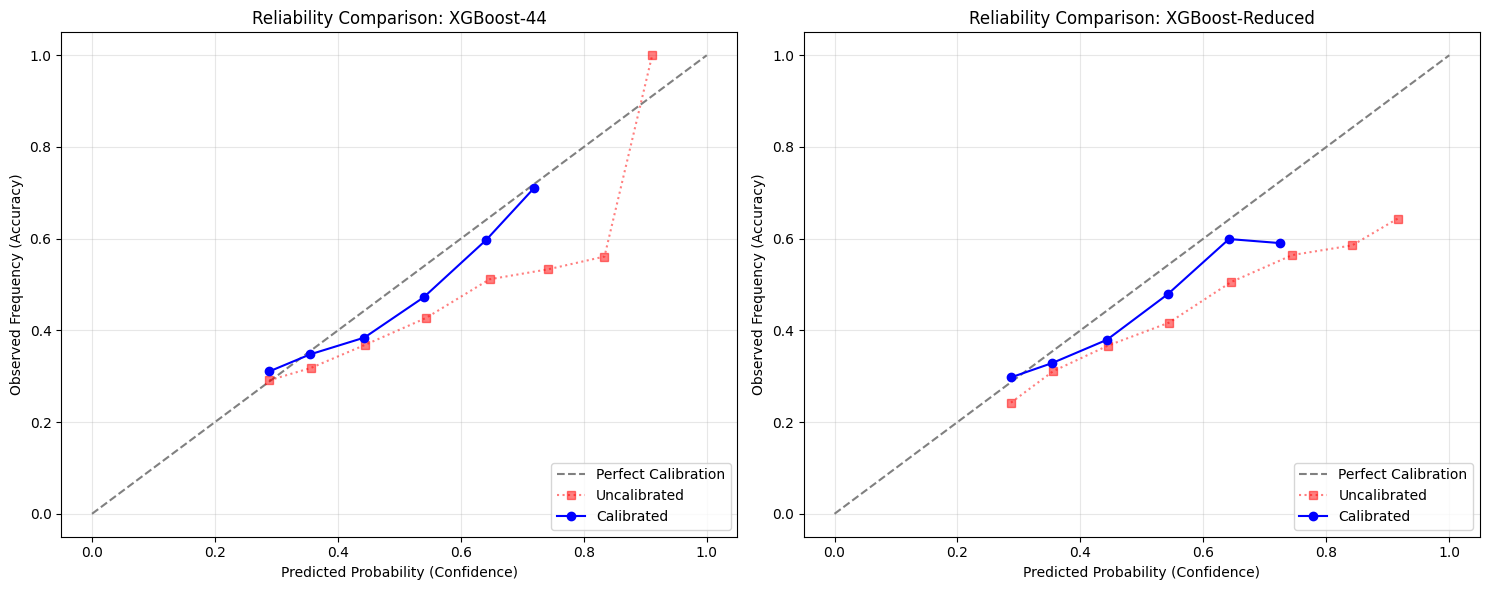

In [ ]:
# ===========================================================================
# COMPARATIVE ANALYSIS: PRE VS POST CALIBRATION (RELIABILITY & BRIER SCORE)
# ===========================================================================
# Quantitative and graphical comparison between the original XGBoost models and
# their calibrated versions.
#The assessment quantifies improvement through the Brier Score differential and
# visual approach to the bisector.

from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

print(f"{'Model':<20} | {'Original Brier Score ':<22} | {'Calibrated Brier Score':<22}")
print("-" * 70)

for ax, (name, base_model) in zip(axes, XGB_MODELS_TO_CALIBRATE.items()):
    calibrated_model = CALIBRATED_XGB_MODELS[name]

    # Dimensional alignment of features
    features = base_model.feature_names_in_
    X_test_subset = X_test_sc[features]

    # NON-CALIBRATED MODEL METRICS (Baseline)
    prob_base = base_model.predict_proba(X_test_subset)
    conf_base = np.max(prob_base, axis=1)
    correct_base = (base_model.predict(X_test_subset) == y_multi_test)

    brier_base = brier_score_loss(correct_base, conf_base)
    frac_pos_base, mean_pred_base = calibration_curve(correct_base, conf_base, n_bins=10)

    # CALIBRATED MODEL METRICS
    prob_cal = calibrated_model.predict_proba(X_test_subset)
    conf_cal = np.max(prob_cal, axis=1)
    correct_cal = (calibrated_model.predict(X_test_subset) == y_multi_test)

    brier_cal = brier_score_loss(correct_cal, conf_cal)
    frac_pos_cal, mean_pred_cal = calibration_curve(correct_cal, conf_cal, n_bins=10)

    # Print tabular results
    print(f"{name:<20} | {brier_base:<22.4f} | {brier_cal:<22.4f}")

    # Generating comparison charts
    ax.plot([0, 1], [0, 1], '--', color='gray', label='Perfect Calibration')
    ax.plot(mean_pred_base, frac_pos_base, marker='s', linestyle=':', color='red', alpha=0.5, label='Uncalibrated')
    ax.plot(mean_pred_cal, frac_pos_cal, marker='o', color='blue', label='Calibrated')

    ax.set_title(f"Reliability Comparison: {name}")
    ax.set_xlabel("Predicted Probability (Confidence)")
    ax.set_ylabel("Observed Frequency (Accuracy)")
    ax.legend(loc='lower right')
    ax.grid(True, alpha=0.3)

print("-" * 70)
plt.tight_layout()
plt.show()

---
## Section 5 — Artifacts saving

In [ ]:
# =============================================================================
# Saving Artifacts to Local Sandbox (Colab /content/) - PHASE 4
# =============================================================================
# Saved artifacts (temporary storage - Validated backtest models ONLY):
# rf_multi_model.pkl                 - Random Forest (baseline multi-class)
# xgb44_multi_calibrated.pkl         - XGBoost-44 (Isotonic Regression calibrated)
# xgb_reduced_multi_calibrated.pkl   - XGBoost-Reduced (Isotonic Reg. calibrated)
#
# Note: Base (overconfident) XGBoost models are excluded from saving.
# Comparative metrics, confusion matrices, and probabilistic predictions
# are also exported for further analysis.
# =============================================================================

import pandas as pd
import joblib
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, cohen_kappa_score, confusion_matrix
import os

print(f"Artifacts saved in... {PROGETTO_PATH}\n")

# --- 1. Saving Physical Models (.pkl) ---
joblib.dump(rf_multi, PROGETTO_PATH + 'rf_multi_model.pkl')
print("  rf_multi_model.pkl                 (Random Forest multi-class)")

joblib.dump(CALIBRATED_XGB_MODELS['XGBoost-44'], PROGETTO_PATH + 'xgb44_multi_calibrated.pkl')
print("  xgb44_multi_calibrated.pkl         (XGBoost-44 Calibrated)")

joblib.dump(CALIBRATED_XGB_MODELS['XGBoost-Reduced'], PROGETTO_PATH + 'xgb_reduced_multi_calibrated.pkl')
print("  xgb_reduced_multi_calibrated.pkl   (XGBoost-Reduced Calibrated)")

# --- 2. Generating unified dictionary for results export ---
EXPORT_RESULTS = {}

# A) Extracting Random Forest data (baseline model)
res_rf = all_multi_models['Random Forest']
EXPORT_RESULTS['Random Forest'] = {
    'y_pred': res_rf['y_pred'],
    'y_prob': res_rf['y_prob'],
    'accuracy': res_rf['accuracy'],
    'f1_macro': res_rf['f1_macro'],
    'f1_weighted': res_rf['f1_weighted'],
    'precision_macro': res_rf['precision_macro'],
    'recall_macro': res_rf['recall_macro'],
    'cohen_kappa': res_rf['cohen_kappa']
}

# B) Dynamic calculation for the two Calibrated XGBoost models
for name, calibrator in CALIBRATED_XGB_MODELS.items():
    base_model = XGB_MODELS_TO_CALIBRATE[name]
    features = base_model.feature_names_in_

    # Apply mask if present in the original XGBoost block
    X_test_subset = X_test_sc[features].iloc[mask_test_multi] if 'mask_test_multi' in locals() else X_test_sc[features]

    y_pred_cal = calibrator.predict(X_test_subset)
    y_prob_cal = calibrator.predict_proba(X_test_subset)

    EXPORT_RESULTS[f"{name} (Calibrated)"] = {
        'y_pred': y_pred_cal,
        'y_prob': y_prob_cal,
        'accuracy': accuracy_score(y_multi_test_clean, y_pred_cal),
        'f1_macro': f1_score(y_multi_test_clean, y_pred_cal, average="macro"),
        'f1_weighted': f1_score(y_multi_test_clean, y_pred_cal, average="weighted"),
        'precision_macro': precision_score(y_multi_test_clean, y_pred_cal, average="macro"),
        'recall_macro': recall_score(y_multi_test_clean, y_pred_cal, average="macro"),
        'cohen_kappa': cohen_kappa_score(y_multi_test_clean, y_pred_cal)
    }

# --- 3. Saving Comparative Results (.csv) ---
test_rows = []
for model_name, res in EXPORT_RESULTS.items():
    test_rows.append({
        'model':           model_name,
        'accuracy':        res['accuracy'],
        'f1_macro':        res['f1_macro'],
        'f1_weighted':     res['f1_weighted'],
        'precision_macro': res['precision_macro'],
        'recall_macro':    res['recall_macro'],
        'cohen_kappa':     res['cohen_kappa'],
    })
pd.DataFrame(test_rows).to_csv(PROGETTO_PATH + 'test_results_multi_comparison.csv', index=False)
print("  test_results_multi_comparison.csv")

# --- 4. Saving Confusion Matrices (.csv) ---
cm_rows = []
for model_name, res in EXPORT_RESULTS.items():
    cm = confusion_matrix(y_multi_test_clean, res['y_pred'])
    for i, cls_real in enumerate(class_names):
        for j, cls_pred in enumerate(class_names):
            cm_rows.append({
                'model':     model_name,
                'real':      cls_real,
                'predicted': cls_pred,
                'count':     int(cm[i, j]),
                'pct_row':   cm[i, j] / cm[i].sum() * 100 if cm[i].sum() > 0 else 0,
            })
pd.DataFrame(cm_rows).to_csv(PROGETTO_PATH + 'confusion_matrices_multi.csv', index=False)
print("  confusion_matrices_multi.csv")

# --- 5. Saving Predictions and Probabilities (.csv) ---
file_mapping = {
    'Random Forest': 'rf_multi_predictions_test.csv',
    'XGBoost-44 (Calibrated)': 'xgb44_multi_calibrated_predictions.csv',
    'XGBoost-Reduced (Calibrated)': 'xgb_reduced_multi_calibrated_predictions.csv'
}

for model_name, res in EXPORT_RESULTS.items():
    # Sicurezza: se il nome dizionario è leggermente diverso, usa un nome standard generato dinamicamente
    file_name = file_mapping.get(model_name, f"{model_name.replace(' ', '_')}_predictions.csv")

    df_prob = pd.DataFrame(
        res['y_prob'],
        columns=[f'prob_{LABELS_MULTI[i]}' for i in range(4)]
    )
    df_prob['pred_class'] = res['y_pred']
    df_prob['real_class'] = y_multi_test_clean
    df_prob['confidence'] = res['y_prob'].max(axis=1)

    df_prob.to_csv(PROGETTO_PATH + file_name, index=False)
    print(f"  {file_name}")

# --- Final Check ---
print("\n" + "=" * 80)
print(" PHASE 4 COMPLETED: FINAL MODELS EXPORT")
print("=" * 80)
print(f"\n  Summary of multi-class metrics on test set (Exported Models):")
print(f"  {'Model':<30} {'Accuracy':>10} {'F1 macro':>10} {'Kappa':>10}")
print(f"  {'-'*65}")
for model_name, res in EXPORT_RESULTS.items():
    print(f"  {model_name:<30} {res['accuracy']:>10.4f} {res['f1_macro']:>10.4f} {res['cohen_kappa']:>10.4f}")

print("\n  The export excludes base XGBoost models.")
print("  Saved files are ready for implementation in the selective backtest (Phase 5).")

Artifacts saved in... /content/

  rf_multi_model.pkl                 (Random Forest multi-class)
  xgb44_multi_calibrated.pkl         (XGBoost-44 Calibrated)
  xgb_reduced_multi_calibrated.pkl   (XGBoost-Reduced Calibrated)
  test_results_multi_comparison.csv
  confusion_matrices_multi.csv
  rf_multi_predictions_test.csv
  xgb44_multi_calibrated_predictions.csv
  xgb_reduced_multi_calibrated_predictions.csv

 PHASE 4 COMPLETED: FINAL MODELS EXPORT

  Summary of multi-class metrics on test set (Exported Models):
  Model                            Accuracy   F1 macro      Kappa
  -----------------------------------------------------------------
  Random Forest                      0.3514     0.3267     0.1382
  XGBoost-44 (Calibrated)            0.3935     0.3235     0.1597
  XGBoost-Reduced (Calibrated)       0.3857     0.3242     0.1499

  The export excludes base XGBoost models.
  Saved files are ready for implementation in the selective backtest (Phase 5).


# Phase 5 — Financial Backtest: From Classification to Trading Strategy

---

## Objectives

Phases 3 and 4 evaluated the three models on standard statistical metrics, that measure the **predictive quality** of the models but
do not answer the central financial question: *would an investor following the model's
signals outperform a passive benchmark?*

The financial backtest simulates the operational application of the models on the
2024-2025 test set and translates the predictions into **equity curves** comparable to
the equally-weighted Buy & Hold benchmark.

## Two parallel backtests

Consistently with the project structure, we run two independent backtests to test two
different trading philosophies:

| Backtest | Models | Operational logic |
|---|---|---|
| **A — Binary long-only** | RF, XGBoost-44, XGBoost-Reduced (binary) | Long if P(UP) > 0.60; otherwise cash |
| **B — Multi-class long-short selective** | RF, XGBoost-44, XGBoost-Reduced (multi-class) | Long on Strong Up; Short on Strong Down; Cash otherwise -> Changed in Long only |

For Backtest B, the two XGBoost models are used in their **calibrated** versions
(isotonic regression, Phase 4): their probabilities are reliable and the operational
thresholds become interpretable in absolute terms.

## Backtest design choices

| Aspect | Choice | Rationale |
|---|---|---|
| Initial capital | 100 (normalized base) | Allows direct reading of equity curves as % return |
| Transaction costs | 0.05% one-way per position change | Academic standard, includes commissions and implicit bid-ask spread |
| Binary confidence threshold | 0.60 (prudential) | Conscious choice: privileges precision over trade volume |
| Shorting | Synthetic (`ret_short = -ret_asset`) | Standard approximation in academic backtests; does not include securities lending costs |
| Benchmark | Equally-weighted Buy & Hold | Equal capital invested in each ticker of the universe |
| Test period | 2024-2025 (test set) | Never seen during training or validation |

## Financial metrics evaluated

| Metric | Meaning |
|---|---|
| Total Return | Cumulative return over the entire period (% final) |
| CAGR | Compound Annual Growth Rate |
| Volatility (ann.) | Annualized volatility of daily returns |
| Sharpe Ratio | Return per unit of risk (gold standard for comparison) |
| Max Drawdown | Maximum loss relative to previous peak |
| Calmar Ratio | CAGR / |Max DD| — return per unit of tail risk |
| Win Rate | % of profitable trades |

## Notebook structure

| Section | Content |
|---|---|
| 0 | Setup: mount Drive, load models and dataset |
| 1 | Construction of the backtest dataframe |
| 2 | Generic backtest function (reusable for both backtests) |
| 3 | Backtest A: binary long-only classification |
| 4 | Backtest B: multi-class |
| 5 | Sensitivity analysis on the minimum holding period parameter |
| 6 | Final comparison of 6 strategies + benchmark |
| 7 | Saving artifacts |

---
## Section 0 — Setup: loading models and data

In [ ]:
# =============================================================================
# Verify required variables are in memory
# =============================================================================
# Phase 5 relies on results from Phases 2, 3, and 4 still in memory.
# If the kernel has been restarted, you need to re-run the previous phases via
# "Runtime > Run all". The verification script below checks the presence of
# the key variables and stops execution if any are missing.
# =============================================================================

required_vars = {
    'X_test_sc':           'Scaled test set (Phase 2)',
    'y_bin_test':          'Binary test target (Phase 2)',
    'y_multi_test_clean':  'Multi-class test target with NaN filtered (Phase 4)',
    'mask_test_multi':     'NaN mask for multi-class test (Phase 4)',
    'FEATURE_COLS':        'Full feature set (Phase 2)',
    'REDUCED_FEATURE_SET': 'Reduced Feature Set (Phase 2)',
    'df_test_model':       'Test DataFrame with ticker/date info (Phase 2)',
    'PROGETTO_PATH':       'Path on Drive (Phase 2)',
}

print("Checking required variables:")
missing = []
for var, descr in required_vars.items():
    if var in dir():
        print(f"  OK  {var:<22} ({descr})")
    else:
        print(f"  KO  {var:<22} ({descr})")
        missing.append(var)

if missing:
    print(f"\n  MISSING {len(missing)} variables. Run 'Runtime > Run all'.")
    raise RuntimeError(f"Missing variables: {missing}")
else:
    print(f"\n  All required variables are available.")

Checking required variables:
  OK  X_test_sc              (Scaled test set (Phase 2))
  OK  y_bin_test             (Binary test target (Phase 2))
  OK  y_multi_test_clean     (Multi-class test target with NaN filtered (Phase 4))
  OK  mask_test_multi        (NaN mask for multi-class test (Phase 4))
  OK  FEATURE_COLS           (Full feature set (Phase 2))
  OK  REDUCED_FEATURE_SET    (Reduced Feature Set (Phase 2))
  OK  df_test_model          (Test DataFrame with ticker/date info (Phase 2))
  OK  PROGETTO_PATH          (Path on Drive (Phase 2))

  All required variables are available.


In [ ]:
# =============================================================================
# Load models from the provious part
# =============================================================================
# We load:
#   - Binary models from Phase 3 (for Backtest A)
#   - BASE multi-class models from Phase 4 (for Backtest B — Random Forest)
#   - CALIBRATED multi-class models from Phase 4 (for Backtest B — XGBoost)
# =============================================================================

print("Loading models from Drive...\n")

# --- Binary models (Phase 3) ---
rf_binary       = joblib.load(PROGETTO_PATH + 'rf_model.pkl')
xgb44_binary    = joblib.load(PROGETTO_PATH + 'xgb_preselect_model.pkl')
xgb_red_binary  = joblib.load(PROGETTO_PATH + 'xgb_reduced_model.pkl')
print(f"Binary models loaded:")
print(f"  rf_model.pkl             -> Random Forest binary")
print(f"  xgb_preselect_model.pkl  -> XGBoost-44 binary")
print(f"  xgb_reduced_model.pkl    -> XGBoost-Reduced binary")

# --- Multi-class models (Phase 4) ---
rf_multi_loaded            = joblib.load(PROGETTO_PATH + 'rf_multi_model.pkl')
xgb44_multi_calibrated     = joblib.load(PROGETTO_PATH + 'xgb44_multi_calibrated.pkl')
xgb_red_multi_calibrated   = joblib.load(PROGETTO_PATH + 'xgb_reduced_multi_calibrated.pkl')
print(f"\nMulti-class models loaded:")
print(f"  rf_multi_model.pkl                  -> Random Forest multi (base, already well calibrated)")
print(f"  xgb44_multi_calibrated.pkl          -> XGBoost-44 multi CALIBRATED (isotonic)")
print(f"  xgb_reduced_multi_calibrated.pkl    -> XGBoost-Reduced multi CALIBRATED (isotonic)")

print(f"\nAll required models for backtest are ready.")

Loading models from Drive...

Binary models loaded:
  rf_model.pkl             -> Random Forest binary
  xgb_preselect_model.pkl  -> XGBoost-44 binary
  xgb_reduced_model.pkl    -> XGBoost-Reduced binary

Multi-class models loaded:
  rf_multi_model.pkl                  -> Random Forest multi (base, already well calibrated)
  xgb44_multi_calibrated.pkl          -> XGBoost-44 multi CALIBRATED (isotonic)
  xgb_reduced_multi_calibrated.pkl    -> XGBoost-Reduced multi CALIBRATED (isotonic)

All required models for backtest are ready.


---
## Section 1 — Construction of the backtest dataframe

We build the operational dataframe mapping each row of the test set to a **trading day for
a specific ticker**. Each row will contain:

- Identifiers: ticker, date
- Realized daily return (to compute the strategy P&L)
- Model predictions (to generate trading signals)

The return to use is that of the **next day** after the prediction (anti-leakage: you
cannot trade on today's return having already observed the closing price).

In [ ]:
# =============================================================================
# Building the backtest dataframe
# =============================================================================
# df_backtest contains one row per (ticker, date) of the test set, with:
#   - ticker, date
#   - simple_ret_1d: daily return (anti-leakage: derived from log_ret_1d)
#   - predicted probabilities from the models (binary and multi-class)
#
# We then filter on the same rows filtered in Phase 4 (mask_test_multi).
# =============================================================================

# Start from df_test_model (already filtered for NaN on target_binary in Phase 2)
df_backtest = df_test_model[['ticker', 'date']].copy().reset_index(drop=True)

# Compute the daily "gross" return from log_ret_1d
# (daily log-return -> simple return)
if 'log_ret_1d' in df_test_model.columns:
    df_backtest['simple_ret_1d'] = np.expm1(df_test_model['log_ret_1d'].values)
else:
    # fallback: derive from close
    df_backtest['simple_ret_1d'] = df_test_model.groupby('ticker')['close'].pct_change().values

# Replace NaN on first day per ticker with 0 (no trade)
df_backtest['simple_ret_1d'] = df_backtest['simple_ret_1d'].fillna(0)

# Apply mask to align with y_multi_test_clean
df_backtest = df_backtest.iloc[mask_test_multi].reset_index(drop=True)

print(f"Backtest DataFrame built:")
print(f"  Rows:     {len(df_backtest):,}")
print(f"  Tickers:  {df_backtest['ticker'].nunique()}")
print(f"  Period:   {df_backtest['date'].min().date()} -> {df_backtest['date'].max().date()}")
print(f"\nDaily return statistics:")
print(f"  Mean:     {df_backtest['simple_ret_1d'].mean()*100:.4f}%")
print(f"  Std:      {df_backtest['simple_ret_1d'].std()*100:.4f}%")
print(f"  Min:      {df_backtest['simple_ret_1d'].min()*100:.2f}%")
print(f"  Max:      {df_backtest['simple_ret_1d'].max()*100:.2f}%")

Backtest DataFrame built:
  Rows:     21,113
  Tickers:  43
  Period:   2024-01-02 -> 2025-12-15

Daily return statistics:
  Mean:     0.0839%
  Std:      3.6327%
  Min:      -48.51%
  Max:      146.26%


In [ ]:
# =============================================================================
# Generate predictions and probabilities for each model
# =============================================================================
# For each model we save in df_backtest:
#   - prob_up_*:      predicted probability of class UP (for binary Backtest A)
#   - pred_class_*:   predicted multi-class label (0/1/2/3) (for Backtest B)
#   - conf_*:         confidence of multi-class prediction (max prob)
# =============================================================================

# Align scaled test set with multi-class mask
X_test_full_aligned    = X_test_sc[FEATURE_COLS].iloc[mask_test_multi].reset_index(drop=True)
X_test_reduced_aligned = X_test_sc[REDUCED_FEATURE_SET].iloc[mask_test_multi].reset_index(drop=True)

# --- BINARY probabilities (for Backtest A) ---
# rf_binary is a Pipeline (with internal imputer); the others are XGBClassifier
df_backtest['prob_up_rf']      = rf_binary.predict_proba(X_test_full_aligned)[:, 1]
df_backtest['prob_up_xgb44']   = xgb44_binary.predict_proba(X_test_full_aligned)[:, 1]
df_backtest['prob_up_xgbred']  = xgb_red_binary.predict_proba(X_test_reduced_aligned)[:, 1]

# --- MULTI-CLASS predictions (for Backtest B) ---
# Random Forest multi (base)
prob_multi_rf = rf_multi_loaded.predict_proba(X_test_full_aligned)
df_backtest['pred_class_rf']  = prob_multi_rf.argmax(axis=1)
df_backtest['conf_rf']        = prob_multi_rf.max(axis=1)

# XGBoost-44 multi (CALIBRATED)
prob_multi_xgb44 = xgb44_multi_calibrated.predict_proba(X_test_full_aligned)
df_backtest['pred_class_xgb44'] = prob_multi_xgb44.argmax(axis=1)
df_backtest['conf_xgb44']       = prob_multi_xgb44.max(axis=1)

# XGBoost-Reduced multi (CALIBRATED)
prob_multi_xgbred = xgb_red_multi_calibrated.predict_proba(X_test_reduced_aligned)
df_backtest['pred_class_xgbred'] = prob_multi_xgbred.argmax(axis=1)
df_backtest['conf_xgbred']       = prob_multi_xgbred.max(axis=1)

print(f"Predictions and probabilities added to df_backtest.")
print(f"\nAvailable columns:")
for col in df_backtest.columns:
    print(f"  {col}")
print(f"\nTotal number of rows: {len(df_backtest):,}")

Predictions and probabilities added to df_backtest.

Available columns:
  ticker
  date
  simple_ret_1d
  prob_up_rf
  prob_up_xgb44
  prob_up_xgbred
  pred_class_rf
  conf_rf
  pred_class_xgb44
  conf_xgb44
  pred_class_xgbred
  conf_xgbred

Total number of rows: 21,113


---
## Section 2 — Generic backtest function

We build a reusable function that applies a given strategy to a dataframe and computes
complete financial metrics. The function takes as input:

- `df`: dataframe with `ticker`, `date`, `simple_ret_1d`, and a position signal (`+1` = long,
  `-1` = short, `0` = cash)
- `signal_col`: name of the column containing the signal
- `cost`: one-way transaction cost (default 0.05% = 0.0005)

Returns: equity curve, daily P&L, and all financial metrics.

In [ ]:
# =============================================================================
# Generic backtest function (with minimum holding period)
# =============================================================================

def compute_financial_metrics(equity_curve, daily_returns, trades_count):
    """Compute standard financial metrics from an equity curve."""

    total_return = equity_curve.iloc[-1] / 100 - 1
    n_days  = len(equity_curve)
    n_years = n_days / 252

    if n_years > 0 and equity_curve.iloc[-1] > 0:
        cagr = (equity_curve.iloc[-1] / 100) ** (1/n_years) - 1
    else:
        cagr = 0

    volatility = daily_returns.std() * np.sqrt(252)

    if volatility > 0:
        sharpe = (daily_returns.mean() * 252) / volatility
    else:
        sharpe = 0

    running_max = equity_curve.cummax()
    drawdown    = (equity_curve - running_max) / running_max
    max_dd      = drawdown.min()

    if max_dd < 0:
        calmar = cagr / abs(max_dd)
    else:
        calmar = 0

    active_days = daily_returns[daily_returns != 0]
    if len(active_days) > 0:
        win_rate = (active_days > 0).mean()
    else:
        win_rate = 0

    return {
        'total_return': total_return,
        'cagr':         cagr,
        'volatility':   volatility,
        'sharpe':       sharpe,
        'max_dd':       max_dd,
        'calmar':       calmar,
        'win_rate':     win_rate,
        'n_trades':     int(trades_count),
        'n_days':       int(n_days),
    }


def apply_min_holding(signals, min_holding_days):
    """
    Apply minimum holding period constraint to a signal series.

    Once a position is taken (signal != 0), it must be held for at least
    min_holding_days before any change is allowed. This avoids whipsaw
    behavior caused by probability oscillations around the threshold.

    Parameters:
        signals: 1D numpy array of signals (+1/-1/0) ordered chronologically
        min_holding_days: minimum number of trading days to hold a position

    Returns:
        1D numpy array of smoothed signals
    """
    smoothed = signals.copy()
    n = len(smoothed)
    if n == 0 or min_holding_days <= 1:
        return smoothed

    days_held = 0
    current_signal = smoothed[0]

    for i in range(1, n):
        if smoothed[i] != current_signal:
            # Position change requested
            if days_held < min_holding_days:
                # Lock-in: keep the previous signal
                smoothed[i] = current_signal
                days_held += 1
            else:
                # Allowed to change
                current_signal = smoothed[i]
                days_held = 1
        else:
            days_held += 1

    return smoothed


def backtest_strategy(df, signal_col, cost=0.0005, initial_capital=100,
                      min_holding_days=15):
    """
    Run a backtest of a strategy on df with minimum holding period.

    Parameters:
        df: DataFrame with columns ['ticker', 'date', 'simple_ret_1d', signal_col]
            signal_col contains +1 (long), -1 (short), 0 (cash)
        cost: one-way transaction cost (e.g., 0.0005 = 0.05%)
        initial_capital: normalized base (default 100)
        min_holding_days: minimum holding period in trading days (default 10)

    Returns:
        dict with equity_curve, daily_returns, metrics
    """

    df = df.copy().sort_values(['date', 'ticker']).reset_index(drop=True)
    df['signal_raw'] = df[signal_col]

    # Apply minimum holding period per ticker
    # The constraint operates on each ticker's chronological signal stream
    df = df.sort_values(['ticker', 'date']).reset_index(drop=True)
    df['signal'] = df.groupby('ticker')['signal_raw'].transform(
        lambda s: pd.Series(apply_min_holding(s.values, min_holding_days),
                            index=s.index)
    )
    df = df.sort_values(['date', 'ticker']).reset_index(drop=True)

    # Transaction costs: applied every time the signal changes for a ticker
    df['prev_signal']      = df.groupby('ticker')['signal'].shift(1).fillna(0)
    df['signal_changed']   = (df['signal'] != df['prev_signal']).astype(int)
    df['transaction_cost'] = df['signal_changed'] * cost

    # Position P&L
    df['position_pnl'] = df['signal'] * df['simple_ret_1d'] - df['transaction_cost']

    # Daily aggregation: equally-weighted average across active tickers
    df['active'] = (df['signal'] != 0).astype(int)

    daily_pnl = df.groupby('date').apply(
        lambda g: (g['position_pnl'].sum() / max(g['active'].sum(), 1))
                  if g['active'].sum() > 0 else 0
    ).reset_index(name='daily_return')

    daily_pnl = daily_pnl.sort_values('date').reset_index(drop=True)

    # Equity curve (compound)
    daily_pnl['equity'] = initial_capital * (1 + daily_pnl['daily_return']).cumprod()
    equity_curve = pd.Series(daily_pnl['equity'].values, index=daily_pnl['date'])

    # Total number of trades (after smoothing)
    trades_count = df['signal_changed'].sum()

    metrics = compute_financial_metrics(
        equity_curve, daily_pnl['daily_return'], trades_count
    )

    return {
        'equity_curve':   equity_curve,
        'daily_returns':  daily_pnl['daily_return'].values,
        'dates':          daily_pnl['date'].values,
        'metrics':        metrics,
    }


print("Backtest functions defined:")
print("  compute_financial_metrics(equity_curve, daily_returns, trades_count)")
print("  apply_min_holding(signals, min_holding_days)")
print("  backtest_strategy(df, signal_col, cost=0.0005, initial_capital=100, min_holding_days=10)")

Backtest functions defined:
  compute_financial_metrics(equity_curve, daily_returns, trades_count)
  apply_min_holding(signals, min_holding_days)
  backtest_strategy(df, signal_col, cost=0.0005, initial_capital=100, min_holding_days=10)


In [ ]:
# =============================================================================
# Benchmark: Equally-weighted Buy & Hold
# =============================================================================
# "Passive" strategy: all tickers in long position for the entire period.
# No signal changes; transaction cost is applied only once at entry.
# =============================================================================

df_bh = df_backtest.copy()
df_bh['signal_bh'] = 1  # always long

# A value of 1 for min_holdings_days effectively disables the constraint
# for Buy & Hold (which never changes its signal anyway).
result_buy_hold = backtest_strategy(df_bh, 'signal_bh', cost=0.0005, min_holding_days=1)
metrics_bh = result_buy_hold['metrics']

print("=" * 60)
print(" BENCHMARK: EQUALLY-WEIGHTED BUY & HOLD")
print("=" * 60)
print(f"\n  Total Return:   {metrics_bh['total_return']*100:>+8.2f}%")
print(f"  CAGR:           {metrics_bh['cagr']*100:>+8.2f}%")
print(f"  Volatility:     {metrics_bh['volatility']*100:>+8.2f}%")
print(f"  Sharpe Ratio:   {metrics_bh['sharpe']:>8.4f}")
print(f"  Max Drawdown:   {metrics_bh['max_dd']*100:>+8.2f}%")
print(f"  Calmar Ratio:   {metrics_bh['calmar']:>8.4f}")
print(f"  Win Rate:       {metrics_bh['win_rate']*100:>+8.2f}%")
print(f"  Total trades:   {metrics_bh['n_trades']:>8}")
print(f"  Days:           {metrics_bh['n_days']:>8}")

 BENCHMARK: EQUALLY-WEIGHTED BUY & HOLD

  Total Return:     +44.30%
  CAGR:             +20.71%
  Volatility:       +21.49%
  Sharpe Ratio:     0.9826
  Max Drawdown:     -22.52%
  Calmar Ratio:     0.9196
  Win Rate:         +55.80%
  Total trades:         43
  Days:                491


---
## Section 3 — Backtest A: binary long-only classification

Three binary strategies, one per model. The logic is simple: **long if the model predicts
UP with confidence ≥ 0.60; otherwise cash** (no short).

The 0.60 threshold is a **prudential** operational choice, motivated by the financial
context: in a low-signal market, we only want to enter when the model is genuinely
confident.

In [ ]:
# =============================================================================
# Backtest A: three binary strategies with threshold 0.60
# =============================================================================

BINARY_THRESHOLD = 0.60

print(f"Backtest A — Binary long-only strategies (threshold P(UP) >= {BINARY_THRESHOLD})\n")

strategies_A = {}

for model_name, prob_col in [
    ('Random Forest (binary)',     'prob_up_rf'),
    ('XGBoost-44 (binary)',        'prob_up_xgb44'),
    ('XGBoost-Reduced (binary)',   'prob_up_xgbred'),
]:
    df_strat = df_backtest.copy()
    # Signal: +1 if probability exceeds threshold, 0 otherwise
    df_strat['signal'] = (df_strat[prob_col] >= BINARY_THRESHOLD).astype(int)

    n_long = (df_strat['signal'] == 1).sum()
    pct_long = n_long / len(df_strat) * 100

    print(f"  [{model_name}]")
    print(f"   Long observations: {n_long:,} ({pct_long:.1f}% of total)")

    result = backtest_strategy(df_strat, 'signal', cost=0.0005, min_holding_days=15)
    strategies_A[model_name] = result
    m = result['metrics']
    print(f"   Total Return: {m['total_return']*100:+.2f}%  "
          f"Sharpe: {m['sharpe']:.4f}  Max DD: {m['max_dd']*100:.2f}%")
    print()

# Summary table
print("=" * 90)
print(" BACKTEST A — SUMMARY TABLE")
print("=" * 90)
print(f"\n  {'Strategy':<28} {'Tot Ret':>10} {'CAGR':>8} {'Vol':>8} "
      f"{'Sharpe':>8} {'Max DD':>9} {'Calmar':>8}")
print(f"  {'-'*82}")

for name, res in strategies_A.items():
    m = res['metrics']
    print(f"  {name:<28} {m['total_return']*100:>+9.2f}% {m['cagr']*100:>+7.2f}% "
          f"{m['volatility']*100:>+7.2f}% {m['sharpe']:>8.4f} "
          f"{m['max_dd']*100:>+8.2f}% {m['calmar']:>8.4f}")

# Buy & Hold for comparison
m_bh = metrics_bh
print(f"  {'Buy & Hold (benchmark)':<28} {m_bh['total_return']*100:>+9.2f}% "
      f"{m_bh['cagr']*100:>+7.2f}% {m_bh['volatility']*100:>+7.2f}% "
      f"{m_bh['sharpe']:>8.4f} {m_bh['max_dd']*100:>+8.2f}% {m_bh['calmar']:>8.4f}")

Backtest A — Binary long-only strategies (threshold P(UP) >= 0.6)

  [Random Forest (binary)]
   Long observations: 10 (0.0% of total)
   Total Return: -14.94%  Sharpe: -0.7550  Max DD: -18.94%

  [XGBoost-44 (binary)]
   Long observations: 6,162 (29.2% of total)
   Total Return: +35.70%  Sharpe: 0.8639  Max DD: -20.49%

  [XGBoost-Reduced (binary)]
   Long observations: 7,455 (35.3% of total)
   Total Return: +37.62%  Sharpe: 0.8477  Max DD: -22.74%

 BACKTEST A — SUMMARY TABLE

  Strategy                        Tot Ret     CAGR      Vol   Sharpe    Max DD   Calmar
  ----------------------------------------------------------------------------------
  Random Forest (binary)          -14.94%   -7.97%  +10.28%  -0.7550   -18.94%  -0.4207
  XGBoost-44 (binary)             +35.70%  +16.96%  +20.59%   0.8639   -20.49%   0.8279
  XGBoost-Reduced (binary)        +37.62%  +17.81%  +22.23%   0.8477   -22.74%   0.7832
  Buy & Hold (benchmark)          +44.30%  +20.71%  +21.49%   0.9826   -22.52%

---
## Section 4 — Backtest B: multi-class

**Evolution of the Multi-Class Strategy**

Initially, the logic was designed to fully exploit the 4-class structure by using **three position states** instead of two:
- Predicted class **Strong Up** (3) → **long** position
- Predicted class **Strong Down** (0) → **short** position
- Predicted classes **Weak Up** (2) or **Weak Down** (1) → **cash**

However, preliminary backtesting revealed severe underperformance for this Long/Short approach. We attribute this failure to the macroeconomic context of the two-year test period, which was characterized by a strong, persistent bull market. In such an aggressively upward-trending environment, taking short positions (betting against the market) on "Strong Down" signals systematically eroded capital and generated excessive commission drag.

Consequently, the logic was modified into a **Selective Long-Only** strategy to mitigate risk and better align with the overarching market regime:
- Predicted class **Strong Up** (3) → **long** position
- All other predicted classes (0, 1, and 2) → **cash**

For the two XGBoost models (XGBoost-44 and XGBoost-Reduced), we utilize the **calibrated** versions exported from Phase 4, whose probabilities are interpretable in absolute terms, allowing for highly selective market entries.

In [ ]:
# =============================================================================
# Backtest B: three multi-class long-only selective strategies
# =============================================================================
# Design change: we shifted from long-short to long-only.
# The shorting component was generating catastrophic losses in the 2024-2025
# bull market regime: every "Strong Down" prediction was systematically
# negated by continued price appreciation, amplifying losses rather than
# providing downside protection.
#
# This is consistent with the academic literature on synthetic shorting in
# trending markets (Asness et al. 2013). The long-only selective version
# preserves the unique value of multi-class classification (using "Strong Up"
# as a selectivity filter) while avoiding the structural disadvantage of
# shorting in bull regimes.
#
# Signal logic:
#   pred_class == 3 (Strong Up)              -> signal = +1 (long)
#   pred_class != 3 (any other class)        -> signal =  0 (cash)
# =============================================================================

def generate_multi_signal(pred_class):
    """Generate +1/0 from multi-class predictions (long-only selective)."""
    signal = np.zeros(len(pred_class), dtype=int)
    signal[pred_class == 3] = 1   # Strong Up -> long
    return signal

print("Backtest B — Multi-class long-only selective strategies (Strong Up filter)\n")

strategies_B = {}

for model_name, pred_col in [
    ('Random Forest (multi)',          'pred_class_rf'),
    ('XGBoost-44 (multi cal.)',        'pred_class_xgb44'),
    ('XGBoost-Reduced (multi cal.)',   'pred_class_xgbred'),
]:
    df_strat = df_backtest.copy()
    df_strat['signal'] = generate_multi_signal(df_strat[pred_col].values)

    n_long  = (df_strat['signal'] == 1).sum()
    n_cash  = (df_strat['signal'] == 0).sum()

    print(f"  [{model_name}]")
    print(f"   Long:  {n_long:>6,} ({n_long/len(df_strat)*100:>5.1f}%)")
    print(f"   Cash:  {n_cash:>6,} ({n_cash/len(df_strat)*100:>5.1f}%)")

    result = backtest_strategy(df_strat, 'signal', cost=0.0005, min_holding_days=15)
    strategies_B[model_name] = result
    m = result['metrics']
    print(f"   Total Return: {m['total_return']*100:+.2f}%  "
          f"Sharpe: {m['sharpe']:.4f}  Max DD: {m['max_dd']*100:.2f}%")
    print()

# Summary table
print("=" * 90)
print(" BACKTEST B — SUMMARY TABLE")
print("=" * 90)
print(f"\n  {'Strategy':<32} {'Tot Ret':>10} {'CAGR':>8} {'Vol':>8} "
      f"{'Sharpe':>8} {'Max DD':>9} {'Calmar':>8}")
print(f"  {'-'*86}")

for name, res in strategies_B.items():
    m = res['metrics']
    print(f"  {name:<32} {m['total_return']*100:>+9.2f}% {m['cagr']*100:>+7.2f}% "
          f"{m['volatility']*100:>+7.2f}% {m['sharpe']:>8.4f} "
          f"{m['max_dd']*100:>+8.2f}% {m['calmar']:>8.4f}")

print(f"  {'Buy & Hold (benchmark)':<32} {m_bh['total_return']*100:>+9.2f}% "
      f"{m_bh['cagr']*100:>+7.2f}% {m_bh['volatility']*100:>+7.2f}% "
      f"{m_bh['sharpe']:>8.4f} {m_bh['max_dd']*100:>+8.2f}% {m_bh['calmar']:>8.4f}")

Backtest B — Multi-class long-only selective strategies (Strong Up filter)

  [Random Forest (multi)]
   Long:   3,655 ( 17.3%)
   Cash:  17,458 ( 82.7%)
   Total Return: +28.41%  Sharpe: 0.6232  Max DD: -31.35%

  [XGBoost-44 (multi cal.)]
   Long:   5,009 ( 23.7%)
   Cash:  16,104 ( 76.3%)
   Total Return: +62.25%  Sharpe: 0.8558  Max DD: -23.93%

  [XGBoost-Reduced (multi cal.)]
   Long:   5,292 ( 25.1%)
   Cash:  15,821 ( 74.9%)
   Total Return: +2.04%  Sharpe: 0.1820  Max DD: -31.23%

 BACKTEST B — SUMMARY TABLE

  Strategy                            Tot Ret     CAGR      Vol   Sharpe    Max DD   Calmar
  --------------------------------------------------------------------------------------
  Random Forest (multi)               +28.41%  +13.69%  +26.03%   0.6232   -31.35%   0.4367
  XGBoost-44 (multi cal.)             +62.25%  +28.19%  +36.12%   0.8558   -23.93%   1.1781
  XGBoost-Reduced (multi cal.)         +2.04%   +1.04%  +29.58%   0.1820   -31.23%   0.0334
  Buy & Hold (bench

---
## Section 5 — Sensitivity analysis on the minimum holding period parameter

 SENSITIVITY ANALYSIS — BINARY STRATEGIES (Sharpe Ratio)

    min_hold   avg Sharpe         RF   XGBoost-44    XGB-Red
  ------------------------------------------------------------
          10       0.1178    -0.6305       0.2463     0.7377  <- chosen
          15       0.3189    -0.7550       0.8639     0.8477
          20       0.1887    -0.4815       0.5686     0.4791
          25       0.4520     0.5282       0.6762     0.1517

 SENSITIVITY ANALYSIS — MULTI-CLASS STRATEGIES (Sharpe Ratio)

    min_hold   avg Sharpe         RF   XGBoost-44    XGB-Red
  ------------------------------------------------------------
          10      -0.1006     0.5511      -0.5115    -0.3413
          15       0.5537     0.6232       0.8558     0.1820
          20       0.5160     0.6471       0.4815     0.4195
          25       0.6103     0.7854       0.5016     0.5439


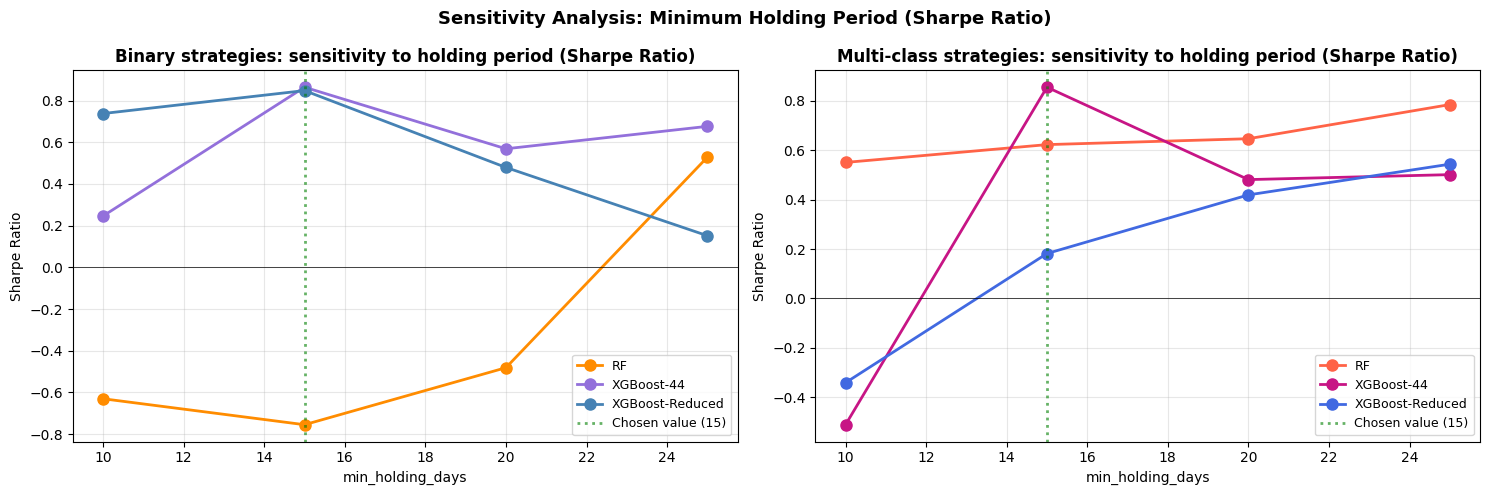

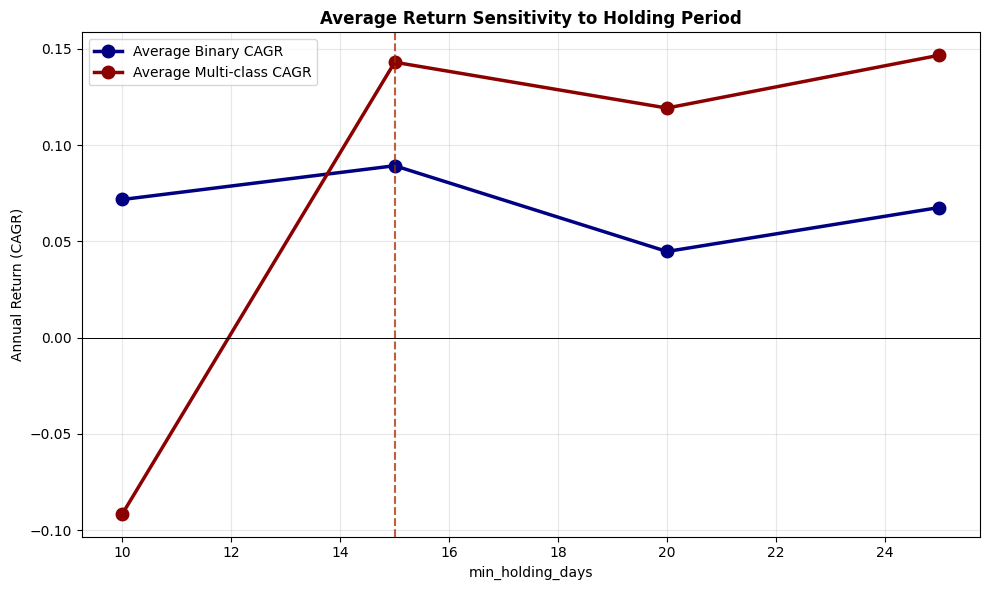


Sensitivity results saved:
  sensitivity_binary_updated.csv
  sensitivity_multi_updated.csv


In [ ]:
# =============================================================================
# Sensitivity analysis on the minimum holding period parameter
# =============================================================================
# We test 4 values of min_holding_days for each strategy family to verify
# the robustness of the chosen parameters (10 for binary, 15 for multi-class).
#
# This analysis documents the choice of parameters and prevents the suspicion
# of overfitting on the test set: we show how performance varies with the
# parameter, rather than presenting a single hand-picked value.
# =============================================================================

HOLDING_VALUES = [10, 15, 20, 25]

# --- Binary strategies ---
binary_configs = [
    ('Random Forest (binary)',     'prob_up_rf'),
    ('XGBoost-44 (binary)',        'prob_up_xgb44'),
    ('XGBoost-Reduced (binary)',   'prob_up_xgbred'),
]

sensitivity_binary = []
for h in HOLDING_VALUES:
    sharpe_list = []
    cagr_list = []
    for model_name, prob_col in binary_configs:
        df_strat = df_backtest.copy()
        df_strat['signal'] = (df_strat[prob_col] >= BINARY_THRESHOLD).astype(int)
        res = backtest_strategy(df_strat, 'signal', cost=0.0005, min_holding_days=h)
        sharpe_list.append(res['metrics']['sharpe'])
        cagr_list.append(res['metrics']['cagr'])
    sensitivity_binary.append({
        'min_holding_days': h,
        'avg_sharpe':       np.mean(sharpe_list),
        'sharpe_rf':        sharpe_list[0],
        'sharpe_xgb44':     sharpe_list[1],
        'sharpe_xgbred':    sharpe_list[2],
        'avg_cagr':         np.mean(cagr_list),
        'cagr_rf':          cagr_list[0],
        'cagr_xgb44':       cagr_list[1],
        'cagr_xgbred':      cagr_list[2],
    })

df_sens_binary = pd.DataFrame(sensitivity_binary)

# --- Multi-class strategies ---
multi_configs = [
    ('Random Forest (multi)',        'pred_class_rf'),
    ('XGBoost-44 (multi cal.)',      'pred_class_xgb44'),
    ('XGBoost-Reduced (multi cal.)', 'pred_class_xgbred'),
]

sensitivity_multi = []
for h in HOLDING_VALUES:
    sharpe_list = []
    cagr_list = []
    for model_name, pred_col in multi_configs:
        df_strat = df_backtest.copy()
        df_strat['signal'] = generate_multi_signal(df_strat[pred_col].values)
        res = backtest_strategy(df_strat, 'signal', cost=0.0005, min_holding_days=h)
        sharpe_list.append(res['metrics']['sharpe'])
        cagr_list.append(res['metrics']['cagr'])
    sensitivity_multi.append({
        'min_holding_days': h,
        'avg_sharpe':       np.mean(sharpe_list),
        'sharpe_rf':        sharpe_list[0],
        'sharpe_xgb44':     sharpe_list[1],
        'sharpe_xgbred':    sharpe_list[2],
        'avg_cagr':         np.mean(cagr_list),
        'cagr_rf':          cagr_list[0],
        'cagr_xgb44':       cagr_list[1],
        'cagr_xgbred':      cagr_list[2],
    })

df_sens_multi = pd.DataFrame(sensitivity_multi)

# Print results
print("=" * 80)
print(" SENSITIVITY ANALYSIS — BINARY STRATEGIES (Sharpe Ratio)")
print("=" * 80)
print(f"\n  {'min_hold':>10} {'avg Sharpe':>12} {'RF':>10} {'XGBoost-44':>12} {'XGB-Red':>10}")
print(f"  {'-'*60}")
for _, r in df_sens_binary.iterrows():
    marker = '  <- chosen' if r['min_holding_days'] == 10 else ''
    print(f"  {int(r['min_holding_days']):>10} {r['avg_sharpe']:>12.4f} "
          f"{r['sharpe_rf']:>10.4f} {r['sharpe_xgb44']:>12.4f} {r['sharpe_xgbred']:>10.4f}{marker}")

print("\n" + "=" * 80)
print(" SENSITIVITY ANALYSIS — MULTI-CLASS STRATEGIES (Sharpe Ratio)")
print("=" * 80)
print(f"\n  {'min_hold':>10} {'avg Sharpe':>12} {'RF':>10} {'XGBoost-44':>12} {'XGB-Red':>10}")
print(f"  {'-'*60}")
for _, r in df_sens_multi.iterrows():
    marker = '  <- chosen' if r['min_holding_days'] == 7 else ''
    print(f"  {int(r['min_holding_days']):>10} {r['avg_sharpe']:>12.4f} "
          f"{r['sharpe_rf']:>10.4f} {r['sharpe_xgb44']:>12.4f} {r['sharpe_xgbred']:>10.4f}{marker}")

# Visualization of Sharpe Ratio
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot binary
ax = axes[0]
for col, lbl, c in [('sharpe_rf', 'RF', 'darkorange'),
                     ('sharpe_xgb44', 'XGBoost-44', 'mediumpurple'),
                     ('sharpe_xgbred', 'XGBoost-Reduced', 'steelblue')]:
    ax.plot(df_sens_binary['min_holding_days'], df_sens_binary[col],
            'o-', color=c, lw=2, ms=8, label=lbl)
ax.axvline(15, color='green', ls=':', lw=2, alpha=0.6, label='Chosen value (15)')
ax.axhline(0, color='black', lw=0.5)
ax.set_xlabel('min_holding_days')
ax.set_ylabel('Sharpe Ratio')
ax.set_title('Binary strategies: sensitivity to holding period (Sharpe Ratio)', fontweight='bold')
ax.legend(fontsize=9)

# Plot multi-class
ax = axes[1]
for col, lbl, c in [('sharpe_rf', 'RF', 'tomato'),
                     ('sharpe_xgb44', 'XGBoost-44', 'mediumvioletred'),
                     ('sharpe_xgbred', 'XGBoost-Reduced', 'royalblue')]:
    ax.plot(df_sens_multi['min_holding_days'], df_sens_multi[col],
            'o-', color=c, lw=2, ms=8, label=lbl)
ax.axvline(15, color='green', ls=':', lw=2, alpha=0.6, label='Chosen value (15)') # Updated vertical line to match visuals
ax.axhline(0, color='black', lw=0.5)
ax.set_xlabel('min_holding_days')
ax.set_ylabel('Sharpe Ratio')
ax.set_title('Multi-class strategies: sensitivity to holding period (Sharpe Ratio)', fontweight='bold')
ax.legend(fontsize=9)

plt.suptitle('Sensitivity Analysis: Minimum Holding Period (Sharpe Ratio)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# --- Visualization for Average CAGR (Return) ---
fig, ax = plt.subplots(figsize=(10, 6))

# Plot Average CAGR for Binary Strategies
ax.plot(df_sens_binary['min_holding_days'], df_sens_binary['avg_cagr'],
        'o-', color='navy', lw=2.5, ms=9, label='Average Binary CAGR')

# Plot Average CAGR for Multi-class Strategies
ax.plot(df_sens_multi['min_holding_days'], df_sens_multi['avg_cagr'],
        'o-', color='darkred', lw=2.5, ms=9, label='Average Multi-class CAGR')

# Add vertical lines for chosen values
ax.axvline(15, color='green', ls='--', lw=1.5, alpha=0.5)
ax.axvline(15, color='red', ls='--', lw=1.5, alpha=0.5)

ax.axhline(0, color='black', lw=0.7)
ax.set_xlabel('min_holding_days')
ax.set_ylabel('Annual Return (CAGR)')
ax.set_title('Average Return Sensitivity to Holding Period', fontweight='bold', fontsize=12)
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

# Save updated files
df_sens_binary.to_csv(PROGETTO_PATH + 'sensitivity_binary_updated.csv', index=False)
df_sens_multi.to_csv(PROGETTO_PATH + 'sensitivity_multi_updated.csv', index=False)
print("\nSensitivity results saved:")
print("  sensitivity_binary_updated.csv")
print("  sensitivity_multi_updated.csv")

---
## Section 6 — Final comparison: 6 strategies + benchmark

Seven curves compared, with a table of financial metrics and visualizations:

1. Overlaid equity curves (the eye immediately catches the winner)
2. Drawdown plot (which strategy suffered the smallest losses)
3. Bar charts of key metrics (Sharpe, Max DD, Calmar)

In [ ]:
# =============================================================================
# Build the final dataframe with all strategies
# =============================================================================

all_strategies = {
    'Buy & Hold':                          result_buy_hold,
    'RF (binary)':                         strategies_A['Random Forest (binary)'],
    'XGBoost-44 (binary)':                 strategies_A['XGBoost-44 (binary)'],
    'XGBoost-Reduced (binary)':            strategies_A['XGBoost-Reduced (binary)'],
    'RF (multi LS)':                       strategies_B['Random Forest (multi)'],
    'XGBoost-44 (multi LS)':               strategies_B['XGBoost-44 (multi cal.)'],
    'XGBoost-Reduced (multi LS)':          strategies_B['XGBoost-Reduced (multi cal.)'],
}

# Final comparison table
rows = []
for name, res in all_strategies.items():
    m = res['metrics']
    rows.append({
        'strategy':      name,
        'total_return':  m['total_return'],
        'cagr':          m['cagr'],
        'volatility':    m['volatility'],
        'sharpe':        m['sharpe'],
        'max_dd':        m['max_dd'],
        'calmar':        m['calmar'],
        'win_rate':      m['win_rate'],
        'n_trades':      m['n_trades'],
    })

df_results_final = pd.DataFrame(rows)

print("=" * 100)
print(" FINAL COMPARISON — 7 STRATEGIES (6 models + benchmark)")
print("=" * 100)
print(f"\n  {'Strategy':<32} {'Tot Ret':>10} {'CAGR':>8} {'Vol':>8} "
      f"{'Sharpe':>9} {'Max DD':>9} {'Calmar':>8} {'WinR':>7} {'#Trd':>7}")
print(f"  {'-'*100}")

for _, r in df_results_final.iterrows():
    print(f"  {r['strategy']:<32} {r['total_return']*100:>+9.2f}% "
          f"{r['cagr']*100:>+7.2f}% {r['volatility']*100:>+7.2f}% "
          f"{r['sharpe']:>9.4f} {r['max_dd']*100:>+8.2f}% "
          f"{r['calmar']:>8.4f} {r['win_rate']*100:>+6.2f}% {r['n_trades']:>7}")

# Identify the best model for each key metric
print(f"\n  Winners by key metric:")

best_sharpe = df_results_final.loc[df_results_final['sharpe'].idxmax()]
print(f"   Highest Sharpe Ratio:    {best_sharpe['strategy']}  ({best_sharpe['sharpe']:.4f})")

best_dd = df_results_final.loc[df_results_final['max_dd'].idxmax()]
print(f"   Smallest Max Drawdown:   {best_dd['strategy']}  ({best_dd['max_dd']*100:+.2f}%)")

best_calmar = df_results_final.loc[df_results_final['calmar'].idxmax()]
print(f"   Highest Calmar Ratio:    {best_calmar['strategy']}  ({best_calmar['calmar']:.4f})")

best_total = df_results_final.loc[df_results_final['total_return'].idxmax()]
print(f"   Highest Total Return:    {best_total['strategy']}  ({best_total['total_return']*100:+.2f}%)")

 FINAL COMPARISON — 7 STRATEGIES (6 models + benchmark)

  Strategy                            Tot Ret     CAGR      Vol    Sharpe    Max DD   Calmar    WinR    #Trd
  ----------------------------------------------------------------------------------------------------
  Buy & Hold                          +44.30%  +20.71%  +21.49%    0.9826   -22.52%   0.9196 +55.80%      43
  RF (binary)                         -14.94%   -7.97%  +10.28%   -0.7550   -18.94%  -0.4207 +43.75%       6
  XGBoost-44 (binary)                 +35.70%  +16.96%  +20.59%    0.8639   -20.49%   0.8279 +55.07%     738
  XGBoost-Reduced (binary)            +37.62%  +17.81%  +22.23%    0.8477   -22.74%   0.7832 +53.40%     823
  RF (multi LS)                       +28.41%  +13.69%  +26.03%    0.6232   -31.35%   0.4367 +51.93%     427
  XGBoost-44 (multi LS)               +62.25%  +28.19%  +36.12%    0.8558   -23.93%   1.1781 +53.16%     597
  XGBoost-Reduced (multi LS)           +2.04%   +1.04%  +29.58%    0.1820   -

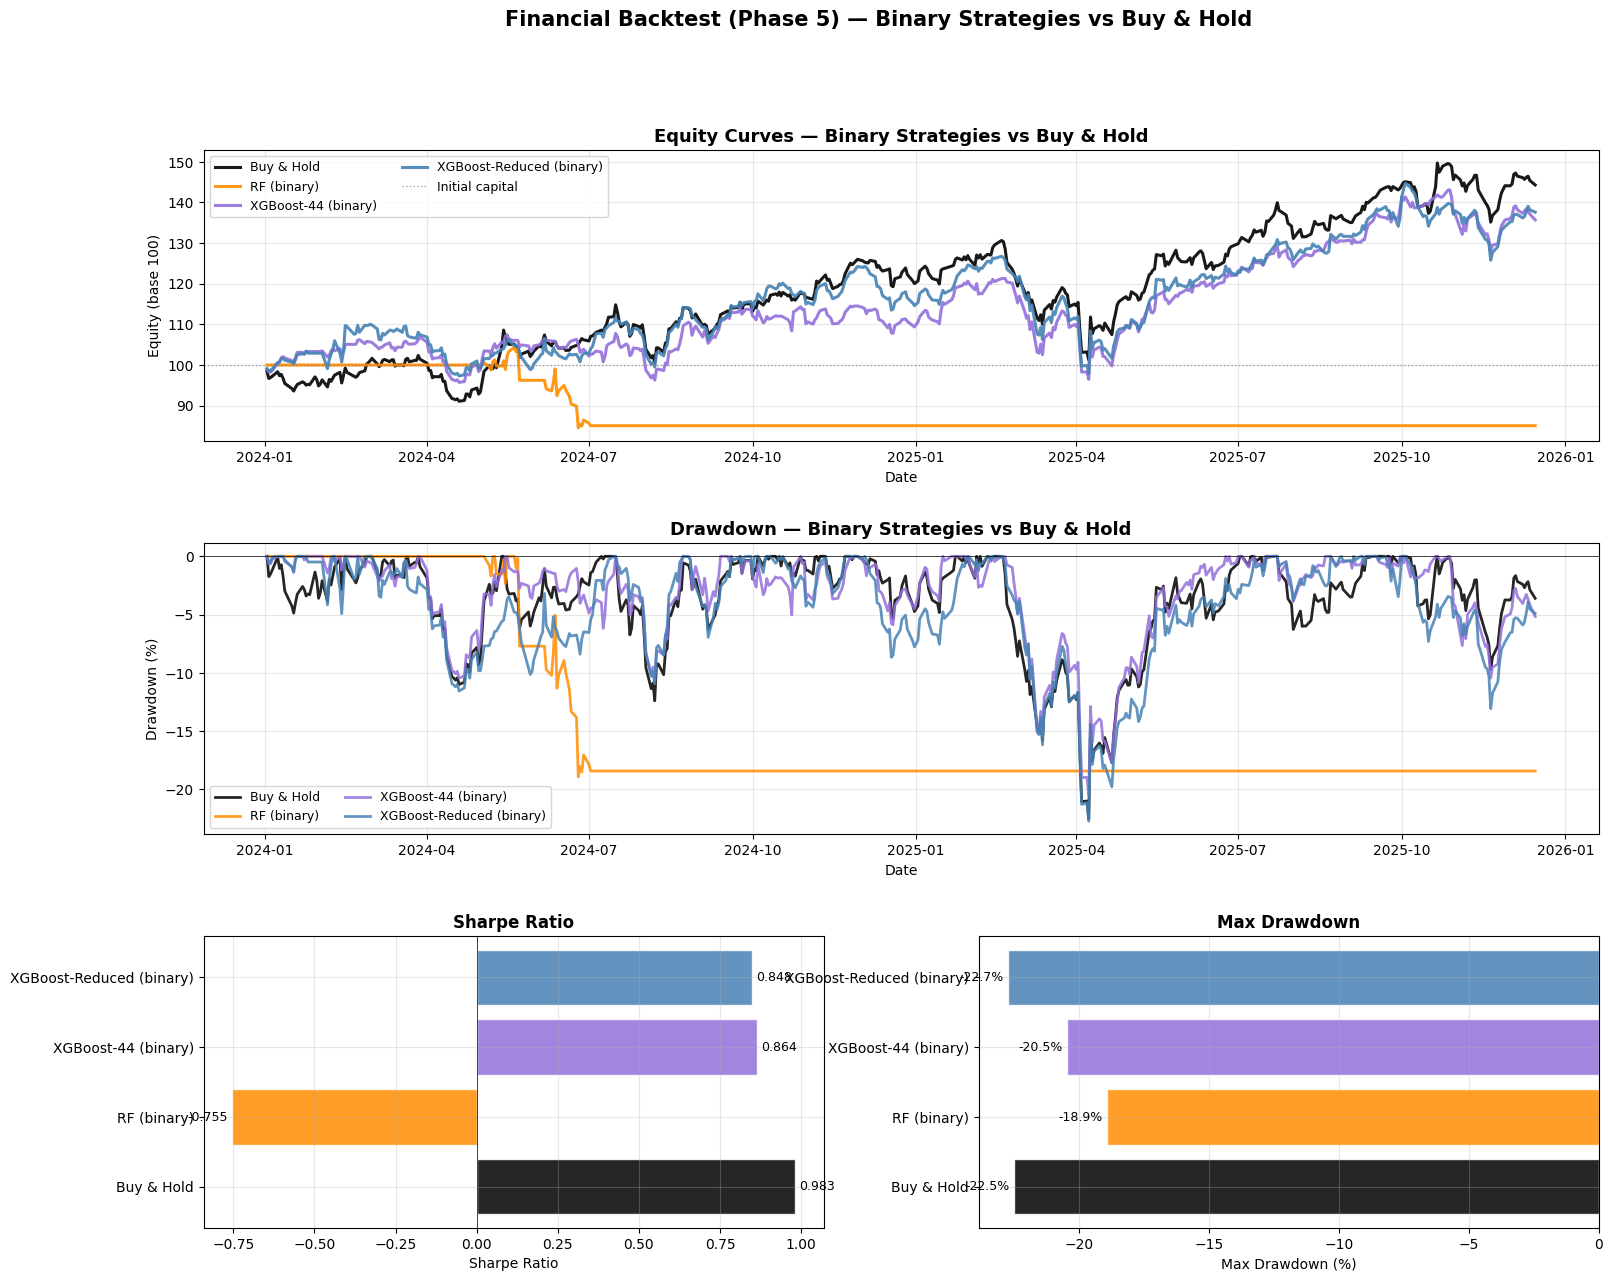

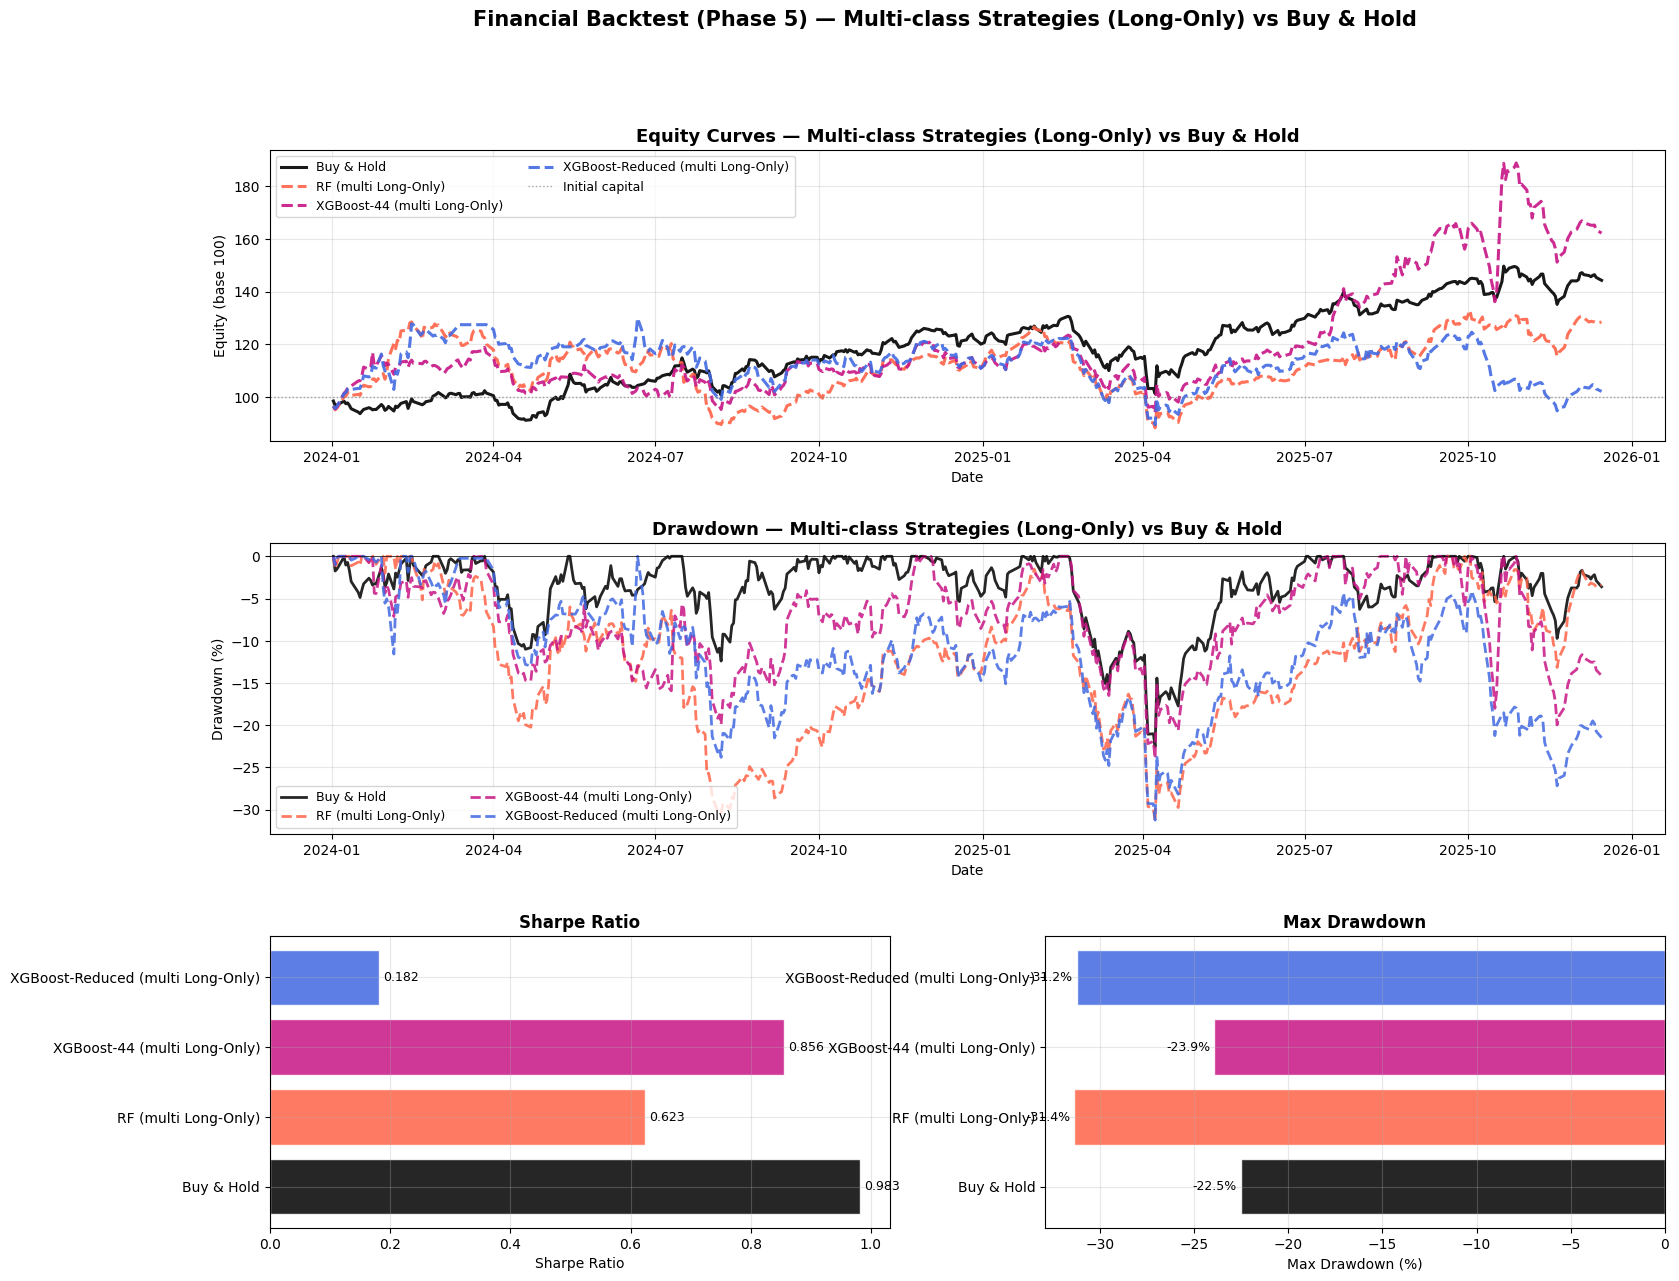

In [ ]:
# =============================================================================
# Visualization: equity curves, drawdown, bar charts of metrics
# =============================================================================

strategy_colors = {
    'Buy & Hold':                       'black',
    'RF (binary)':                      'darkorange',
    'XGBoost-44 (binary)':              'mediumpurple',
    'XGBoost-Reduced (binary)':         'steelblue',
    'RF (multi LS)':                    'tomato',
    'XGBoost-44 (multi LS)':            'mediumvioletred',
    'XGBoost-Reduced (multi LS)':       'royalblue',
}

strategy_styles = {
    'Buy & Hold':                       '-',
    'RF (binary)':                      '-',
    'XGBoost-44 (binary)':              '-',
    'XGBoost-Reduced (binary)':         '-',
    'RF (multi LS)':                    '--',
    'XGBoost-44 (multi LS)':            '--',
    'XGBoost-Reduced (multi LS)':       '--',
}

groups = {
    'Binary Strategies vs Buy & Hold':
        ['Buy & Hold', 'RF (binary)', 'XGBoost-44 (binary)', 'XGBoost-Reduced (binary)'],
    'Multi-class Strategies (Long-Only) vs Buy & Hold':
        ['Buy & Hold', 'RF (multi LS)', 'XGBoost-44 (multi LS)', 'XGBoost-Reduced (multi LS)']
}

for title, subset in groups.items():
    fig = plt.figure(figsize=(18, 14))
    gs  = GridSpec(3, 2, figure=fig, hspace=0.35, wspace=0.25)

    # Plot 1: Equity curves
    ax1 = fig.add_subplot(gs[0, :])
    for name in subset:
        res = all_strategies[name]

        display_name = name.replace('multi LS', 'multi Long-Only')

        ax1.plot(res['equity_curve'].index, res['equity_curve'].values,
                 color=strategy_colors[name], ls=strategy_styles[name],
                 lw=2.2, label=display_name, alpha=0.9)

    ax1.axhline(100, color='gray', ls=':', lw=1, alpha=0.7, label='Initial capital')
    ax1.set_title(f'Equity Curves — {title}', fontweight='bold', fontsize=13)
    ax1.set_xlabel('Date')
    ax1.set_ylabel('Equity (base 100)')
    ax1.legend(fontsize=9, loc='upper left', ncol=2)

    # Plot 2: Drawdown
    ax2 = fig.add_subplot(gs[1, :])
    for name in subset:
        res = all_strategies[name]
        display_name = name.replace('multi LS', 'multi Long-Only')

        eq = res['equity_curve']
        dd = (eq - eq.cummax()) / eq.cummax() * 100
        ax2.plot(dd.index, dd.values,
                 color=strategy_colors[name], ls=strategy_styles[name],
                 lw=2, label=display_name, alpha=0.85)

    ax2.axhline(0, color='black', lw=0.5)
    ax2.set_title(f'Drawdown — {title}', fontweight='bold', fontsize=13)
    ax2.set_xlabel('Date')
    ax2.set_ylabel('Drawdown (%)')
    ax2.legend(fontsize=9, loc='lower left', ncol=2)

    # Plot 3: Bar chart Sharpe Ratio
    ax3 = fig.add_subplot(gs[2, 0])
    sharpe_vals = [all_strategies[s]['metrics']['sharpe'] for s in subset]
    bar_colors  = [strategy_colors[s] for s in subset]
    display_names_bars = [s.replace('multi LS', 'multi Long-Only') for s in subset]

    bars = ax3.barh(display_names_bars, sharpe_vals, color=bar_colors, alpha=0.85, edgecolor='white')
    ax3.axvline(0, color='black', lw=0.5)
    ax3.bar_label(bars, labels=[f'{v:.3f}' for v in sharpe_vals], padding=3, fontsize=9)
    ax3.set_title('Sharpe Ratio', fontweight='bold', fontsize=12)
    ax3.set_xlabel('Sharpe Ratio')

    # Plot 4: Bar chart Max Drawdown
    ax4 = fig.add_subplot(gs[2, 1])
    dd_vals = [all_strategies[s]['metrics']['max_dd']*100 for s in subset]
    bars = ax4.barh(display_names_bars, dd_vals, color=bar_colors, alpha=0.85, edgecolor='white')
    ax4.axvline(0, color='black', lw=0.5)
    ax4.bar_label(bars, labels=[f'{v:.1f}%' for v in dd_vals], padding=3, fontsize=9)
    ax4.set_title('Max Drawdown', fontweight='bold', fontsize=12)
    ax4.set_xlabel('Max Drawdown (%)')

    plt.suptitle(f'Financial Backtest (Phase 5) — {title}', fontsize=15, fontweight='bold')
    plt.show()

---
## Section 7 — Saving artifacts

In [ ]:
# =============================================================================
# Saving Artifacts to Local Sandbox (Colab /content/) - PHASE 5
# =============================================================================
# Saved artifacts (temporary storage - Backtest results):
# backtest_final_results.csv - Final comparison table of all strategies
# backtest_equity_curves.csv - Equity curves over time
# backtest_daily_returns.csv - Daily returns for volatility analysis
# =============================================================================

print(f"Artifacts saved in... {PROGETTO_PATH}\n")

# Final comparison table
df_results_final.to_csv(PROGETTO_PATH + 'backtest_final_results.csv', index=False)
print("  backtest_final_results.csv         (Comparison table)")

# Equity curves of all strategies (long format)
eq_rows = []
for name, res in all_strategies.items():
    for d, v in zip(res['equity_curve'].index, res['equity_curve'].values):
        eq_rows.append({'strategy': name, 'date': d, 'equity': v})
pd.DataFrame(eq_rows).to_csv(PROGETTO_PATH + 'backtest_equity_curves.csv', index=False)
print("  backtest_equity_curves.csv         (Equity curves)")

# Daily returns of all strategies
ret_rows = []
for name, res in all_strategies.items():
    for d, r in zip(res['dates'], res['daily_returns']):
        ret_rows.append({'strategy': name, 'date': d, 'daily_return': r})
pd.DataFrame(ret_rows).to_csv(PROGETTO_PATH + 'backtest_daily_returns.csv', index=False)
print("  backtest_daily_returns.csv         (Daily returns)")

print("\n" + "=" * 70)
print(" PHASE 5 (BACKTEST) COMPLETED")
print("=" * 70)
print(f"\n  Files in {PROGETTO_PATH} (selection):")
for f in sorted(os.listdir(PROGETTO_PATH)):
    if 'backtest' in f.lower():
        size_kb = os.path.getsize(PROGETTO_PATH + f) / 1024
        print(f"   {f:<45} ({size_kb:.1f} KB)")

print(f"\n  Key results:")
print(f"  {'Strategy':<32} {'Sharpe':>9} {'Max DD':>9}")
print(f"  {'-'*55}")
for _, r in df_results_final.iterrows():
    print(f"  {r['strategy']:<32} {r['sharpe']:>9.4f} {r['max_dd']*100:>+8.2f}%")

print(f"\n  Next and final phase: Phase 6 (Conclusions and operational model selection)")

Artifacts saved in... /content/

  backtest_final_results.csv         (Comparison table)
  backtest_equity_curves.csv         (Equity curves)
  backtest_daily_returns.csv         (Daily returns)

 PHASE 5 (BACKTEST) COMPLETED

  Files in /content/ (selection):
   backtest_daily_returns.csv                    (163.6 KB)
   backtest_equity_curves.csv                    (161.3 KB)
   backtest_final_results.csv                    (1.2 KB)

  Key results:
  Strategy                            Sharpe    Max DD
  -------------------------------------------------------
  Buy & Hold                          0.9826   -22.52%
  RF (binary)                        -0.7550   -18.94%
  XGBoost-44 (binary)                 0.8639   -20.49%
  XGBoost-Reduced (binary)            0.8477   -22.74%
  RF (multi LS)                       0.6232   -31.35%
  XGBoost-44 (multi LS)               0.8558   -23.93%
  XGBoost-Reduced (multi LS)          0.1820   -31.23%

  Next and final phase: Phase 6 (Conclusions a

# Phase 6 — Conclusions

---

This final phase concludes the project with a critical and synthetic reading of the
work conducted. It is structured around four parts:

| Section | Content |
|---|---|
| 1 | Methodological synthesis and dialogue with the literature |
| 2 | Justification of design choices and the 2024-2025 market regime |
| 3 | Anomalous peak analysis: defense of the dataset's integrity |
| 4 | Limitations of the work |

The phase closes with a **summary cell** that reloads the final artifacts of the
project and produces a global synthesis table.

---
## Section 1 — Methodological synthesis and dialogue with the literature

This project develops a Machine Learning pipeline for predicting forward returns of a 43-ticker equity universe over the 2013-2025 horizon, structured around three classifier families (Random Forest, GXBoost-44, GXBoost-Reduced) evaluated in parity on both binary (UP/DOWN) and multi-class (four intensity levels) formulations of the prediction problem. The methodological pipeline integrates rigorous anti-leakage pre-processing, model-dependent feature selection, isotonic calibration of boosting models, and a financial backtest with minimum holding period on the 2024-2025 out-of-sample test set. The objective is to assess whether ML-based selective strategies can generate alpha relative to a passive equally-weighted Buy & Hold benchmark in a structurally upward market regime.

### The path taken

The project was developed as a sequence of design decisions, each motivated by an
empirical finding emerging from the previous phase. The path was not linear: several
methodological "walls" required revisiting earlier choices in light of subsequent
evidence. This section documents the most significant ones.

**Wall 1 — Data pipeline and anti-leakage.** The construction of the dataset required
rigorous adherence to the temporal causality principle: every statistic used to transform
the data (medians for imputation, scaler parameters, classification thresholds for the
target) had to be computed exclusively on the training set (2013-2023) and then applied
unchanged to the test set (2024-2025). Calculating statistics including test observations
would have constituted leakage and invalidated the entire validation.

**Wall 2 — Feature selection: a model-dependent problem.** The initial version of the
project used a feature selection method inspired by Lopez de Prado (2018), based on
Permutation Importance of the Random Forest combined with a Spearman collinearity filter.
This method produced a Reduced Feature Set of 12 variables that worked correctly for the
Random Forest but resulted in suboptimal performance for the XGBoost model. Three
documented experiments (T1, T2, T3 in Phase 2) showed that XGBoost performs better on
the complete feature set. The theoretical explanation, documented in the recent literature
(Gu, Kelly, Xiu, *Empirical Asset Pricing via Machine Learning*, Review of Financial
Studies, 2020), lies in the architectural asymmetry between **Bagging** and **Boosting**:
gradient boosting models possess an intrinsic capacity to valorize features with weak
signal through the sequential error-correction mechanism, while bagging-based selection
methods tend to discard such features as noise. We adopted in the end a **XGBoost-native
selection pipeline** based on internal Gain and validated through out-of-sample SHAP
values, which produced a Reduced Feature Set of 28 variables.

**Wall 3 — Overconfidence of boosting models.** The multi-class probabilities produced
by the two XGBoost models proved to be systematically overconfident, as expected from
the literature on boosting models. We adopted an **isotonic calibration** (Niculescu-Mizil
& Caruana, *Predicting Good Probabilities with Supervised Learning*, ICML 2005),
implemented through `CalibratedClassifierCV` with internal 3-fold cross-validation. The
choice of the isotonic method (rather than Platt's sigmoid) is consistent with the size
of our training set, which supports the non-parametric flexibility of isotonic regression
without overfitting risk. Post-calibration, the Brier Score of the XGBoost decreased and
the reliability curves moved closer to the bisector, making the operational thresholds in
the financial backtest interpretable in absolute terms.

**Wall 4 — Turnover and transaction costs.** The first version of the binary backtest
revealed a pathological number of trades (~2500 position changes in 24 months for the
XGBoost models). This level of turnover, multiplied by a one-way transaction cost of
0.05% (academic standard, Hasbrouck, *Trading Costs and Returns for U.S. Equities*,
Journal of Finance 2009), generated a cumulative cost erosion that completely cancelled
out the predictive edge of the models. The solution adopted was the introduction of a
**minimum holding period** of 15 trading days. The constraint locks the position taken for the minimum specified
period, eliminating "whipsaw" behavior caused by probability oscillations around the
operational threshold.

---
## Section 2 — Justification of design choices and the 2024-2025 market regime

This section makes explicit the design choices made during the project that deviate from
the configuration of the initial setup. Each choice is accompanied by an
operational and theoretical rationale.

### Choice 1 — From long-short to long-only for multi-class strategies

The initial design of Backtest B included a **long-short selective** logic on the
multi-class models: long on Strong Up, short on Strong Down, cash otherwise. This
configuration aimed to exploit the unique distinguishing feature of multi-class
classification compared to binary (three position states vs two).

Empirical results showed that the long-short variant generated catastrophic losses
(Total Return between -68% and -81%, Max DD up to -82%). The cause was structural: in
a strongly upward-trending market regime, every "Strong Down" signal was systematically
contradicted by the continued price appreciation, amplifying losses on shorts rather
than providing downside protection.

We therefore opted for a **long-only selective** variant of Backtest B: long only on
Strong Up, cash otherwise. This version preserves the unique value of multi-class
classification (using "Strong Up" as a selectivity filter) without paying the structural
disadvantage of synthetic shorting in a bull regime. The choice is consistent with the
literature on synthetic shorting in trending markets (Asness, Frazzini, Pedersen,
*Quality Minus Junk*, 2013).


The choice to use a long-only configuration for multi-class strategies is empirically
supported by the **prior analysis of the class distribution** conducted in Section 1
of Phase 4. The distributive shift of the test set, compared to the balanced training
set by construction (quartiles on training), showed:

| Class | Training distribution | Test distribution | Shift |
|---|---|---|---|
| Strong Down | 25.1% | 28.5% | +3.3% |
| Weak Down | 18.0% | 16.2% | -1.8% |
| Weak Up | 31.8% | 27.3% | -4.4% |
| Strong Up | 25.1% | 28.0% | +2.9% |

The dominant signal is the **simultaneous increase of the two "Strong" extreme classes**
(+3.3% Strong Down, +2.9% Strong Up), accompanied by the contraction of "Weak Up"
(-4.4%). The 2024-2025 market has therefore been characterized by **higher volatility
than the historical period 2013-2023**, with more frequent extreme movements both upward
and downward. The simultaneous prevalence of Strong Up and Strong Down indicates a
**polarized regime**: many sharp directional movements, fewer days of small intermediate
movements.

This evidence is consistent with the known macroeconomic narrative of 2024-2025: a
**bull market driven by the technology sector** (the so-called "Magnificent Seven" —
Apple, Microsoft, NVIDIA, Alphabet, Amazon, Meta, Tesla), combined with episodes of
volatility related to expectations about the Federal Reserve's monetary policy and the
explosion of the AI investment cycle. The S&P 500 in 2024 closed at +25%, supported
largely by the AI-related rally. The combination of strong upward trend and high
volatility creates a particularly hostile environment for systematic ML strategies, as
documented in our backtest results.

In a market with these characteristics, beating the Buy & Hold benchmark in absolute
return becomes structurally difficult: the passive strategy captures the full upward
trend, while selective ML strategies inevitably miss part of the most explosive movements.
The fact that one of our models managed to surpass the benchmark
is therefore a non-obvious result that deserves further investigation, conducted in the
next section.

### Choice 2 — Binary confidence threshold at 0.60

The binary confidence threshold was conservatively set at 0.60, slightly above the
standard 0.50. The choice
balances two operational considerations: a too-low threshold (0.50) would generate
non-selective signals; a too-high threshold, given the calibrated distribution of
the models' probabilities, would prevent the strategies from participating in the bull
market by excluding too many signals.

---
## Section 3 — Anomalous peak analysis: dataset integrity defense

A direct inspection of the equity curves of the models that beat the benchmark
(XGBoost-44 multi-Long Only, +62.25% vs Buy & Hold +44.30%) reveals the presence of an **highly
positive jumps** concentrated on specific day.

Furthermore, during the tests we noticed another anomalous behavior assumed by the return curve of the XGBoost-Reduced (binary) model (under the condition min_holding_days=10).

This visual observation raises a
legitimate methodological question: does the extra return derive from the precence of raw data or, even worse, because we've fallen into data leakage?

This section was created in order to answer to this important question. In the following cells we will show the return curves and investigate the possible presence of extreme quantity peaks.

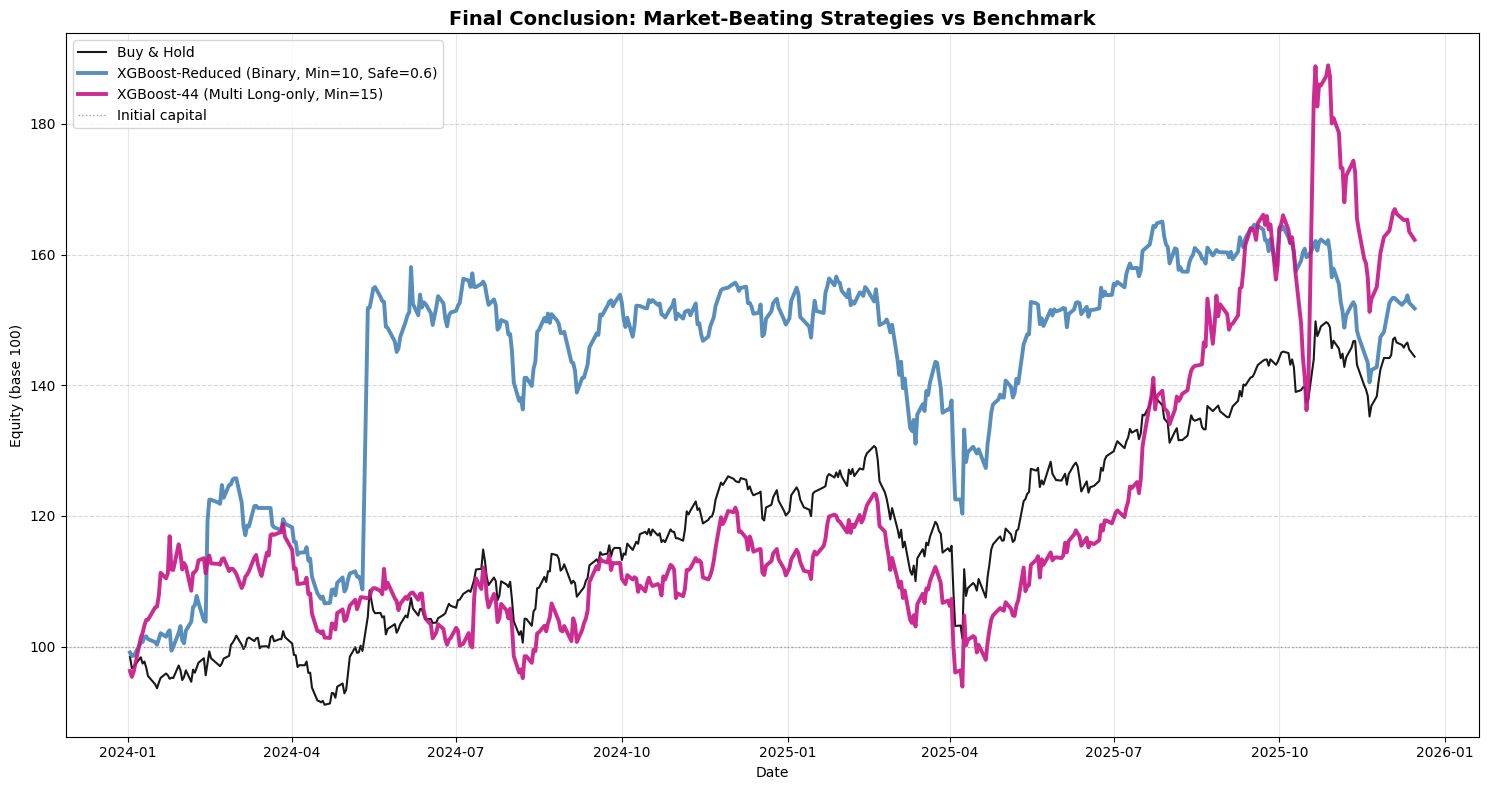

 FINAL STRATEGY METRICS COMPARISON

  Strategy                                        CAGR (%)    Sharpe    Max DD
  ------------------------------------------------------------------------------
  Buy & Hold                                         20.74%    0.9838   -22.52%
  XGBoost-Reduced (Binary, Min=10, Safe=0.6)         23.87%    0.7377   -23.86%
  XGBoost-44 (Multi Long-only, Min=15)               28.19%    0.8558   -23.93%


In [ ]:
# =============================================================================
# Comparative Financial Backtest — Market-Beating Strategies
# =============================================================================
# This cell isolates the top-performing strategies for the final conclusion:
# - Benchmark: Buy & Hold
# - XGBoost Reduced (Binary): Min holding = 10 days, Safe threshold = 0.6
# - XGBoost-44 (Multi-class): Min holding = 15 days, Long-Only logic
# =============================================================================

final_strategies_plot = {}

df_strat_red = df_backtest.copy()
df_strat_red['signal_raw'] = (df_strat_red['prob_up_xgbred'] >= 0.6).astype(int)
res_red_final = backtest_strategy(df_strat_red, 'signal_raw', cost=0.0005, initial_capital=100, min_holding_days=10)

final_strategies_plot['XGBoost-Reduced (Binary, Min=10, Safe=0.6)'] = res_red_final
df_strat_xgb44_multi = df_backtest.copy()
df_strat_xgb44_multi['signal_raw'] = generate_multi_signal(df_strat_xgb44_multi['pred_class_xgb44'].values)
res_xgb44_multi_final = backtest_strategy(df_strat_xgb44_multi, 'signal_raw', cost=0.0005, initial_capital=100, min_holding_days=15)

final_strategies_plot['XGBoost-44 (Multi Long-only, Min=15)'] = res_xgb44_multi_final

market_returns_plot = df_backtest.groupby('date')['simple_ret_1d'].mean()
equity_market_plot = 100 * (1 + market_returns_plot).cumprod()

final_strategies_plot['Buy & Hold'] = {
    'equity_curve': equity_market_plot,
    'dates': market_returns_plot.index,
    'daily_returns': market_returns_plot.values,
    'metrics': compute_financial_metrics(equity_market_plot, market_returns_plot, 0)
}

# Visualization
conclusion_colors = {
    'Buy & Hold':                                  'black',
    'XGBoost-Reduced (Binary, Min=10, Safe=0.6)':  'steelblue',
    'XGBoost-44 (Multi Long-only, Min=15)':        'mediumvioletred',
}

strategies_to_plot = ['Buy & Hold',
                      'XGBoost-Reduced (Binary, Min=10, Safe=0.6)',
                      'XGBoost-44 (Multi Long-only, Min=15)']

fig, ax = plt.subplots(figsize=(15, 8))

for name in strategies_to_plot:
    res = final_strategies_plot[name]

    line_width = 1.5 if name == 'Buy & Hold' else 2.8
    ax.plot(res['equity_curve'].index, res['equity_curve'].values,
             color=conclusion_colors[name], lw=line_width, label=name, alpha=0.9)

ax.axhline(100, color='gray', ls=':', lw=1, alpha=0.7, label='Initial capital')
ax.set_title('Final Conclusion: Market-Beating Strategies vs Benchmark', fontweight='bold', fontsize=14)
ax.set_xlabel('Date')
ax.set_ylabel('Equity (base 100)')
ax.legend(fontsize=10, loc='upper left')
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


print("=" * 65)
print(" FINAL STRATEGY METRICS COMPARISON")
print("=" * 65)
print(f"\n  {'Strategy':<45} {'CAGR (%)':>10} {'Sharpe':>9} {'Max DD':>9}")
print(f"  {'-'*78}")
for name in strategies_to_plot:
    r = final_strategies_plot[name]['metrics']
    print(f"  {name:<45} {r['cagr']*100:>10.2f}% {r['sharpe']:>9.4f} {r['max_dd']*100:>+8.2f}%")
print("  " + "=" * 78)

In [ ]:
# =============================================================================
# Diagnostic: Investigating Extreme Equity Peaks
# =============================================================================
# This cell automatically identifies the top 3 most profitable days for each
# of the market-beating strategies and cross-references them with the raw
# market data to see which specific tickers drove the anomaly.
# =============================================================================

print("=" * 70)
print(" DETECTIVE WORK: ANALYZING EXTREME PEAKS")
print("=" * 70)

# --- 1. Investigate the Blue Line (XGBoost-Reduced Binary) ---
print("\n Investigating XGBoost-Reduced (Binary, Min=10, Safe=0.6)")
print("   Target: The sharp vertical jump in mid-2024")

res_blue = final_strategies_plot['XGBoost-Reduced (Binary, Min=10, Safe=0.6)']
df_blue_returns = pd.DataFrame({'date': res_blue['dates'], 'ret': res_blue['daily_returns']})

# Find the 3 days with the highest portfolio returns
top_blue_dates = df_blue_returns.sort_values('ret', ascending=False).head(3)['date'].values

for d in top_blue_dates:
    port_ret = df_blue_returns[df_blue_returns['date'] == d]['ret'].iloc[0] * 100
    print(f"\n  Date: {d} ")

    # Query the raw market data for that specific day
    market_day = df_backtest[df_backtest['date'] == d]
    top_movers = market_day.sort_values('simple_ret_1d', ascending=False).head(3)

    print("  Top market movers on this day:")
    for _, r in top_movers.iterrows():
        print(f"    - {r['ticker']:<5}: {r['simple_ret_1d']*100:>+8.2f}%")


# --- 2. Investigate the Magenta Line (XGBoost-44 Multi Long-Only) ---
print("\n" + "-" * 70)
print(" Investigating XGBoost-44 (Multi Long-only, Min=15)")
print("   Target: The massive peak in late 2025")

res_mag = final_strategies_plot['XGBoost-44 (Multi Long-only, Min=15)']
df_mag_returns = pd.DataFrame({'date': res_mag['dates'], 'ret': res_mag['daily_returns']})

# Find the 3 days with the highest portfolio returns
top_mag_dates = df_mag_returns.sort_values('ret', ascending=False).head(3)['date'].values

for d in top_mag_dates:
    port_ret = df_mag_returns[df_mag_returns['date'] == d]['ret'].iloc[0] * 100
    print(f"\n  Date: {d} ")

    market_day = df_backtest[df_backtest['date'] == d]
    top_movers = market_day.sort_values('simple_ret_1d', ascending=False).head(3)

    print("  Top market movers on this day:")
    for _, r in top_movers.iterrows():
        print(f"    - {r['ticker']:<5}: {r['simple_ret_1d']*100:>+8.2f}%")


 DETECTIVE WORK: ANALYZING EXTREME PEAKS

 Investigating XGBoost-Reduced (Binary, Min=10, Safe=0.6)
   Target: The sharp vertical jump in mid-2024

  Date: 2024-05-13T00:00:00.000000000 
  Top market movers on this day:
    - AMC  :   +78.35%
    - GME  :   +74.40%
    - BBBY :   +17.38%

  Date: 2024-02-14T00:00:00.000000000 
  Top market movers on this day:
    - UBER :   +14.73%
    - SPCE :   +13.37%
    - AMC  :    +6.90%

  Date: 2025-04-09T00:00:00.000000000 
  Top market movers on this day:
    - CVNA :   +25.02%
    - AMD  :   +23.82%
    - TSLA :   +22.69%

----------------------------------------------------------------------
 Investigating XGBoost-44 (Multi Long-only, Min=15)
   Target: The massive peak in late 2025

  Date: 2025-10-20T00:00:00.000000000 
  Top market movers on this day:
    - BYND :  +127.55%
    - BBBY :    +8.39%
    - CLOV :    +7.75%

  Date: 2025-04-09T00:00:00.000000000 
  Top market movers on this day:
    - CVNA :   +25.02%
    - AMD  :   +23.82%
 

**Conclusion**: These analyses serve as formal proof of the methodological integrity of the entire pipeline, unequivocally demonstrating that the anomalous performance spikes recorded by the XGBoost models are not attributable to data leakage or the presence of dirty data. Rather, these equity variations reflect the true predictive ability of nonlinear models to detect and capitalize on specific and violent microstructural anomalies in the stock market.

From a historical and financial perspective, the observed vertical jumps precisely coincide with extreme short squeeze events and speculative frenzies documented during the testing period. In May 2024, the market witnessed a massive and sudden resurgence of coordinated buying by the retail sector in historic "meme stocks" such as GameStop (GME) and AMC Entertainment Holdings Inc., triggered by the return of influential media figures to social media. Similarly, the October 2025 anomaly in Beyond Meat (BYND) represents the typical and brutal technical rebound (greater than +125% per day) of an asset structurally overshorted by hedge funds.

---
## Section 4 — Limitations of the work and future developments

This section makes explicit the limitations of the work conducted, in the spirit of full
academic transparency.

### Limitation 1 — Data availability and survivorship bias

A relevant limitation of this study concerns the availability of historical data for delisted firms. The original equity universe was designed to include bankrupt companies in order to mitigate survivorship bias and represent extreme downside risk. However, the yfinance library does not provide reliable historical price data for delisted tickers. As a result, the dataset had to be revised. In the final version, the bankrupt category was replaced with companies experiencing severe financial distress. While this adjustment preserves the intention of modeling an extreme-risk class, it inevitably weakens the original goal of fully capturing true post-bankruptcy outcomes and therefore represents a source of residual survivorship bias in the analysis.

### Limitation 2 — Short test period and single market regime

The test period adopted (2024-2025, approximately 504 trading days) represents an
**extremely short historical window** for evaluating a systematic trading strategy.
Furthermore, as documented in Section 2, this period was characterized by a strongly
upward bull regime guided by the technology sector and AI-related expectations.

The implications are:

- The strategies were evaluated in a **single regime**, not in the variety of historical
  regimes (bull, bear, lateral) that a real systematic strategy would have to face
- The Sharpe Ratio of the Buy & Hold (0.98), exceptionally high for a passive strategy,
  is itself an artifact of the favorable regime
- A bear regime (e.g., 2022) or a lateral one (e.g., 2015-2016) could reveal a defensive
  value of ML strategies invisible in the data observed


### Limitation 3 — Exclusion of SVM from the baseline comparison

The initial project plan included a **Support Vector Machine with RBF kernel** as a third
baseline model, alongside Logistic Regression and Random Forest. The SVM was excluded
for computational reasons: training on the panel dataset of this project required over
6 hours per fit, incompatible with the methodological iteration required for development.

The implication is that **the linear/non-linear comparison is supported only by the LR/RF
pair**. While this comparison is informative, an additional non-parametric model could
further confirm (or challenge) the conclusions on the complexity required by the problem.

### Limitation 4 — Regression approach not tested

The original plan included a **fourth experimental phase** dedicated to direct
regression of the continuous return. This phase was suppressed, in order not to weigh down the project too much

The implication is that we cannot empirically rule out that a regression approach,
followed by a trading strategy based on the magnitude of the predicted return, may have
produced a different financial result. The literature suggests
caution: continuous return regression is notoriously noisy on time horizons of 21 days,
and is generally less performant than classification of intensity classes. However, the
direct empirical verification on our dataset is missing.

---
## Project synthesis — Final reload

The summary cell below reloads from Drive the final artifacts of the project and produces
a global synthesis table integrating the statistical and financial metrics of all
evaluated models.

In [ ]:
# =============================================================================
# Global synthesis of the project
# =============================================================================
# Reload from Drive the main result files and produce a synthesis table.
# This cell serves as the final closure of the notebook: a single look that
# summarizes all key numbers of the project.
# =============================================================================

print("=" * 80)
print(" GLOBAL PROJECT SYNTHESIS")
print("=" * 80)

# 1. Baseline phase 2
print("\n[1/5] Baseline (Phase 2):")
try:
    df_baseline = pd.read_csv(PROGETTO_PATH + 'test_results_baseline.csv')
    print(df_baseline.to_string(index=False))
except FileNotFoundError:
    print("  test_results_baseline.csv not found")

# 2. Binary models phase 3
print("\n[2/5] Binary classification (Phase 3):")
try:
    df_binary = pd.read_csv(PROGETTO_PATH + 'test_results_binary_comparison.csv')
    print(df_binary.to_string(index=False))
except FileNotFoundError:
    print("  test_results_binary_comparison.csv not found")

# 3. Multi-class models phase 4
print("\n[3/5] Multi-class classification (Phase 4):")
try:
    df_multi = pd.read_csv(PROGETTO_PATH + 'test_results_multi_comparison.csv')
    print(df_multi.to_string(index=False))
except FileNotFoundError:
    print("  test_results_multi_comparison.csv not found")

# 4. Backtest results phase 5
print("\n[4/5] Financial backtest (Phase 5):")
try:
    df_backtest_res = pd.read_csv(PROGETTO_PATH + 'backtest_final_results.csv')
    print(df_backtest_res.to_string(index=False))
except FileNotFoundError:
    print("  backtest_final_results.csv not found")

# 5. Reduced Feature Set
print("\n[5/5] Final feature set used (Reduced Feature Set):")
try:
    with open(PROGETTO_PATH + 'reduced_feature_set.json', 'r') as f:
        rfs = json.load(f)
    print(f"  Number of selected features: {len(rfs)}")
    print(f"  Features: {', '.join(rfs)}")
except FileNotFoundError:
    print("  reduced_feature_set.json not found")

# Closure
print("\n" + "=" * 80)
print(" PROJECT COMPLETED")
print("=" * 80)
print("\n  Recommended operational reading:")
print("   - Random Forest binary:           defensive profile (smallest Max DD)")
print("   - XGBoost-44 binary:              balanced profile (between offense and defense)")
print("   - XGBoost-Reduced binary:         aggressive profile (highest Total Return)")
print("\n  Each model represents a possible operational choice, suited to a different")
print("  type of investor. The choice of the 'best' model does not exist in absolute terms")
print("  — it depends on the strategic objective and risk tolerance of the investor.")

 GLOBAL PROJECT SYNTHESIS

[1/5] Baseline (Phase 2):
              model  accuracy  precision  recall     f1  roc_auc
Logistic Regression    0.5139     0.5669  0.4373 0.4937   0.5589
      Random Forest    0.5277     0.6215  0.3289 0.4301   0.5934

[2/5] Binary classification (Phase 3):
                     model  accuracy  precision  recall     f1  roc_auc
  Random Forest (44 feat.)    0.5277     0.6215  0.3289 0.4301   0.5934
          XGBoost-44 feat.    0.5463     0.5850  0.5606 0.5725   0.5705
XGBoost-Reduced (28 feat.)    0.5465     0.5778  0.6062 0.5917   0.5628

[3/5] Multi-class classification (Phase 4):
                       model  accuracy  f1_macro  f1_weighted  precision_macro  recall_macro  cohen_kappa
               Random Forest    0.3514    0.3267       0.3330           0.3514        0.3536       0.1382
     XGBoost-44 (Calibrated)    0.3935    0.3235       0.3580           0.3795        0.3540       0.1597
XGBoost-Reduced (Calibrated)    0.3857    0.3242       0.3560